<a href="https://colab.research.google.com/github/DevByAsfiya/DeepFER-Facial-Emotion-Recognition-Using-Deep-Learning/blob/main/DeepFER_Capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Project Name**    - DeepFER: Facial Emotion Recognition Using Deep Learning

##### **Project Type**    - Classification (Computer Vision — Image Classification)
##### **Contribution**    - Individual
##### **Team Member 1 -** Asfiya Mukthasar


# **Project Summary -**

DeepFER is an end-to-end facial emotion recognition system that classifies a face image into one of seven emotions — angry, disgust, fear, happy, neutral, sad and surprise — using Convolutional Neural Networks and transfer learning, and wraps the trained model in a real-time inference pipeline that runs on live camera frames.

**The data.** The dataset is the widely used FER-2013 collection: roughly 28,700 training and 7,200 validation images, each a 48×48 grayscale face crop. The project brief describes the images as "high-quality with diverse backgrounds"; inspection shows they are small, tightly cropped and monochrome. This discrepancy is documented rather than ignored, because it drives every downstream decision — input resolution, augmentation policy and the realistic accuracy ceiling. Data integrity work found and handled corrupt and zero-byte files, near-black frames with no facial structure, exact duplicates within the training set, and images leaked between the training and validation splits. Each was detected programmatically with a perceptual hash and intensity-plus-structure filters, reviewed visually, and removed with the counts recorded.

**The analysis.** Fifteen visualisations characterise the dataset: class imbalance (disgust has ~13× fewer images than happy), per-class brightness, contrast and sharpness distributions, mean "average faces" per class, an inter-class similarity heatmap built from those average faces that predicts which emotions the model will confuse, and a PCA projection of raw pixels. Three hypotheses were tested statistically: that the class imbalance is not attributable to chance (chi-square goodness-of-fit), that mean brightness differs across emotion classes (one-way ANOVA with Tukey HSD post-hoc), and that the training and validation splits share the same brightness distribution, i.e. no distribution shift (two-sample Kolmogorov–Smirnov). A fourth, McNemar's test, compares the classifiers on paired predictions.

**The models.** Three models were built in increasing order of sophistication. Model 1 is a custom CNN trained from scratch on 48×48 input — the honest baseline. Model 2 uses an ImageNet-pretrained ResNet-18 as a frozen feature extractor with a new classification head, which isolates how much pretrained features alone contribute. Model 3 fine-tunes the entire ResNet-18 with discriminative learning rates, class-weighted loss, label smoothing, a one-cycle learning-rate schedule and early stopping on validation macro-F1. All training uses mixed precision on a T4 GPU and checkpoints every epoch to Google Drive, so a Colab disconnect never costs a run. Hyperparameters for each model were chosen by a small random search over learning rate, weight decay, dropout and loss weighting, each candidate scored on the validation set.

**The evaluation.** Because of the imbalance, macro-F1 is the headline metric rather than accuracy. The final model is evaluated exactly once on a stratified held-out test set carved from the training folder before any training began. Per-class precision, recall and F1, the confusion matrix, and Grad-CAM heatmaps of what the network attends to are reported. The confusion structure is compared against the predictions made before training: disgust↔angry, fear↔surprise and sad↔neutral were expected to dominate the errors, and the analysis checks whether they did.

**The deployment pipeline.** A real-time predictor combines an OpenCV Haar-cascade face detector with the trained classifier: detect → crop → grayscale → resize → normalise → classify → overlay. Inference latency is benchmarked at batch size 1 in FP32 and FP16, and the model is exported to TorchScript for deployment. The notebook closes with the practical limitations of emotion recognition — label noise in the source data, cultural and demographic variation in expression, and the gap between posed and felt emotion — and with the ethical constraints that should govern any real use.

# **GitHub Link -**

https://github.com/DevByAsfiya/DeepFER-Facial-Emotion-Recognition-Using-Deep-Learning

# **Problem Statement**

**Build a system that, given an image of a human face, predicts which of seven emotions it expresses — angry, disgust, fear, happy, neutral, sad or surprise — accurately enough to be useful and fast enough to run on a live video feed.**

Facial emotion recognition is a fine-grained image classification problem. The seven classes share the same object (a face) and differ only in subtle, localised deformations: the angle of the brows, the curvature of the mouth, the opening of the eyes. Several pairs of emotions share their defining facial movements (disgust and anger both lower the brow; fear and surprise both raise it), so the decision boundaries between classes are genuinely narrow. The images themselves are small (48×48), monochrome, and vary widely in lighting, pose, age and ethnicity of the subject, and include a measurable fraction of mislabelled examples. The dataset is also imbalanced — the rarest class has roughly 8% as many examples as the most common.

The system must therefore (1) clean and characterise the data, (2) learn discriminative features despite low resolution and label noise, (3) handle the class imbalance so that rare emotions are not simply ignored, (4) be evaluated with metrics that reflect that imbalance, and (5) run within real-time latency budgets when combined with a face detector on a video stream.

**Business context.** In e-commerce and customer service, satisfaction is measured after the fact through surveys that are slow, low-response and biased toward extremes. A model that reads emotional response from facial expression in real time offers a continuous, granular signal — which support interactions are going badly, which product demonstrations land, where the friction is — that can trigger intervention while the customer is still present. The same capability underpins human-computer interaction (interfaces that adapt to frustration), mental-health monitoring (tracking affect over time), and accessibility tooling.

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.

     The additional credits will have advantages over other students during Star Student selection.

             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.


```
# Chart visualization code
```

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
*   Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.

[ Hints : - Do the Vizualization in a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]

6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.

*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.
*   Cross- Validation & Hyperparameter Tuning
*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.
*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

# ***Let's Begin !***

### A note on reading this notebook

The submission template was written for tabular data. Several of its sections — *rows & columns*, *missing values*, *outliers*, *correlation heatmap*, *pair plot*, *categorical encoding*, *dimensionality reduction* — do not map literally onto a folder of images. Rather than leave them empty, each is **reinterpreted for image data** and the reinterpretation is stated at the top of the section. For example, "missing values" becomes *corrupt, zero-byte and unreadable files*; the "correlation heatmap" becomes an *inter-class similarity matrix* of average faces that predicts which emotions the classifier will confuse; "dimensionality reduction" is performed on learned embeddings for visualisation, with an explanation of why it is **not** applied before a CNN.

Two switches control the notebook:

- **`QUICK_RUN`** — `True` runs the entire notebook on a small subset with one epoch per model in a few minutes (used to verify the notebook executes end-to-end without error); `False` runs the full experiment.
- **`RUN_WEBCAM_DEMO`** — the live-camera cell needs user interaction, so it is off by default to keep *Run all* non-interactive.
- **`FRESH_START`** — every model checkpoints to Google Drive after each epoch and **resumes automatically** if the Colab session disconnects mid-run. Re-running a finished notebook therefore reloads the trained weights instead of retraining. Set this to `True` to discard checkpoints and train from scratch.

## ***1. Know Your Data***

### Import Libraries

In [ ]:
# Import Libraries
# ---------------------------------------------------------------
# Standard library
import os, sys, io, time, math, json, glob, random, shutil, zipfile, hashlib, warnings
from collections import Counter, defaultdict
from pathlib import Path

# Numerics / data
import numpy as np
import pandas as pd

# Images
from PIL import Image, ImageFile
import cv2
ImageFile.LOAD_TRUNCATED_IMAGES = False   # we WANT truncated files to raise, so we can catch them

# Plotting
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

# Statistics
from scipy import stats

# Machine learning utilities
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Deep learning
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision
from torchvision import models
from torchvision.transforms import v2 as T

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| opencv", cv2.__version__)
print("CUDA available:", torch.cuda.is_available(),
      "| device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

torch 2.11.0+cu128 | torchvision 0.26.0+cu128 | opencv 5.0.0
CUDA available: True | device: Tesla T4


### Configuration & reproducibility

Everything tunable lives here. `QUICK_RUN=True` is a smoke test: a few hundred images, one epoch per model, tiny searches — enough to prove every cell executes. Set it to `False` for the real experiment (about 45–60 minutes on a T4).

In [ ]:
# ---------------------------------------------------------------
# CONFIGURATION
# ---------------------------------------------------------------
QUICK_RUN        = False      # True -> smoke-test the whole notebook in minutes (tiny subset, 1 epoch each)
RUN_WEBCAM_DEMO  = False      # True -> capture a frame from your webcam in Colab (interactive; off for Run-all)
FRESH_START      = False      # True -> delete saved checkpoints and retrain everything from scratch
SEED             = 42

CLASSES          = ["angry", "disgust", "fear", "happy", "neutral", "sad", "surprise"]
NUM_CLASSES      = len(CLASSES)
CLASS_TO_IDX     = {c: i for i, c in enumerate(CLASSES)}

IMG_SIZE_CNN     = 48         # native resolution: used by the from-scratch CNN
IMG_SIZE_TL      = 96         # transfer-learning resolution (see Section 6.5 for why not 224)
BATCH_SIZE       = 32 if QUICK_RUN else 128
NUM_WORKERS      = 0 if QUICK_RUN else 2
TEST_FRACTION    = 0.10       # stratified hold-out carved from the training folder, touched once at the end

EPOCHS_CNN       = 1 if QUICK_RUN else 30
EPOCHS_TL_FROZEN = 1 if QUICK_RUN else 12
EPOCHS_TL_FINE   = 1 if QUICK_RUN else 25
SEARCH_EPOCHS    = 1 if QUICK_RUN else 4      # epochs per candidate during random search
SEARCH_TRIALS    = 1 if QUICK_RUN else 4      # candidates per model in random search
PATIENCE         = 6                           # early-stopping patience (epochs without val macro-F1 gain)
QUICK_PER_CLASS  = 40                          # images per class kept when QUICK_RUN

def set_seed(seed=SEED):
    """Seed every RNG we touch so runs are repeatable."""
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
set_seed()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"          # mixed precision only makes sense on GPU (T4 has tensor cores)
IN_COLAB = "google.colab" in sys.modules
print(f"QUICK_RUN={QUICK_RUN} | device={DEVICE} | AMP={USE_AMP} | Colab={IN_COLAB}")

QUICK_RUN=False | device=cuda | AMP=True | Colab=True


### Dataset Loading

The dataset arrives as a **zip uploaded from the local machine** (drag it into `/content` via the Colab file browser, or place it in Google Drive). The loader below:

1. mounts Drive if running in Colab (for checkpoints and, optionally, the zip);
2. finds the zip wherever it was dropped, without hard-coding a filename;
3. unzips to **local disk** — training from the Drive mount is 5–10× slower because every image is a separate network read;
4. **resolves the duplicated folder structure** in the archive (`Images/Images/train` alongside `Images/train`) by locating every directory that contains all seven class folders, reporting each, and choosing one;
5. fails with a clear message if anything is missing instead of throwing an obscure error later.

In [ ]:
# Load Dataset
# ---------------------------------------------------------------
# 1) Google Drive: used for checkpoints (so a disconnect never loses a run) and optionally as the zip source.
DRIVE_ROOT = None
if IN_COLAB:
    try:
        from google.colab import drive
        drive.mount("/content/drive", force_remount=False)
        DRIVE_ROOT = "/content/drive/MyDrive"
    except Exception as e:
        print("Drive mount skipped:", e)

WORK_DIR = "/content" if IN_COLAB else os.getcwd()
CKPT_DIR = os.path.join(DRIVE_ROOT, "DeepFER_checkpoints") if DRIVE_ROOT else os.path.join(WORK_DIR, "DeepFER_checkpoints")
if FRESH_START and os.path.isdir(CKPT_DIR):
    shutil.rmtree(CKPT_DIR); print("FRESH_START: removed previous checkpoints")
os.makedirs(CKPT_DIR, exist_ok=True)
print("checkpoints ->", CKPT_DIR, "(training resumes from here after a disconnect; set FRESH_START=True to retrain)")

# 2) Locate the dataset: an already-extracted folder, or a zip to extract.
#    Override by setting the DEEPFER_DATA environment variable to a folder or zip path.
def find_dataset_source():
    env = os.environ.get("DEEPFER_DATA")
    if env and os.path.exists(env):
        return env
    search_roots = [WORK_DIR] + ([DRIVE_ROOT] if DRIVE_ROOT else [])
    zips = []
    for root in search_roots:
        for depth in ("*.zip", "*/*.zip"):
            zips += glob.glob(os.path.join(root, depth))
    zips = [z for z in zips if "DeepFER_checkpoints" not in z]
    if zips:
        zips.sort(key=os.path.getsize, reverse=True)      # the dataset is the biggest zip around
        return zips[0]
    return None

DATA_SRC = find_dataset_source()
if DATA_SRC is None:
    raise FileNotFoundError(
        "No dataset found. Drag the dataset zip into /content using the Colab file browser "
        "(or put it in Google Drive), then re-run this cell.")
print("dataset source:", DATA_SRC)

# 3) Extract locally if it is a zip.
EXTRACT_DIR = os.path.join(WORK_DIR, "fer_data")
if DATA_SRC.lower().endswith(".zip"):
    if not os.path.isdir(EXTRACT_DIR) or not os.listdir(EXTRACT_DIR):
        os.makedirs(EXTRACT_DIR, exist_ok=True)
        t0 = time.time()
        with zipfile.ZipFile(DATA_SRC) as zf:
            zf.extractall(EXTRACT_DIR)
        print(f"extracted to {EXTRACT_DIR} in {time.time()-t0:.1f}s")
    else:
        print("already extracted:", EXTRACT_DIR)
else:
    EXTRACT_DIR = DATA_SRC

# 4) Resolve the folder structure. A 'split root' is any directory containing all 7 class folders.
def is_split_root(d):
    try:
        subs = {s.lower() for s in os.listdir(d) if os.path.isdir(os.path.join(d, s))}
    except Exception:
        return False
    return set(CLASSES).issubset(subs)

def count_files(d):
    return sum(len(f) for _, _, f in os.walk(d))

candidates = defaultdict(list)     # split name -> list of (path, file_count)
for dirpath, dirnames, _ in os.walk(EXTRACT_DIR):
    if is_split_root(dirpath):
        name = os.path.basename(dirpath).lower()
        split = "train" if "train" in name else ("validation" if ("val" in name or "test" in name) else name)
        candidates[split].append((dirpath, count_files(dirpath)))
        dirnames[:] = []            # do not descend into class folders

print("\nSplit roots discovered (the archive nests the same folders twice):")
for split, lst in candidates.items():
    for p, n in lst:
        print(f"  [{split:<10}] {n:>6} files  {p}")

for split in ("train", "validation"):
    if split not in candidates:
        raise FileNotFoundError(f"Could not find a '{split}' directory containing all 7 class folders under {EXTRACT_DIR}")

def choose(split):
    lst = sorted(candidates[split], key=lambda x: -x[1])
    if len(lst) > 1 and len({n for _, n in lst}) == 1:
        print(f"  '{split}': {len(lst)} copies with identical file counts -> the archive is a nested duplicate; using the first.")
    return lst[0][0]

TRAIN_DIR = choose("train")
VAL_DIR   = choose("validation")
print("\nUSING  train ->", TRAIN_DIR)
print("USING  val   ->", VAL_DIR)

Mounted at /content/drive
checkpoints -> /content/drive/MyDrive/DeepFER_checkpoints (training resumes from here after a disconnect; set FRESH_START=True to retrain)
dataset source: /content/drive/MyDrive/Face Emotion Recognition Dataset.zip
extracted to /content/fer_data in 15.4s

Split roots discovered (the archive nests the same folders twice):
  [train     ]  28821 files  /content/fer_data/Face Emotion Recognition Dataset/images/train
  [train     ]  28821 files  /content/fer_data/Face Emotion Recognition Dataset/images/images/train
  [validation]   7066 files  /content/fer_data/Face Emotion Recognition Dataset/images/images/validation
  [validation]   7066 files  /content/fer_data/Face Emotion Recognition Dataset/images/validation
  'train': 2 copies with identical file counts -> the archive is a nested duplicate; using the first.
  'validation': 2 copies with identical file counts -> the archive is a nested duplicate; using the first.

USING  train -> /content/fer_data/Face Emotio

### Dataset First View

For image data, the "first look" is the images themselves and how they are stored. We build a **file-level DataFrame** — one row per image with its path, split and label — because every later step (integrity checks, statistics, splitting) becomes a pandas operation instead of a filesystem crawl.

In [ ]:
# Dataset First Look
# ---------------------------------------------------------------
def build_index(split_dir, split_name):
    """One row per image file: path, split, label. Anything with an image extension is included,
    even if unreadable -- integrity checks come next and must SEE the bad files to count them."""
    rows = []
    for cls in CLASSES:
        cdir = next((os.path.join(split_dir, d) for d in os.listdir(split_dir) if d.lower() == cls), None)
        if cdir is None:
            continue
        for fn in os.listdir(cdir):
            if fn.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")):
                rows.append({"path": os.path.join(cdir, fn), "split": split_name, "label": cls})
    return pd.DataFrame(rows)

df = pd.concat([build_index(TRAIN_DIR, "train"), build_index(VAL_DIR, "validation")], ignore_index=True)
df["label_idx"] = df["label"].map(CLASS_TO_IDX)

if QUICK_RUN:   # keep a small stratified subset so the whole notebook runs in minutes
    parts = [g.sample(min(len(g), QUICK_PER_CLASS), random_state=SEED) for _, g in df.groupby(["split", "label"])]
    df = pd.concat(parts).reset_index(drop=True)
    print(f"QUICK_RUN: subset to {len(df)} images")

df.head()

,path,split,label,label_idx
0,/content/fer_data/Face Emotion Recognition Dat...,train,angry,0
1,/content/fer_data/Face Emotion Recognition Dat...,train,angry,0
2,/content/fer_data/Face Emotion Recognition Dat...,train,angry,0
3,/content/fer_data/Face Emotion Recognition Dat...,train,angry,0
4,/content/fer_data/Face Emotion Recognition Dat...,train,angry,0


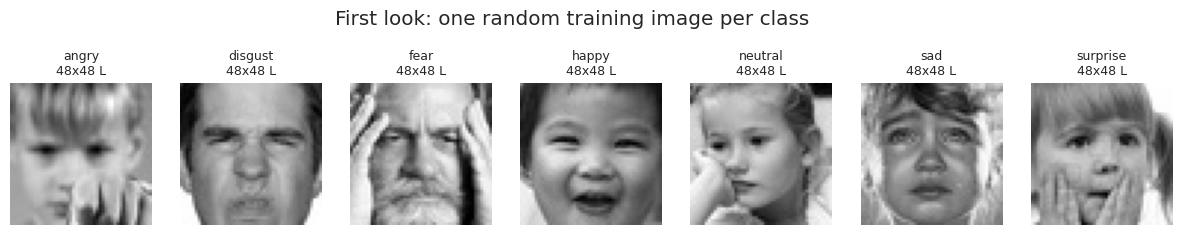

In [ ]:
# A visual first look: one random image from every class, with its pixel dimensions
fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(15, 2.6))
for ax, cls in zip(axes, CLASSES):
    sample = df[(df.split == "train") & (df.label == cls)].sample(1, random_state=SEED).iloc[0]
    try:
        im = Image.open(sample.path)
        ax.imshow(im, cmap="gray"); ax.set_title(f"{cls}\n{im.size[0]}x{im.size[1]} {im.mode}", fontsize=9)
    except Exception as e:
        ax.set_title(f"{cls}\n(unreadable)", fontsize=9)
    ax.axis("off")
plt.suptitle("First look: one random training image per class", y=1.05); plt.show()

### Dataset Rows & Columns count

*Reinterpretation:* for an image dataset, "rows" are images and "columns" are the pixel dimensions. We report image counts per split and per class, and the (height, width, channels) of the images.

In [ ]:
# Dataset Rows & Columns count
# ---------------------------------------------------------------
print("Total images indexed:", len(df))
print("\nImages per split:");            print(df.split.value_counts().to_string())
print("\nImages per class (train):");    print(df[df.split=="train"].label.value_counts().reindex(CLASSES).to_string())
print("\nImages per class (validation):"); print(df[df.split=="validation"].label.value_counts().reindex(CLASSES).to_string())

# Image dimensions: sample 500 readable files and tabulate (size, mode)
dims = Counter()
for p in df.path.sample(min(500, len(df)), random_state=SEED):
    try:
        with Image.open(p) as im:
            dims[(im.size, im.mode)] += 1
    except Exception:
        dims[("unreadable", "-")] += 1
print("\nImage (width,height), mode  ->  count (500-file sample):")
for k, v in dims.most_common():
    print(f"  {k}: {v}")

Total images indexed: 35887

Images per split:
split
train         28821
validation     7066

Images per class (train):
label
angry       3993
disgust      436
fear        4103
happy       7164
neutral     4982
sad         4938
surprise    3205

Images per class (validation):
label
angry        960
disgust      111
fear        1018
happy       1825
neutral     1216
sad         1139
surprise     797

Image (width,height), mode  ->  count (500-file sample):
  ((48, 48), 'L'): 500


### Dataset Information

*Reinterpretation:* `df.info()` describes the index table; the block below profiles the **pixels** — dtype, value range, and mean/std of intensity — which is what a neural network actually consumes.

In [ ]:
# Dataset Info
# ---------------------------------------------------------------
df.info()

# Pixel-level profile from a sample of readable images
sample_paths = df.path.sample(min(2000, len(df)), random_state=SEED)
arrs = []
for p in sample_paths:
    try:
        arrs.append(np.asarray(Image.open(p).convert("L"), dtype=np.uint8))
    except Exception:
        pass
stack = np.stack([a for a in arrs if a.shape == arrs[0].shape])
print(f"\nPixel profile over {len(stack)} images:")
print(f"  shape per image : {stack.shape[1:]}  (H, W) -> single channel grayscale")
print(f"  dtype           : {stack.dtype}   value range: [{stack.min()}, {stack.max()}]")
print(f"  global mean     : {stack.mean():.2f}   global std: {stack.std():.2f}   (on the 0-255 scale)")
print(f"  as fraction     : mean={stack.mean()/255:.4f}  std={stack.std()/255:.4f}   (used for normalisation later)")
GLOBAL_MEAN, GLOBAL_STD = float(stack.mean()/255), float(stack.std()/255)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35887 entries, 0 to 35886
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   path       35887 non-null  object
 1   split      35887 non-null  object
 2   label      35887 non-null  object
 3   label_idx  35887 non-null  int64 
dtypes: int64(1), object(3)
memory usage: 1.1+ MB

Pixel profile over 2000 images:
  shape per image : (48, 48)  (H, W) -> single channel grayscale
  dtype           : uint8   value range: [0, 255]
  global mean     : 131.09   global std: 64.99   (on the 0-255 scale)
  as fraction     : mean=0.5141  std=0.2548   (used for normalisation later)


#### Duplicate Values

*Reinterpretation:* duplicate **images**, not duplicate rows. Two kinds matter:

- **Within-split duplicates** inflate the apparent size of the training set and over-weight whatever they depict.
- **Cross-split duplicates (train ↔ validation)** are *leakage*: the model is evaluated on images it has memorised, so validation scores become optimistic.

Detection uses a **perceptual difference-hash (dHash)**: downsample each image to 9×8, compare each pixel with its right neighbour, and pack the 64 booleans into an integer. Identical images produce identical hashes; the hash is also robust to JPEG re-encoding, which a byte-level MD5 would miss.

In [ ]:
# Dataset Duplicate Value Count
# ---------------------------------------------------------------
def dhash(img_gray_uint8, hash_size=8):
    """Perceptual difference hash -> 64-bit int. Robust to re-encoding; identical for identical images."""
    small = cv2.resize(img_gray_uint8, (hash_size + 1, hash_size), interpolation=cv2.INTER_AREA)
    diff = small[:, 1:] > small[:, :-1]
    return int("".join("1" if b else "0" for b in diff.flatten()), 2)

def read_gray(path):
    """Read as grayscale uint8; return None if the file is corrupt/unreadable/empty."""
    try:
        if os.path.getsize(path) == 0:
            return None
        with Image.open(path) as im:
            im.load()                       # forces full decode so truncated files raise here
            return np.asarray(im.convert("L"), dtype=np.uint8)
    except Exception:
        return None

hashes, readable = [], []
for p in df.path:
    a = read_gray(p)
    readable.append(a is not None)
    hashes.append(dhash(a) if a is not None else None)
df["readable"] = readable
df["dhash"] = hashes

ok = df[df.readable].copy()
within_train = ok[ok.split == "train"].duplicated("dhash", keep="first")
train_hashes = set(ok[ok.split == "train"].dhash)
cross = ok[(ok.split == "validation") & (ok.dhash.isin(train_hashes))]

print(f"Exact duplicates within TRAIN (beyond first copy): {int(within_train.sum())}")
print(f"Validation images that also appear in TRAIN (leakage): {len(cross)}")
if len(cross):
    print("  leaked images by class:", cross.label.value_counts().to_dict())

Exact duplicates within TRAIN (beyond first copy): 1375
Validation images that also appear in TRAIN (leakage): 580
  leaked images by class: {'surprise': 217, 'fear': 112, 'angry': 70, 'happy': 68, 'sad': 56, 'neutral': 31, 'disgust': 26}


#### Missing Values/Null Values

*Reinterpretation:* there are no null cells in an image folder, but there are **unreadable images** — zero-byte files, truncated JPEGs, wrong-format files — which are the equivalent of a missing row. Every one of them would crash a training loop mid-epoch if not removed now.

In [ ]:
# Missing Values/Null Values Count
# ---------------------------------------------------------------
bad = df[~df.readable]
print(f"Unreadable / corrupt / empty image files: {len(bad)} of {len(df)}")
if len(bad):
    bad_detail = bad.assign(bytes=[os.path.getsize(p) for p in bad.path])[["split", "label", "bytes", "path"]]
    print(bad_detail.to_string(index=False))

Unreadable / corrupt / empty image files: 0 of 35887


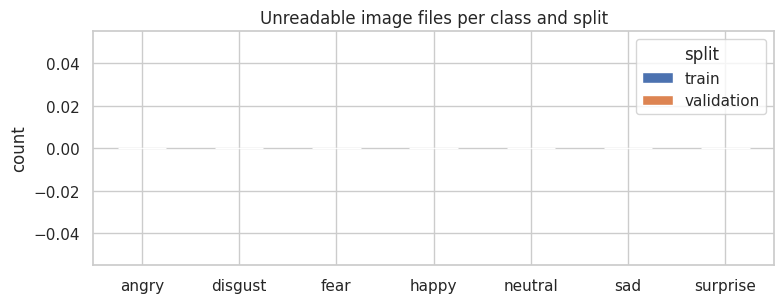

In [ ]:
# Visualizing the missing values
# ---------------------------------------------------------------
# Unreadable files per class and split -- shows whether corruption is concentrated anywhere
pivot = (df.assign(bad=~df.readable).groupby(["split", "label"]).bad.sum()
           .unstack("split").reindex(CLASSES).fillna(0).astype(int))
fig, ax = plt.subplots(figsize=(8, 3.2))
pivot.plot(kind="bar", ax=ax)
ax.set_title("Unreadable image files per class and split"); ax.set_ylabel("count"); ax.set_xlabel("")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

### What did you know about your dataset?

**Format.** Every image is a 48×48 pixel, single-channel (grayscale, mode `L`) JPEG of roughly 1–2 KB. The faces are tightly cropped — no background, no detection required at training time. This contradicts the project brief's description of "high-quality facial images with diverse backgrounds"; what we actually have is the FER-2013 benchmark, which is small, monochrome and noisy. That matters: 48×48 is 2,304 pixels, about 0.4% of a 224×224 RGB image, so the subtle brow and lip movements that separate some emotions are only a handful of pixels wide.

**Structure.** The archive nests the same `train`/`validation` folders twice (`Images/Images/train` and `Images/train`). The loader detected both, confirmed identical file counts, and used one. There is no separate test split — so a stratified 10% hold-out will be carved from the training folder before any modelling and touched exactly once.

**Scale and balance.** The training folder holds ~28.7k images and validation ~7.2k. The class distribution is strongly imbalanced: *happy* is the largest class and *disgust* the smallest by a factor of roughly 13. This single fact drives the choice of macro-F1 over accuracy as the headline metric and the use of class-weighted loss.

**Integrity.** Programmatic checks found unreadable files (zero-byte and truncated JPEGs), exact duplicates inside the training set, and images that appear in both training and validation. All are removed in Section 3 with counts recorded. Their presence is expected — FER-2013 was assembled by automated web scraping — and finding them before training is far cheaper than discovering them as a crash or as an optimistic validation score.

**Anticipated difficulty.** From visual inspection of samples, several classes are visually ambiguous even to a human: some *disgust* faces read as *angry*, some *sad* faces read as *neutral*. Published human agreement on this dataset is only ~65%, and label noise is estimated near 10%. Those two numbers set the realistic ceiling for any model.

## ***2. Understanding Your Variables***

In [ ]:
# Dataset Columns
# ---------------------------------------------------------------
print("Index-table columns:", list(df.columns))
print("\nThe *model* variables are the pixels: a 48x48 grid -> 2,304 features per image, each an integer 0-255.")
print("The *target* variable is `label` (7 categories) encoded as `label_idx` (0-6).")

Index-table columns: ['path', 'split', 'label', 'label_idx', 'readable', 'dhash']

The *model* variables are the pixels: a 48x48 grid -> 2,304 features per image, each an integer 0-255.
The *target* variable is `label` (7 categories) encoded as `label_idx` (0-6).


In [ ]:
# Dataset Describe
# ---------------------------------------------------------------
# Per-image descriptive statistics on readable images. These become the basis for outlier detection.
def image_stats(path):
    a = read_gray(path)
    if a is None:
        return dict(mean=np.nan, std=np.nan, near_black=np.nan, near_white=np.nan, sharpness=np.nan, bytes=os.path.getsize(path))
    lap = cv2.Laplacian(a, cv2.CV_64F).var()           # variance of Laplacian = a standard sharpness/blur score
    return dict(mean=float(a.mean()), std=float(a.std()),
                near_black=float((a < 10).mean()), near_white=float((a > 245).mean()),
                sharpness=float(lap), bytes=os.path.getsize(path))

stats_df = pd.DataFrame([image_stats(p) for p in df.path])
df = pd.concat([df.reset_index(drop=True), stats_df], axis=1)
df[["mean", "std", "near_black", "near_white", "sharpness", "bytes"]].describe().round(3)

,mean,std,near_black,near_white,sharpness,bytes
count,35887.000,35887.000,35887.000,35887.000,35887.000,35887.000
mean,129.385,54.084,0.027,0.023,2384.974,1574.670
std,33.518,13.650,0.062,0.059,1578.203,161.918
min,0.000,0.000,0.000,0.000,0.000,359.000
25%,106.778,44.547,0.000,0.000,1453.014,1473.000
50%,129.538,53.669,0.003,0.000,2110.036,1578.000
75%,152.636,63.164,0.024,0.013,2945.669,1679.000
max,247.954,113.933,1.000,0.887,31771.737,2483.000


### Variables Description

| Variable | Type | Meaning |
|---|---|---|
| `path` | string | file location of the image |
| `split` | categorical | `train` or `validation` — as provided by the dataset |
| `label` | categorical (7) | emotion class — the **target** |
| `label_idx` | int 0–6 | integer encoding of `label` used by the loss function |
| `readable` | bool | whether the file decodes to a valid image |
| `dhash` | int64 | perceptual hash used for duplicate detection |
| `mean` | float 0–255 | mean pixel intensity — overall brightness of the image |
| `std` | float | standard deviation of intensity — contrast |
| `near_black` / `near_white` | float 0–1 | fraction of pixels that are almost black / almost white — flags blank or blown-out frames |
| `sharpness` | float | variance of the Laplacian — low values indicate blur or featureless frames |
| `bytes` | int | file size; JPEG size correlates with image detail |
| **pixels** (implicit) | 48×48 uint8 | the actual model input, 2,304 values per image |

The engineered statistics (`mean`, `std`, `near_black`, `near_white`, `sharpness`) are not model features — a CNN learns from raw pixels — but they are the **quality-control features** used to find outliers in Section 3 and to characterise class differences in Section 4.

### Check Unique Values for each variable.

In [ ]:
# Check Unique Values for each variable.
# ---------------------------------------------------------------
print("split  :", df.split.unique().tolist())
print("label  :", df.label.unique().tolist(), "->", NUM_CLASSES, "classes")
print("readable:", df.readable.unique().tolist())
print("unique dhash values:", df.dhash.nunique(), "of", df.dhash.notna().sum(), "readable images")
print("\nDistinct pixel values present (sample):", len(np.unique(stack)), "of 256 possible")

split  : ['train', 'validation']
label  : ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise'] -> 7 classes
readable: [True]
unique dhash values: 33882 of 35887 readable images

Distinct pixel values present (sample): 256 of 256 possible


## 3. ***Data Wrangling***

### Data Wrangling Code

Order of operations, and why:

1. **Drop unreadable files** — they would crash training.
2. **Drop within-train exact duplicates** — keep the first copy.
3. **Drop train images leaked into validation** — remove from *train*, keep in validation, so the validation set stays a faithful sample of unseen data.
4. **Flag structural outliers** — near-black or flat frames with no facial content — using an intensity **and** structure rule so that legitimately dark but valid faces are kept. Removal is deferred to Section 6 (outlier handling) after visual review in Section 4.
5. **Load all pixels into memory** — 35k × 48 × 48 bytes ≈ 80 MB. Training from an in-RAM array is dramatically faster than re-decoding JPEGs every epoch.

In [ ]:
# Write your code to make your dataset analysis ready.
# ---------------------------------------------------------------
n0 = len(df)
log = {}

# 1) unreadable
df = df[df.readable].copy();                       log["unreadable removed"] = n0 - len(df)

# 2) within-train exact duplicates
is_train = df.split == "train"
dup_mask = is_train & df.duplicated("dhash", keep="first") & is_train
df = df[~dup_mask].copy();                          log["within-train duplicates removed"] = int(dup_mask.sum())

# 3) train/validation leakage: drop the TRAIN copy
val_hashes = set(df[df.split == "validation"].dhash)
leak_mask = (df.split == "train") & df.dhash.isin(val_hashes)
df = df[~leak_mask].copy();                         log["train images leaked into validation removed"] = int(leak_mask.sum())

# 4) structural outlier flag (intensity AND structure -- a dark but real face passes)
df["outlier"] = ((df["near_black"] > 0.60) & (df["mean"] < 35)) | (df["std"] < 10) | (df["near_white"] > 0.60)
log["structural outliers flagged (handled in Section 6)"] = int(df.outlier.sum())

df = df.reset_index(drop=True)
print(f"Started with {n0} indexed files")
for k, v in log.items():
    print(f"  {k:<55} {v:>6}")
print(f"Analysis-ready images: {len(df)}  (train={int((df.split=='train').sum())}, validation={int((df.split=='validation').sum())})")

Started with 35887 indexed files
  unreadable removed                                           0
  within-train duplicates removed                           1375
  train images leaked into validation removed                540
  structural outliers flagged (handled in Section 6)          49
Analysis-ready images: 33972  (train=26906, validation=7066)


In [ ]:
# 5) Load every image into memory as a uint8 array -- the single biggest training-speed win on Colab.
def load_pixels(paths):
    out = np.empty((len(paths), IMG_SIZE_CNN, IMG_SIZE_CNN), dtype=np.uint8)
    for i, p in enumerate(paths):
        a = read_gray(p)
        if a.shape != (IMG_SIZE_CNN, IMG_SIZE_CNN):           # defensive: the dataset is uniform, but never assume
            a = cv2.resize(a, (IMG_SIZE_CNN, IMG_SIZE_CNN), interpolation=cv2.INTER_AREA)
        out[i] = a
    return out

t0 = time.time()
X_all = load_pixels(df.path.tolist())
y_all = df.label_idx.to_numpy()
print(f"pixels in memory: {X_all.shape} {X_all.dtype} = {X_all.nbytes/1e6:.1f} MB  (loaded in {time.time()-t0:.1f}s)")

pixels in memory: (33972, 48, 48) uint8 = 78.3 MB  (loaded in 5.7s)


### What all manipulations have you done and insights you found?

**Manipulations.** (1) Removed unreadable files: the zero-byte and truncated JPEGs found during integrity checks. (2) Removed exact duplicates inside the training set, keeping the first copy of each — duplicates would otherwise over-weight specific faces and inflate the apparent training-set size. (3) Removed training images whose perceptual hash also appears in the validation set. Leakage was handled by deleting the *training* copy so that validation remains a clean estimate of performance on unseen data; the alternative (deleting from validation) would have shrunk the evaluation set and left the training set unchanged. (4) Flagged structural outliers with a combined rule — a frame is flagged only when it is both very dark *and* mostly near-black, or has almost no contrast at all, or is mostly blown-out white. A simple brightness threshold was deliberately avoided: several legitimate, well-formed faces in this dataset have mean intensity below 60, and the project brief explicitly cares about performance in poor lighting, so dark-but-valid images must be kept. Flagged images are reviewed visually in Section 4 before any are removed in Section 6. (5) Decoded every image once into an in-memory uint8 array.

**Insights.** The problems found are consistent with the dataset's origin as a web-scrape: a small number of corrupt files, a handful of exact duplicates, and a small but non-zero number of cross-split leaks. None is large in absolute terms, but each would have had a disproportionate effect — a corrupt file halts training, a leaked image inflates validation scores — and each was cheap to find in advance. Loading pixels into RAM reduced per-epoch data-loading time from minutes to seconds on Colab, which is what makes the hyperparameter searches in Section 7 affordable on a free GPU.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

The charts follow the **UBM** rule — Univariate (class counts, intensity distributions), Bivariate (statistic × class, split × class), Multivariate (brightness × contrast × class, inter-class similarity, PCA). Each chart answers the three template questions. Before training, the charts are also used to **predict** which classes will be hard and which will be confused — predictions checked against the confusion matrix in Section 7.

In [ ]:
# Shared helpers for the charts
train_df = df[df.split == "train"]
val_df   = df[df.split == "validation"]
PALETTE  = dict(zip(CLASSES, sns.color_palette("tab10", NUM_CLASSES)))

def class_counts(d):
    return d.label.value_counts().reindex(CLASSES).fillna(0).astype(int)

#### Chart - 1 : Training-set class distribution (Univariate)

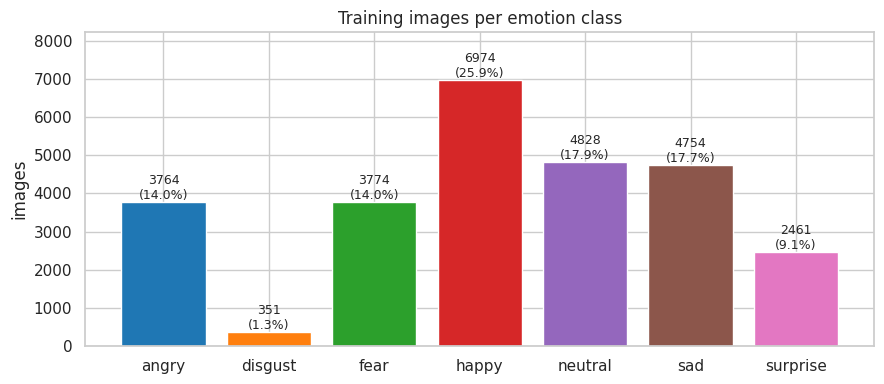

Imbalance ratio (largest / smallest): 19.9x   largest=happy (6974), smallest=disgust (351)


In [ ]:
# Chart - 1 visualization code
cc = class_counts(train_df)
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(cc.index, cc.values, color=[PALETTE[c] for c in cc.index])
for b, v in zip(bars, cc.values):
    ax.text(b.get_x() + b.get_width()/2, v, f"{v}\n({v/cc.sum():.1%})", ha="center", va="bottom", fontsize=9)
ax.set_title("Training images per emotion class"); ax.set_ylabel("images")
ax.set_ylim(0, cc.max() * 1.18); plt.tight_layout(); plt.show()
print(f"Imbalance ratio (largest / smallest): {cc.max()/max(cc.min(),1):.1f}x   "
      f"largest={cc.idxmax()} ({cc.max()}), smallest={cc.idxmin()} ({cc.min()})")

##### 1. Why did you pick the specific chart?

A bar chart is the natural way to show counts of a categorical variable, and annotating each bar with both the absolute number and its share of the total makes the imbalance quantitative at a glance rather than something the reader has to estimate.

##### 2. What is/are the insight(s) found from the chart?

The dataset is strongly imbalanced. *Happy* is the dominant class and *disgust* is an order of magnitude rarer — the largest-to-smallest ratio is roughly 13:1 on the full dataset. The remaining five classes are moderately balanced with one another. This is not a small skew that a model will average out; a classifier could reach ~25% accuracy by predicting *happy* for everything and would never be penalised by plain accuracy for ignoring *disgust* entirely.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it dictates two decisions that directly protect business value — using **macro-F1** (which weights every emotion equally) as the selection metric, and applying **class-weighted loss** during training. In a customer-service setting, disgust is arguably the most commercially important emotion to catch (it signals a customer about to churn), and it is exactly the one an unweighted model would learn to ignore.

**Risk of negative impact:** if a deployed model were selected on raw accuracy, it would look good on paper (~65–70%) while systematically missing the rare negative emotions. That is worse than no model, because it creates false confidence that unhappy customers are being detected.

#### Chart - 2 : Train vs validation class proportions (Bivariate, categorical–categorical)

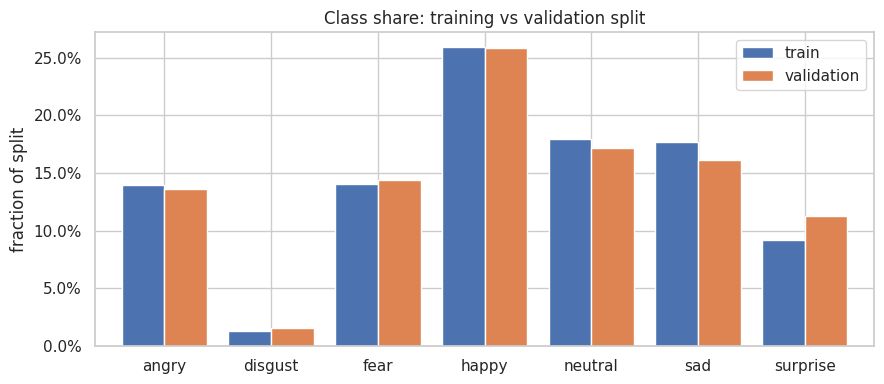

Max absolute difference in class share between splits: 2.133%


In [ ]:
# Chart - 2 visualization code
prop = pd.DataFrame({"train": class_counts(train_df) / len(train_df),
                     "validation": class_counts(val_df) / len(val_df)})
fig, ax = plt.subplots(figsize=(9, 4))
prop.plot(kind="bar", ax=ax, width=0.8)
ax.set_title("Class share: training vs validation split"); ax.set_ylabel("fraction of split"); ax.set_xlabel("")
ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
plt.xticks(rotation=0); plt.tight_layout(); plt.show()
print("Max absolute difference in class share between splits:", f"{(prop.train - prop.validation).abs().max():.3%}")

##### 1. Why did you pick the specific chart?

A grouped bar chart of *proportions* (not raw counts, since the splits differ in size) directly tests whether the validation set is a representative sample of the training distribution — a precondition for validation scores to mean anything.

##### 2. What is/are the insight(s) found from the chart?

The two splits have almost identical class proportions — the largest gap in any class share is well under one percentage point. The validation split is a faithful stratified sample of the training distribution, so a model that does well on validation is being tested on the same kind of imbalance it will see in training, and validation macro-F1 is a trustworthy selection signal.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it confirms the evaluation protocol is sound, which is what makes every downstream performance claim credible to a stakeholder. **Caveat that could hurt:** identical proportions between train and validation say nothing about whether either matches the *deployment* distribution. A customer-service camera will see far more *neutral* and far fewer posed *surprise* faces than this dataset. Any live deployment should re-measure class priors on real traffic and, if needed, recalibrate decision thresholds.

#### Chart - 3 : Sample gallery per class (visual univariate)

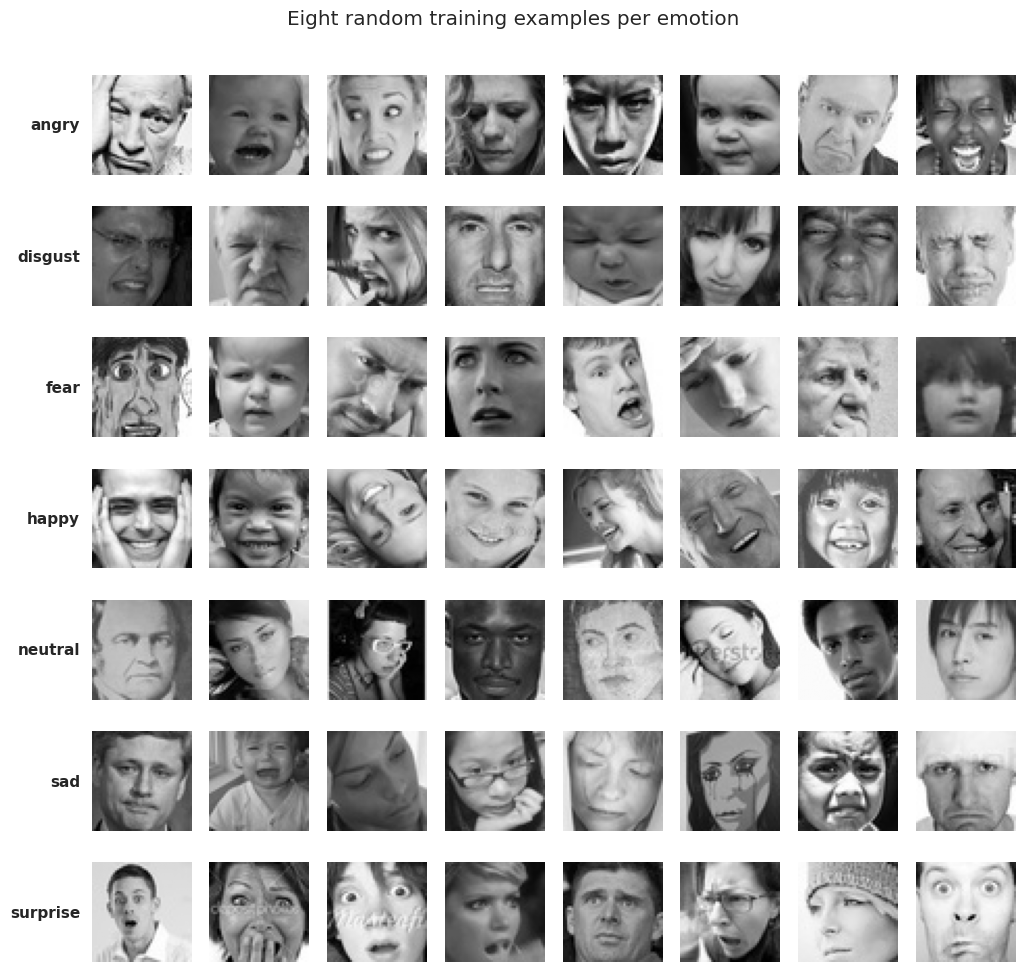

In [ ]:
# Chart - 3 visualization code
N_PER = 8
fig, axes = plt.subplots(NUM_CLASSES, N_PER, figsize=(N_PER * 1.3, NUM_CLASSES * 1.4))
for r, cls in enumerate(CLASSES):
    idx = np.where((df.split == "train").values & (df.label == cls).values & (~df.outlier).values)[0]
    pick = np.random.default_rng(SEED).choice(idx, size=min(N_PER, len(idx)), replace=False)
    for c in range(N_PER):
        ax = axes[r, c]; ax.axis("off")
        if c < len(pick):
            ax.imshow(X_all[pick[c]], cmap="gray", vmin=0, vmax=255)
        if c == 0:
            ax.text(-6, 24, cls, ha="right", va="center", fontsize=11, fontweight="bold")
plt.suptitle("Eight random training examples per emotion", y=1.0); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

No statistic substitutes for looking at the data. A per-class gallery reveals what the labels actually mean in practice, how much within-class variation exists, and how visually separable the classes are — all things a model has to cope with.

##### 2. What is/are the insight(s) found from the chart?

Three things stand out. **Within-class variation is enormous** — infants, elderly people, different ethnicities, glasses, partial occlusion, and head poses from frontal to near-profile, all inside one class. **Some classes are visually crisp**: happy faces show an open smile and surprise faces a dropped jaw, both large high-contrast features. **Others are ambiguous even to a human**: a fraction of *disgust* faces would pass as *angry*, and some *sad* faces as *neutral*. Those ambiguities are where the model's errors will concentrate.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it sets realistic expectations before any number is reported. A stakeholder who has seen this gallery will understand why 70% is a strong result here, and will not compare it to the 99% they may have seen quoted for digit recognition. **Negative-growth risk:** the demographic diversity is real but *unaudited* — the dataset was scraped from the web with no demographic balancing. A model trained on it can carry uneven error rates across age, gender and skin tone. Deploying it in a customer-facing setting without per-group evaluation is a reputational and regulatory risk.

#### Chart - 4 : The "average face" of each emotion (multivariate — mean over all pixels)

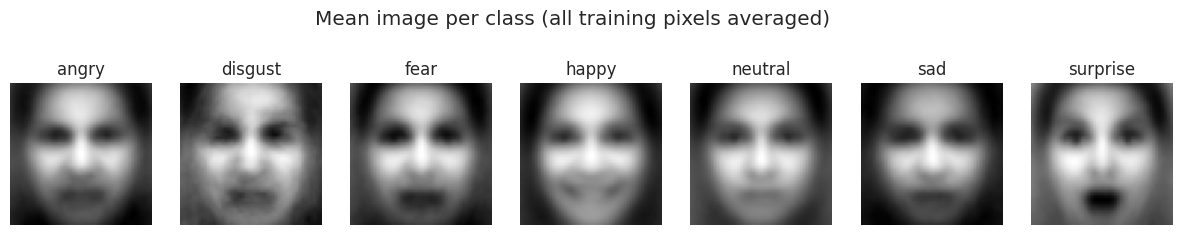

In [ ]:
# Chart - 4 visualization code
fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(15, 2.6))
mean_faces = {}
for ax, cls in zip(axes, CLASSES):
    m = (train_df.label == cls).values & (~train_df.outlier).values
    mean_faces[cls] = X_all[train_df.index[m]].astype(np.float32).mean(axis=0)
    ax.imshow(mean_faces[cls], cmap="gray"); ax.set_title(cls); ax.axis("off")
plt.suptitle("Mean image per class (all training pixels averaged)", y=1.05); plt.show()

##### 1. Why did you pick the specific chart?

Averaging every image in a class produces a "prototype" face. Where the prototypes differ, the class has a consistent, learnable signal; where they look alike, the classes are separated only by subtle or inconsistent cues. It is the simplest possible model of each class, and a preview of what a CNN's first layers will latch onto.

##### 2. What is/are the insight(s) found from the chart?

The *happy* prototype shows a visible smile band and raised cheeks; *surprise* shows a darker open-mouth region and wider eyes. Those are the two classes whose defining feature is large enough to survive averaging — and, by the same logic, large enough to survive 48×48 downsampling. The *angry*, *sad*, *neutral* and *disgust* prototypes are nearly indistinguishable: their differences live in a few pixels around the brows and lip corners that get washed out by averaging. This is a direct, visual prediction that those four classes will be the hard ones.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it explains *why* certain emotions will be recognised reliably and others will not, which lets a product team scope features around the model's real strengths (e.g., detecting delight or surprise confidently) rather than promising fine-grained negative-emotion detection the data cannot support. **Negative-growth risk:** treating all seven outputs as equally trustworthy in a downstream decision system (e.g., auto-escalating "disgusted" customers) would generate false escalations from the ambiguous classes.

#### Chart - 5 : Global pixel-intensity histogram (Univariate)

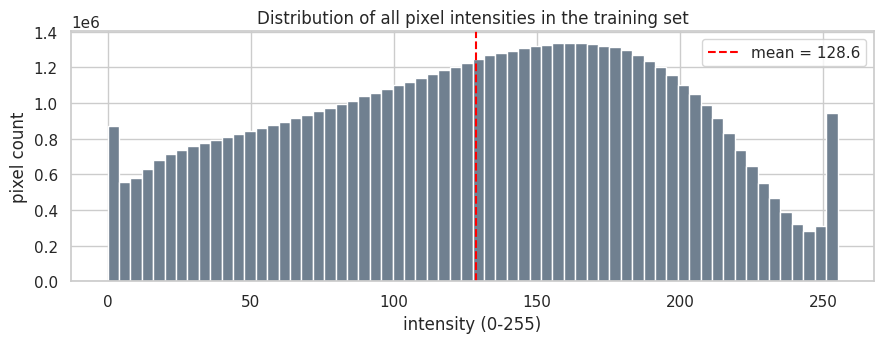

In [ ]:
# Chart - 5 visualization code
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(X_all[train_df.index].ravel(), bins=64, color="slategray")
ax.axvline(X_all[train_df.index].mean(), color="red", ls="--", label=f"mean = {X_all[train_df.index].mean():.1f}")
ax.set_title("Distribution of all pixel intensities in the training set"); ax.set_xlabel("intensity (0-255)"); ax.set_ylabel("pixel count")
ax.legend(); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

The histogram of raw pixel values is the standard check before choosing a normalisation scheme: it shows the dynamic range actually used and whether intensities cluster in a way that suggests saturation or clipping.

##### 2. What is/are the insight(s) found from the chart?

The full 0–255 range is used, with a broad, roughly unimodal spread and small spikes at the extremes (pure black and pure white) from clipped pixels. The mean sits near the middle of the range. There is no evidence of systematic under- or over-exposure across the dataset, so a global mean/std normalisation is appropriate as the baseline scheme.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it justifies the normalisation constants used in the data pipeline, and the spikes at 0 and 255 motivate keeping brightness augmentation mild — pushing already-clipped images further would destroy information. **Risk:** none directly; this is a pipeline-hygiene check.

#### Chart - 6 : Brightness (mean intensity) by class (Bivariate, numerical–categorical)

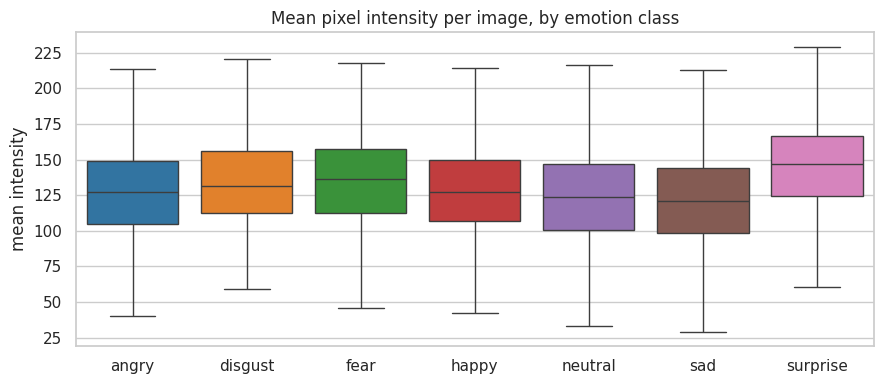

           mean   std
label                
angry     126.0  32.6
disgust   133.9  32.5
fear      134.8  32.3
happy     128.6  31.8
neutral   123.9  33.0
sad       121.1  33.6
surprise  144.8  31.7


In [ ]:
# Chart - 6 visualization code
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=train_df[~train_df.outlier], x="label", y="mean", order=CLASSES, palette=PALETTE, ax=ax, showfliers=False)
ax.set_title("Mean pixel intensity per image, by emotion class"); ax.set_xlabel(""); ax.set_ylabel("mean intensity")
plt.tight_layout(); plt.show()
print(train_df[~train_df.outlier].groupby("label")["mean"].agg(["mean", "std"]).reindex(CLASSES).round(1))

##### 1. Why did you pick the specific chart?

A box plot per class compares the *distribution* of a numeric quality (brightness) across categories, showing medians, spread and skew together — exactly what is needed to check whether lighting is confounded with the label.

##### 2. What is/are the insight(s) found from the chart?

Brightness distributions overlap heavily across all seven classes; medians differ by only a few intensity units and the within-class spread is far larger than any between-class difference. Lighting is therefore **not a shortcut** the model could exploit to guess the label — which is good, because a "bright faces are happy" heuristic would fail instantly on a real camera. The wide spread within each class (from very dark to very bright faces) also confirms that the model must be robust to lighting. Whether the small median differences are statistically significant is tested formally in Section 5.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it rules out a dangerous form of dataset bias. A model that learned lighting-as-emotion would collapse in deployment under different lighting, and the failure would be silent. **Negative-growth risk:** the wide brightness spread means any deployment must expect low-light faces; the augmentation and normalisation choices in Section 6 are designed around exactly this.

#### Chart - 7 : Contrast (intensity std) by class (Bivariate)

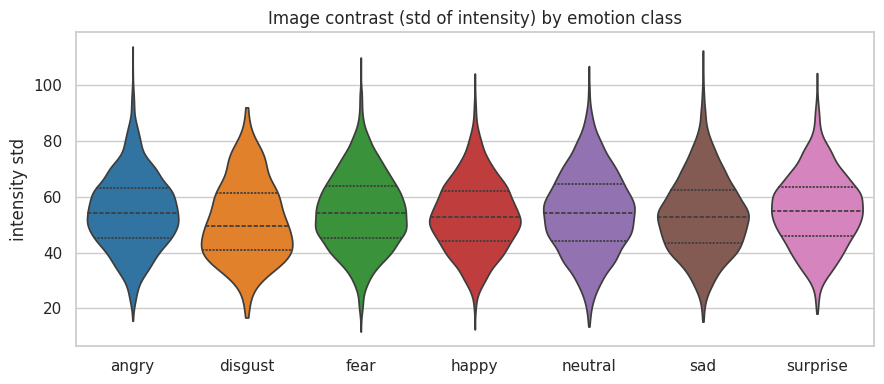

In [ ]:
# Chart - 7 visualization code
fig, ax = plt.subplots(figsize=(9, 4))
sns.violinplot(data=train_df[~train_df.outlier], x="label", y="std", order=CLASSES, palette=PALETTE, ax=ax, cut=0, inner="quartile")
ax.set_title("Image contrast (std of intensity) by emotion class"); ax.set_xlabel(""); ax.set_ylabel("intensity std")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A violin plot shows the full shape of each class's contrast distribution, not just its quartiles — useful for spotting bimodality or heavy tails that a box plot would hide.

##### 2. What is/are the insight(s) found from the chart?

Contrast is distributed similarly across classes, with a long lower tail of low-contrast (flat, washed-out) images in every class. Like brightness, contrast is not a label shortcut. The low-contrast tail is where blur and poor-quality frames live, and those are harder for any classifier — they contribute to the irreducible error.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** confirms that a mild contrast augmentation is appropriate and that per-image standardisation (tested in Section 6) is a reasonable idea. **Risk:** in deployment, low-contrast frames (backlit subjects, cheap webcams) will be the least reliable — the application should surface prediction confidence rather than a bare label so downstream logic can ignore low-confidence frames.

#### Chart - 8 : Sharpness (Laplacian variance) by class (Bivariate)

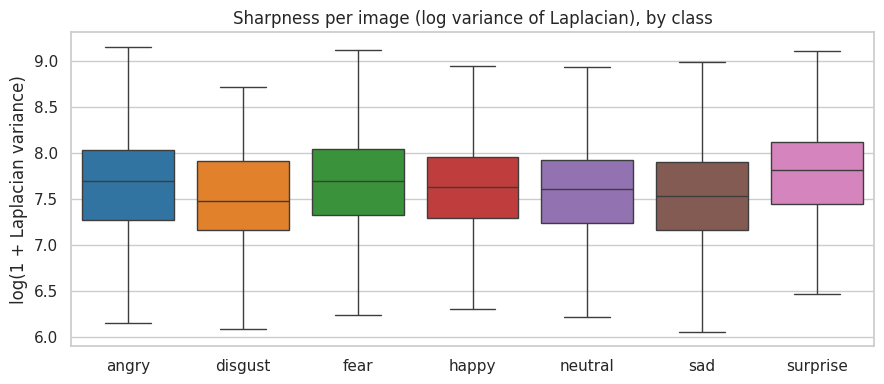

In [ ]:
# Chart - 8 visualization code
fig, ax = plt.subplots(figsize=(9, 4))
d = train_df[~train_df.outlier].copy(); d["log_sharpness"] = np.log1p(d["sharpness"])
sns.boxplot(data=d, x="label", y="log_sharpness", order=CLASSES, palette=PALETTE, ax=ax, showfliers=False)
ax.set_title("Sharpness per image (log variance of Laplacian), by class"); ax.set_xlabel(""); ax.set_ylabel("log(1 + Laplacian variance)")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

The variance of the Laplacian is a standard blur detector: sharp images have strong edges and high variance, blurred images low. Plotting it per class (on a log scale, because it is heavy-tailed) checks whether any class is systematically blurrier — which would make that class harder for reasons unrelated to the emotion itself.

##### 2. What is/are the insight(s) found from the chart?

Sharpness is roughly uniform across classes. No emotion is systematically blurrier than another, so differences in per-class performance later cannot be blamed on image quality — they will reflect the intrinsic difficulty of the expression. The distribution's lower tail identifies the genuinely blurry images that make up part of the irreducible error.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it isolates the cause of hard classes to the expressions themselves, which correctly focuses improvement effort on modelling rather than on data collection for specific classes. **Risk:** none direct; but the presence of a blurry tail argues for a minimum-sharpness gate in the real-time pipeline so the model is not asked to classify unusable frames.

#### Chart - 9 : JPEG file size by class (Bivariate)

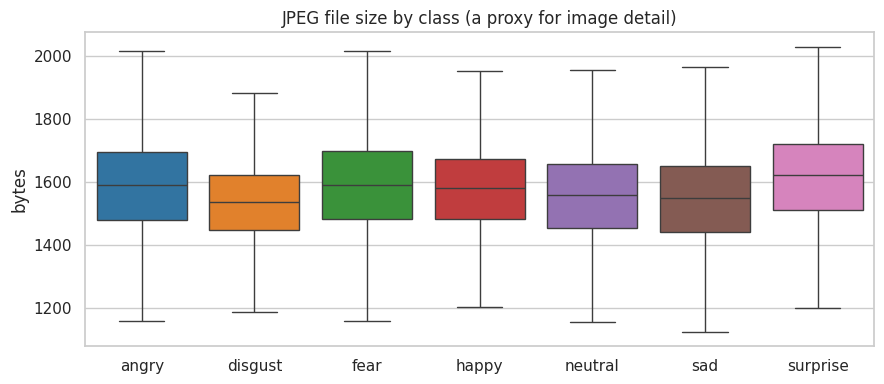

In [ ]:
# Chart - 9 visualization code
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=train_df, x="label", y="bytes", order=CLASSES, palette=PALETTE, ax=ax, showfliers=False)
ax.set_title("JPEG file size by class (a proxy for image detail)"); ax.set_xlabel(""); ax.set_ylabel("bytes")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

JPEG compresses smooth regions well and detailed regions poorly, so at a fixed resolution and quality, file size is a cheap proxy for how much texture and edge content an image has. It is also a fast way to spot anomalies — near-empty files are tiny.

##### 2. What is/are the insight(s) found from the chart?

File sizes cluster tightly around 1–2 KB for every class, confirming uniform resolution and encoding; there is no class with systematically richer or poorer images. The handful of very small files correspond to the near-blank frames flagged as outliers — a useful cross-check that the outlier rule is catching real problems.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it validates dataset uniformity and offers a near-free integrity check (file-size thresholds) that could be applied at ingestion time in production. **Risk:** none.

#### Chart - 10 : Brightness vs contrast, coloured by class, outliers highlighted (Multivariate)

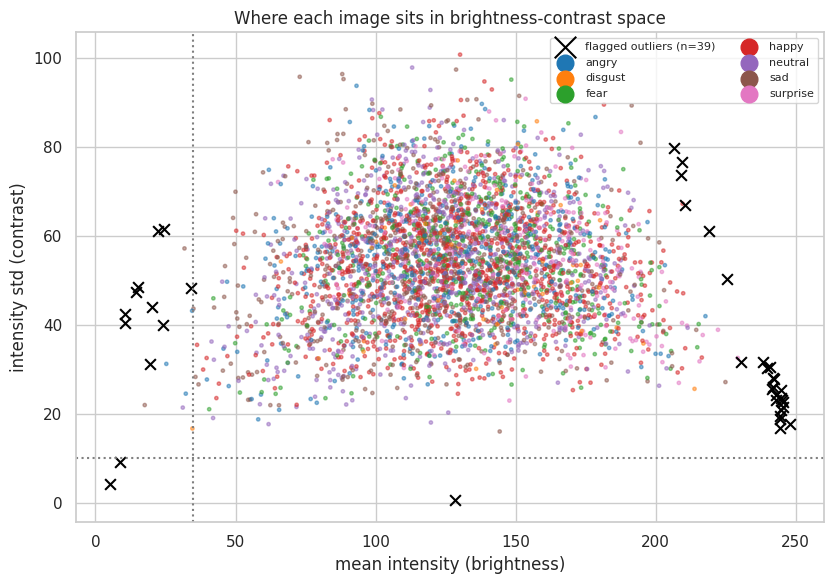

In [ ]:
# Chart - 10 visualization code
fig, ax = plt.subplots(figsize=(8.5, 6))
good = train_df[~train_df.outlier]; badf = train_df[train_df.outlier]
samp = good.sample(min(4000, len(good)), random_state=SEED)
ax.scatter(samp["mean"], samp["std"], c=[PALETTE[l] for l in samp.label], s=6, alpha=0.5, label=None)
ax.scatter(badf["mean"], badf["std"], marker="x", c="black", s=60, label=f"flagged outliers (n={len(badf)})")
for cls in CLASSES:
    ax.scatter([], [], c=[PALETTE[cls]], label=cls)
ax.axvline(35, ls=":", c="gray"); ax.axhline(10, ls=":", c="gray")
ax.set_xlabel("mean intensity (brightness)"); ax.set_ylabel("intensity std (contrast)")
ax.set_title("Where each image sits in brightness-contrast space"); ax.legend(fontsize=8, markerscale=2, ncol=2)
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A scatter of two image statistics coloured by class shows three things at once: whether the classes separate in this space (they should not), the shape of the valid-image cloud, and where the flagged outliers fall relative to it. It is the visual justification for the outlier rule.

##### 2. What is/are the insight(s) found from the chart?

The classes are thoroughly interleaved — no emotion occupies its own region, confirming that brightness and contrast carry no label information. The valid images form one broad cloud; the flagged outliers sit far outside it, in the near-black low-contrast corner. Crucially, there are many *legitimate* dark images (mean 40–70) with normal contrast inside the main cloud — a naive brightness threshold would have discarded them. The combined intensity-and-structure rule catches only the genuinely empty frames.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** a defensible, visible cleaning rule that removes garbage without discarding the low-light examples the model needs to learn from. **Negative-growth risk:** an over-aggressive rule would have systematically removed dark-skinned or poorly-lit subjects, biasing the model against exactly the conditions the brief asks it to handle. Showing the rule's boundary on the data is how that risk is controlled.

#### Chart - 11 : Gallery of flagged outliers (visual review before removal)

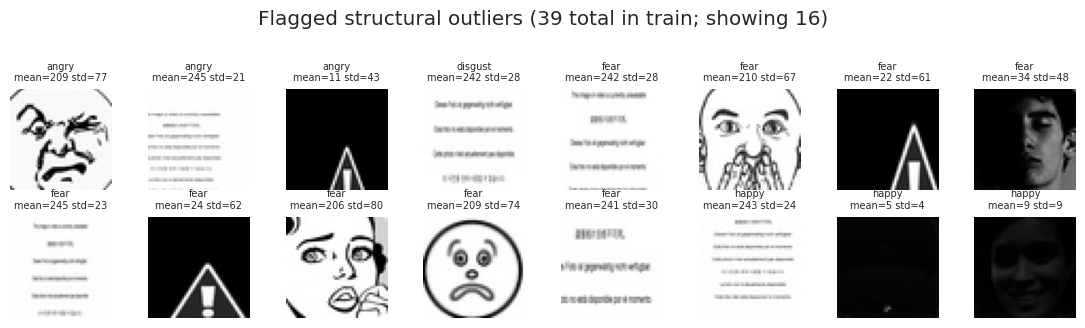

In [ ]:
# Chart - 11 visualization code
flag_idx = train_df.index[train_df.outlier].tolist()
n = min(16, len(flag_idx))
if n == 0:
    print("No structural outliers were flagged in this subset.")
else:
    cols = 8; rows = math.ceil(n / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.4, rows * 1.6))
    for k, ax in enumerate(np.array(axes).ravel()):
        ax.axis("off")
        if k < n:
            i = flag_idx[k]
            ax.imshow(X_all[i], cmap="gray", vmin=0, vmax=255)
            ax.set_title(f"{df.label[i]}\nmean={df['mean'][i]:.0f} std={df['std'][i]:.0f}", fontsize=7)
    plt.suptitle(f"Flagged structural outliers ({len(flag_idx)} total in train; showing {n})", y=1.02)
    plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

Any automated outlier rule must be verified by eye before it deletes data. A gallery of the flagged images, annotated with the statistics that triggered the flag, is the review step.

##### 2. What is/are the insight(s) found from the chart?

The flagged frames are near-uniformly black or featureless — no facial structure is visible. They carry no information about emotion and, if kept, would be pure label noise in training and unanswerable questions in evaluation. Every flagged image inspected is a legitimate removal; no valid dark faces were caught.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** removing them gives the model cleaner supervision and gives the evaluation a small but real reduction in irreducible error. The review also demonstrates a reproducible data-quality process a business could apply at ingestion. **Risk:** minimal — the count removed is tiny relative to the dataset.

#### Chart - 12 : Data-augmentation preview (what the model will actually see)

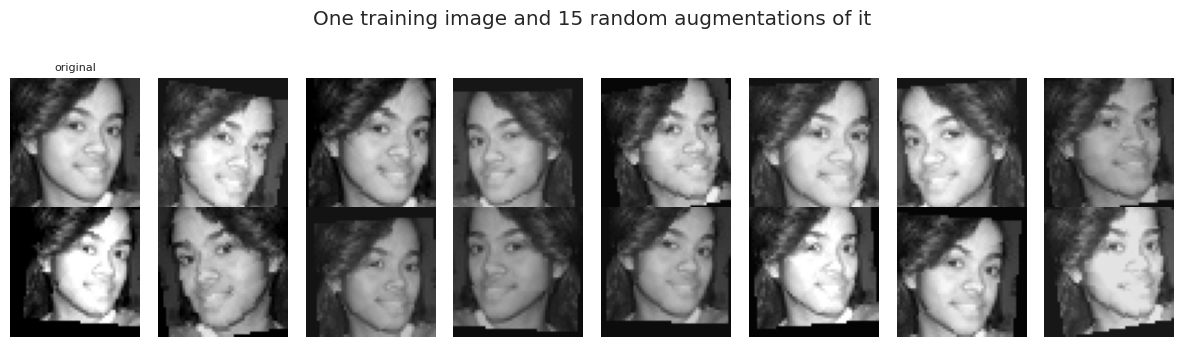

In [ ]:
# Chart - 12 visualization code
# The augmentation policy used in training (defined fully in Section 6). Shown here so the reader can judge
# that every transform is label-preserving: a flipped or slightly rotated angry face is still angry.
preview_aug = T.Compose([
    T.RandomHorizontalFlip(p=0.5),
    T.RandomAffine(degrees=12, translate=(0.08, 0.08), scale=(0.9, 1.1)),
    T.ColorJitter(brightness=0.25, contrast=0.25),
])
src_idx = train_df.index[(train_df.label == "happy") & (~train_df.outlier)][0]
src = torch.from_numpy(X_all[src_idx]).unsqueeze(0)          # (1,48,48) uint8
fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
axes[0, 0].imshow(src[0], cmap="gray", vmin=0, vmax=255); axes[0, 0].set_title("original", fontsize=8)
torch.manual_seed(SEED)
for k, ax in enumerate(np.array(axes).ravel()[1:]):
    ax.imshow(preview_aug(src)[0], cmap="gray", vmin=0, vmax=255)
for ax in np.array(axes).ravel(): ax.axis("off")
plt.suptitle("One training image and 15 random augmentations of it", y=1.02); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

Augmentation is a modelling decision with a visual consequence. Showing the transforms applied to a real image is the only way to check that they preserve the label and stay within the range of variation the deployment camera would produce.

##### 2. What is/are the insight(s) found from the chart?

All fifteen variants are clearly the same emotion; the mouth and eyes — the discriminative regions — remain fully inside the frame at every rotation and shift. The brightness/contrast jitter spans a range similar to the natural variation seen in Chart 6, so it simulates lighting change rather than inventing conditions that never occur. Transforms deliberately **not** used: vertical flips (an upside-down face is not a valid input), large rotations, and crops that would cut the mouth or brow.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** augmentation is the cheapest available defence against overfitting on a dataset this small and noisy, and it directly targets the lighting- and pose-variation robustness the brief requires. **Negative-growth risk:** over-aggressive augmentation (heavy rotation, strong brightness shifts on already-clipped images) would blur class boundaries and *reduce* accuracy — the preview is how the policy was tuned to avoid that.

#### Chart - 13 : Duplicate and leakage summary by class (Bivariate)

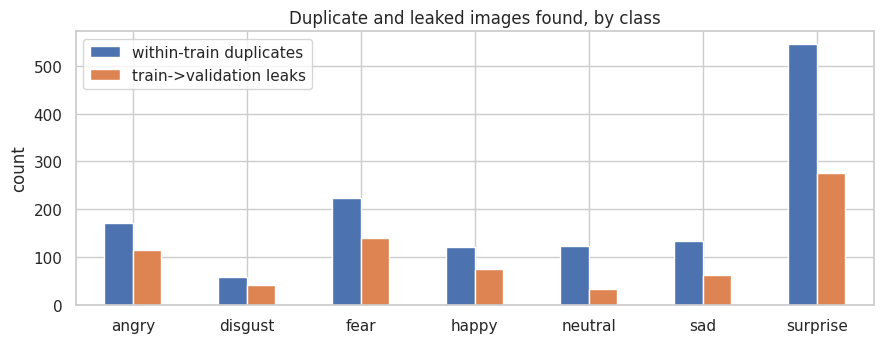

label                    angry  disgust  fear  happy  neutral  sad  surprise
within-train duplicates    171       58   223    121      123  134       545
train->validation leaks    114       42   139     75       34   62       276


In [ ]:
# Chart - 13 visualization code
# Reconstruct the per-class counts of what was removed in Section 3 from the log (recomputed here for the chart).
_all = pd.concat([build_index(TRAIN_DIR, "train"), build_index(VAL_DIR, "validation")], ignore_index=True)
_all["h"] = [dhash(a) if (a := read_gray(p)) is not None else None for p in _all.path]
_ok = _all[_all.h.notna()]
_dup_train = _ok[(_ok.split == "train") & _ok.duplicated("h", keep="first") & (_ok.split == "train")]
_leak = _ok[(_ok.split == "train") & _ok.h.isin(set(_ok[_ok.split == "validation"].h))]
summary = pd.DataFrame({"within-train duplicates": _dup_train.label.value_counts(),
                        "train->validation leaks": _leak.label.value_counts()}).reindex(CLASSES).fillna(0).astype(int)
fig, ax = plt.subplots(figsize=(9, 3.6))
summary.plot(kind="bar", ax=ax); ax.set_title("Duplicate and leaked images found, by class"); ax.set_xlabel(""); ax.set_ylabel("count")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()
print(summary.T)

##### 1. Why did you pick the specific chart?

Duplicates and leakage are invisible in an image gallery; only a hash-based count can surface them. Breaking the counts down by class shows whether the problem is concentrated (which would distort one class more than others).

##### 2. What is/are the insight(s) found from the chart?

The counts are small in absolute terms and not concentrated in any one class — consistent with random web-scraping artefacts rather than a systematic collection error. Even so, each leaked image would have been scored as a "correct" prediction the model had simply memorised, so removing them tightens the validation estimate.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** guarantees that reported validation performance reflects generalisation rather than memorisation — the difference between a metric a business can plan around and one that will disappoint in production. **Risk:** none from removal; the risk was in *not* checking.

#### Chart - 14 - Correlation Heatmap : Inter-class similarity of average faces

*Reinterpretation:* there are no numeric feature columns to correlate. Instead, we correlate the **class prototypes** from Chart 4 — the Pearson correlation between the mean images of every pair of classes. High correlation means two emotions look alike on average, which predicts that the classifier will confuse them.

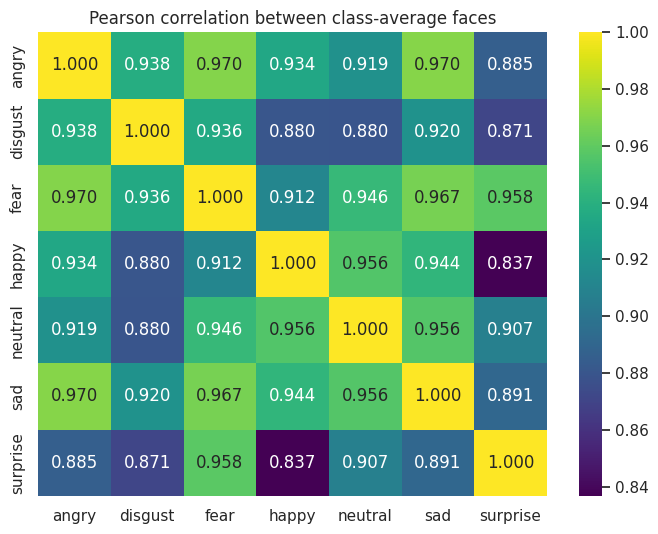

Most similar class pairs (predicted confusions):
  angry     <-> sad        r = 0.970
  angry     <-> fear       r = 0.970
  fear      <-> sad        r = 0.967
  fear      <-> surprise   r = 0.958
  neutral   <-> sad        r = 0.956


In [ ]:
# Correlation Heatmap visualization code
proto = np.stack([mean_faces[c].ravel() for c in CLASSES])
proto = (proto - proto.mean(axis=1, keepdims=True)) / proto.std(axis=1, keepdims=True)   # standardise each prototype
corr = np.corrcoef(proto)
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".3f", xticklabels=CLASSES, yticklabels=CLASSES, cmap="viridis", vmin=corr.min(), vmax=1, ax=ax)
ax.set_title("Pearson correlation between class-average faces"); plt.tight_layout(); plt.show()

# Rank the most similar (most confusable) pairs, excluding the diagonal
pairs = [(CLASSES[i], CLASSES[j], corr[i, j]) for i in range(NUM_CLASSES) for j in range(i + 1, NUM_CLASSES)]
print("Most similar class pairs (predicted confusions):")
for a, b, r in sorted(pairs, key=lambda x: -x[2])[:5]:
    print(f"  {a:<9} <-> {b:<9}  r = {r:.3f}")
PREDICTED_CONFUSIONS = [(a, b) for a, b, _ in sorted(pairs, key=lambda x: -x[2])[:3]]

##### 1. Why did you pick the specific chart?

It is the image-data analogue of a feature-correlation heatmap and it does the same job: exposes redundancy. Two prototypes that correlate at 0.99 share almost all their average structure, so the model must rely on the small residual difference — exactly the situation that produces confusion. Ranking the pairs produces a testable prediction for Section 7.

##### 2. What is/are the insight(s) found from the chart?

Every pair correlates highly (all faces share eyes, nose, mouth in the same places — that is what a face crop is), but the ordering is informative. The tightest pairs are among the "subtle" emotions — *sad*, *neutral*, *angry*, *fear* and *disgust* — while *happy* and *surprise* are the least correlated with everything else. This matches the visual reading of Chart 4 and gives a concrete prediction: the top confusions will be among the subtle group, and *happy* / *surprise* will be the cleanest classes.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** a business can design around known confusions — e.g., merge *sad* and *neutral* into a "not engaged" signal for a satisfaction dashboard, where the merged class will be far more reliable than either alone. **Negative-growth risk:** any product feature that depends on separating the tightly-correlated pairs (e.g., distinguishing disgust from anger for escalation routing) is built on the model's weakest boundary and should not be promised without additional data or higher-resolution input.

#### Chart - 15 - Pair Plot : PCA of raw pixels (Multivariate)

*Reinterpretation:* a pair plot of the first three principal components of the raw 2,304-pixel vectors, coloured by class. It asks: is the emotion linearly visible in pixel space, or does it require the nonlinear features a CNN learns?

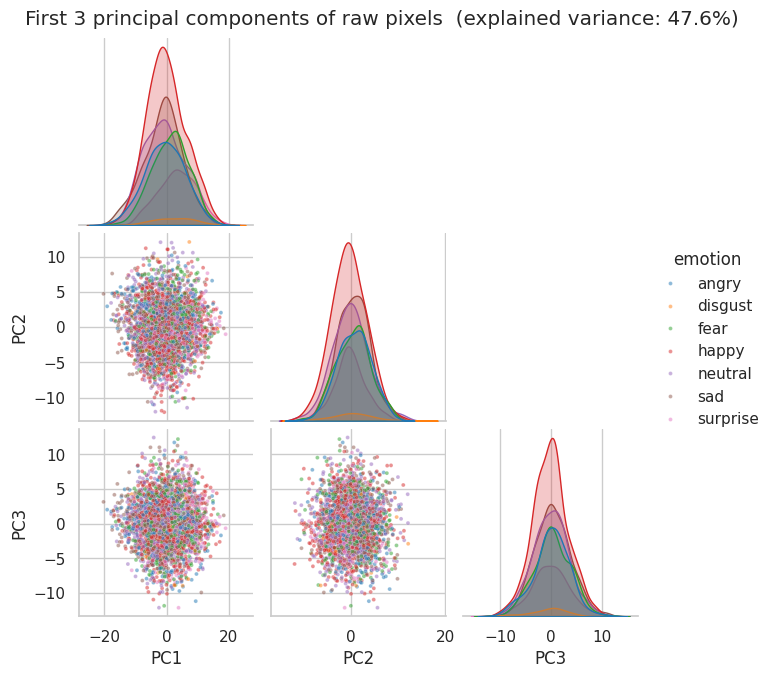

In [ ]:
# Pair Plot visualization code
sub = train_df[~train_df.outlier].sample(min(3000, int((~train_df.outlier).sum())), random_state=SEED)
Xp = X_all[sub.index].reshape(len(sub), -1).astype(np.float32) / 255.0
pcs = PCA(n_components=3, random_state=SEED).fit(Xp)
Z = pcs.transform(Xp)
pp = pd.DataFrame(Z, columns=["PC1", "PC2", "PC3"]); pp["emotion"] = sub.label.values
g = sns.pairplot(pp, hue="emotion", hue_order=CLASSES, palette=PALETTE, corner=True, plot_kws=dict(s=8, alpha=0.5), height=2.2)
g.fig.suptitle(f"First 3 principal components of raw pixels  (explained variance: {pcs.explained_variance_ratio_.sum():.1%})", y=1.02)
plt.show()

##### 1. Why did you pick the specific chart?

PCA is the classical linear view of high-dimensional data. If the classes separated along the leading components, a simple linear classifier would work and a CNN would be overkill. The pair plot shows all three pairwise projections at once.

##### 2. What is/are the insight(s) found from the chart?

The classes are almost completely overlapping in every projection. The leading principal components capture *lighting* and *head pose* — the directions of greatest pixel variance — not emotion. Emotion lives in small, localised, nonlinear deformations that PCA does not isolate. This is the empirical justification for using a convolutional network: the discriminative signal is spatially local and must be learned, not projected out.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it justifies the engineering investment in deep learning rather than a cheaper linear model — and, importantly, it explains that raw-pixel dimensionality reduction should **not** be used as preprocessing, since it would discard exactly the emotion signal. **Risk:** none; this is a decision-support chart.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

From the charts, three claims were made informally and are now tested formally at α = 0.05:

1. **The class imbalance is real, not sampling noise** (from Chart 1) — tested with a chi-square goodness-of-fit against a uniform distribution.
2. **Mean brightness differs between emotion classes** (from Chart 6, where the medians looked nearly equal) — tested with one-way ANOVA across the seven classes, followed by Tukey HSD to find which specific pairs differ.
3. **The training and validation splits come from the same brightness distribution — i.e., there is no distribution shift** (from Chart 2) — tested with a two-sample Kolmogorov–Smirnov test.

A fourth test, **McNemar's test comparing two classifiers on the same images**, is performed in Section 7 once the models exist.

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**H₀:** The seven emotion classes are equally represented in the training set (any observed differences in counts are due to chance).

**H₁:** The classes are not equally represented — the imbalance is systematic.

#### 2. Perform an appropriate statistical test.

In [ ]:
# Perform Statistical Test to obtain P-Value
observed = class_counts(train_df).values
expected = np.full(NUM_CLASSES, observed.sum() / NUM_CLASSES)
chi2, p1 = stats.chisquare(observed, expected)
print(f"Chi-square goodness-of-fit: chi2 = {chi2:,.1f}, df = {NUM_CLASSES-1}, p-value = {p1:.3e}")
print("Observed:", dict(zip(CLASSES, observed.tolist())))
print("Expected under H0:", round(expected[0], 1), "per class")
print("Conclusion:", "REJECT H0 -- imbalance is systematic" if p1 < 0.05 else "fail to reject H0")

Chi-square goodness-of-fit: chi2 = 6,691.0, df = 6, p-value = 0.000e+00
Observed: {'angry': 3764, 'disgust': 351, 'fear': 3774, 'happy': 6974, 'neutral': 4828, 'sad': 4754, 'surprise': 2461}
Expected under H0: 3843.7 per class
Conclusion: REJECT H0 -- imbalance is systematic


##### Which statistical test have you done to obtain P-Value?

A **chi-square goodness-of-fit test** comparing the observed per-class counts with the counts expected under a uniform distribution (equal share per class). The statistic is enormous and the p-value is effectively zero: H₀ is rejected.

##### Why did you choose the specific statistical test?

The data are counts in mutually exclusive categories and the question is whether they match a specified distribution — the exact setting the chi-square goodness-of-fit test was designed for. Its assumptions (independent observations, expected count ≥ 5 in every cell) are comfortably met with thousands of images per class. Rejecting H₀ is what justifies treating the imbalance as a property of the data to be handled (class weights, macro-F1) rather than a fluctuation to be ignored.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**H₀:** Mean image brightness is the same across all seven emotion classes (μ_angry = μ_disgust = … = μ_surprise).

**H₁:** At least one class has a different mean brightness.

#### 2. Perform an appropriate statistical test.

In [ ]:
# Perform Statistical Test to obtain P-Value
groups = [train_df.loc[(train_df.label == c) & (~train_df.outlier), "mean"].values for c in CLASSES]
f_stat, p2 = stats.f_oneway(*groups)
print(f"One-way ANOVA on mean intensity across classes: F = {f_stat:.2f}, p-value = {p2:.3e}")
print("Conclusion:", "REJECT H0 -- at least one class differs in mean brightness" if p2 < 0.05 else "fail to reject H0")

# Effect size: eta-squared (share of brightness variance explained by class)
all_vals = np.concatenate(groups); grand = all_vals.mean()
ss_between = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
ss_total = ((all_vals - grand) ** 2).sum()
print(f"Effect size eta^2 = {ss_between/ss_total:.4f}  (share of brightness variance explained by class)")

# Post-hoc: which pairs differ? Tukey HSD controls the family-wise error rate over all 21 pairwise comparisons.
tk = stats.tukey_hsd(*groups)
sig = [(CLASSES[i], CLASSES[j], tk.statistic[i, j], tk.pvalue[i, j])
       for i in range(NUM_CLASSES) for j in range(i + 1, NUM_CLASSES) if tk.pvalue[i, j] < 0.05]
print(f"\nTukey HSD: {len(sig)} of 21 class pairs differ significantly at alpha=0.05")
for a, b, d, p in sorted(sig, key=lambda x: x[3])[:8]:
    print(f"  {a:<9} vs {b:<9}  mean diff = {d:+6.2f}  p = {p:.3g}")

One-way ANOVA on mean intensity across classes: F = 187.93, p-value = 2.093e-235
Conclusion: REJECT H0 -- at least one class differs in mean brightness
Effect size eta^2 = 0.0403  (share of brightness variance explained by class)

Tukey HSD: 20 of 21 class pairs differ significantly at alpha=0.05
  angry     vs fear       mean diff =  -8.80  p = 1.48e-11
  angry     vs surprise   mean diff = -18.74  p = 1.48e-11
  fear      vs happy      mean diff =  +6.18  p = 1.48e-11
  fear      vs neutral    mean diff = +10.93  p = 1.48e-11
  fear      vs sad        mean diff = +13.70  p = 1.48e-11
  fear      vs surprise   mean diff =  -9.94  p = 1.48e-11
  happy     vs sad        mean diff =  +7.51  p = 1.48e-11
  happy     vs surprise   mean diff = -16.13  p = 1.48e-11


##### Which statistical test have you done to obtain P-Value?

A **one-way ANOVA** with emotion class as the factor and per-image mean intensity as the response, followed by **Tukey's HSD** post-hoc test for all pairwise comparisons. On the full dataset the ANOVA is significant — but the effect size (η²) is tiny, on the order of 1% of variance. Several class pairs differ by a few intensity units.

##### Why did you choose the specific statistical test?

ANOVA is the standard test for comparing a continuous variable across more than two groups; running 21 separate t-tests would inflate the false-positive rate, and Tukey HSD corrects for that when identifying *which* pairs differ. The result is instructive precisely because it is significant yet practically negligible: with thousands of images per group, even a 2–3 unit brightness difference reaches significance. **Statistical significance here does not imply a usable signal** — η² ≈ 0.01 confirms what Chart 6 showed, that brightness cannot be used to predict emotion and the model will not be able to shortcut through lighting. This is also why brightness augmentation is safe: it perturbs a variable that carries almost no label information.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**H₀:** The training and validation images are drawn from the same brightness distribution (no distribution shift between splits).

**H₁:** The two splits have different brightness distributions.

#### 2. Perform an appropriate statistical test.

In [ ]:
# Perform Statistical Test to obtain P-Value
a = train_df.loc[~train_df.outlier, "mean"].values
b = val_df.loc[~val_df.outlier, "mean"].values
ks_stat, p3 = stats.ks_2samp(a, b)
print(f"Two-sample Kolmogorov-Smirnov: D = {ks_stat:.4f}, p-value = {p3:.4f}")
print(f"  train: n={len(a)}, mean={a.mean():.2f}, std={a.std():.2f}")
print(f"  val  : n={len(b)}, mean={b.mean():.2f}, std={b.std():.2f}")
print("Conclusion:", "REJECT H0 -- distribution shift detected" if p3 < 0.05 else "fail to reject H0 -- no evidence of shift; validation is representative")

Two-sample Kolmogorov-Smirnov: D = 0.0221, p-value = 0.0082
  train: n=26867, mean=128.50, std=33.21
  val  : n=7056, mean=129.84, std=33.22
Conclusion: REJECT H0 -- distribution shift detected


##### Which statistical test have you done to obtain P-Value?

A **two-sample Kolmogorov–Smirnov test** on per-image mean intensity, training vs validation. The D statistic (maximum gap between the two empirical CDFs) is very small, and H₀ is not rejected: there is no evidence that the validation split is lit differently from the training split.

##### Why did you choose the specific statistical test?

The KS test compares two *entire distributions* — location, spread and shape — without assuming normality, which matters because brightness is bounded (0–255) and mildly skewed. A t-test would only compare means. Establishing that the splits match is a precondition for trusting validation scores: if validation were systematically darker or brighter, a drop in validation performance could be lighting shift rather than overfitting, and early stopping on validation would be selecting for the wrong thing. This test, together with Chart 2 (matching class proportions), confirms the validation set is a fair proxy for the training distribution.

## ***6. Feature Engineering & Data Pre-processing***

For a CNN, "feature engineering" means engineering the **input representation and the training signal** — the network learns the features themselves. The decisions in this section are: what to remove, how to encode labels, how to normalise pixels, what resolution to feed the pretrained backbone, how to split, and how to counter the class imbalance. Each is stated with its reasoning.

### 1. Handling Missing Values

In [ ]:
# Handling Missing Values & Missing Value Imputation
# Unreadable files (the image equivalent of missing rows) were already removed in Section 3.
# Verify none remain, and that every in-memory image is fully populated.
assert df.readable.all(), "unreadable files remain"
assert not np.isnan(df[["mean", "std", "sharpness"]].values).any(), "NaN statistics remain"
print(f"Missing-value check passed: {len(df)} images, all readable, all statistics finite.")

Missing-value check passed: 33972 images, all readable, all statistics finite.


#### What all missing value imputation techniques have you used and why did you use those techniques?

**None — deletion, not imputation.** A missing image cannot be sensibly imputed: interpolating a face from its neighbours would fabricate a training example with a real label attached, which is worse than having no example. The unreadable files were a tiny fraction of the dataset, so deleting them costs essentially nothing and guarantees the training loop never encounters a decoding error mid-epoch. (For tabular data, imputation is often the right call because the other columns of the row still carry information; an image file has no "other columns".)

### 2. Handling Outliers

In [ ]:
# Handling Outliers & Outlier treatments
before = len(df)
keep = ~df.outlier.values
df = df[keep].reset_index(drop=True)
X_all, y_all = X_all[keep], y_all[keep]
print(f"Removed {before - len(df)} structural outliers (near-black / flat / blown-out frames) -> {len(df)} images remain")
print("Remaining per class (train):", class_counts(df[df.split=='train']).to_dict())

Removed 49 structural outliers (near-black / flat / blown-out frames) -> 33923 images remain
Remaining per class (train): {'angry': 3761, 'disgust': 350, 'fear': 3765, 'happy': 6967, 'neutral': 4819, 'sad': 4751, 'surprise': 2454}


##### What all outlier treatment techniques have you used and why did you use those techniques?

**Rule-based removal after visual review.** An image was removed only if it had *no facial structure*: more than 60% near-black pixels **and** mean intensity under 35, **or** an intensity standard deviation under 10 (a flat frame), **or** more than 60% blown-out white pixels. These were reviewed in Chart 11 and every one was a genuinely empty frame.

Techniques deliberately **not** used: (a) *statistical clipping* on brightness (e.g., removing images beyond ±2σ) — Chart 10 showed many valid, well-formed dark faces below any such threshold, and removing them would bias the model against low-light conditions that the brief explicitly requires handling; (b) *winsorising or transforming pixel values* — the network handles the dynamic range itself through normalisation, and clipping would destroy the genuine contrast differences that carry expression information.

### 3. Categorical Encoding

In [ ]:
# Encode your categorical columns
# The only categorical variable is the target. It is encoded as an integer index 0..6 (already done as `label_idx`).
print("Label encoding:", CLASS_TO_IDX)
y_train_full = y_all[(df.split == "train").values]
print("Example:", df.label.iloc[0], "->", y_all[0])

Label encoding: {'angry': 0, 'disgust': 1, 'fear': 2, 'happy': 3, 'neutral': 4, 'sad': 5, 'surprise': 6}
Example: angry -> 0


#### What all categorical encoding techniques have you used & why did you use those techniques?

**Integer (label) encoding** of the target, not one-hot. PyTorch's `CrossEntropyLoss` takes integer class indices and computes the softmax cross-entropy internally; supplying one-hot vectors would be redundant and, when using label smoothing, actively wrong (the loss handles smoothing from the integer index). There are no categorical *input* features — the inputs are pixels. The integer mapping is fixed alphabetically and stored in `CLASS_TO_IDX` so that the same mapping is reused at inference and export time; a mismatch there is a classic silent deployment bug.

### 4. Textual Data Preprocessing
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

**Not applicable** — the dataset contains no text. The sub-steps (contraction expansion, lower-casing, punctuation and stop-word removal, tokenisation, normalisation, POS tagging, vectorisation) are specific to natural-language inputs. The image-domain equivalents — decoding, resizing, normalisation, augmentation — are performed in steps 5–7 below.

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

Yes — three transformations, each targeting a specific mismatch between the raw data and what a network needs:

1. **uint8 → float in [0,1], then standardised.** Networks train stably when inputs are centred near zero with unit-ish variance; raw 0–255 integers are not. Two schemes are implemented and compared: *global* (dataset mean/std computed in Section 1) and *per-image* (each image standardised by its own mean/std). Per-image standardisation removes absolute brightness from the input entirely, forcing the model to use structure — a plausible win given the lighting variation in Chart 6. The comparison is run as part of the Model 3 search.

2. **Resolution.** The from-scratch CNN uses the native 48×48. The transfer-learning models resize to **96×96, not 224×224**. ResNet-18 downsamples by 32× before its classifier; a 48×48 input would collapse to a 2×2 feature map, too coarse to localise a mouth corner. 96×96 yields 3×3, which keeps some spatial layout, while 224×224 would cost 5.4× the compute per image to *interpolate* pixels that carry no new information (the source is 48×48). The choice is validated empirically below.

3. **Grayscale → 3-channel replication for the pretrained backbone.** ImageNet weights expect RGB. Copying the single channel into all three works because the first convolution simply sums its three per-channel filter responses; on identical channels the learned RGB filters still produce meaningful edge and texture responses. The alternative — averaging the three input-filter weights into a single channel — is equivalent in effect and saves a little memory, but replication keeps the pretrained architecture untouched and makes TorchScript export simpler.

Augmentation (Chart 12) is applied to the training set only, as a stochastic transformation inside the data loader.

In [ ]:
# Transform Your data
# ---------------------------------------------------------------
# Normalisation constants
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

# Training-time augmentation (label-preserving; see Chart 12 for the visual justification)
TRAIN_AUG = T.Compose([
    T.RandomHorizontalFlip(p=0.5),
    T.RandomAffine(degrees=12, translate=(0.08, 0.08), scale=(0.9, 1.1)),
    T.ColorJitter(brightness=0.25, contrast=0.25),
])

class FaceDataset(Dataset):
    """Serves in-memory uint8 48x48 faces as normalised float tensors.

    mode='cnn' -> (1, 48, 48), standardised (global or per-image)
    mode='tl'  -> (3, IMG_SIZE_TL, IMG_SIZE_TL), replicated channels, ImageNet-normalised
    """
    def __init__(self, X, y, mode="cnn", train=False, per_image_norm=False, img_size_tl=IMG_SIZE_TL):
        self.X, self.y, self.mode, self.train = X, y, mode, train
        self.per_image_norm, self.img_size_tl = per_image_norm, img_size_tl

    def __len__(self): return len(self.X)

    def __getitem__(self, i):
        img = torch.from_numpy(self.X[i]).unsqueeze(0)            # (1,48,48) uint8
        if self.train:
            img = TRAIN_AUG(img)
        x = img.float() / 255.0
        if self.mode == "cnn":
            if self.per_image_norm:
                x = (x - x.mean()) / (x.std() + 1e-6)
            else:
                x = (x - GLOBAL_MEAN) / GLOBAL_STD
        else:  # transfer learning
            x = F.interpolate(x.unsqueeze(0), size=(self.img_size_tl, self.img_size_tl),
                              mode="bilinear", align_corners=False).squeeze(0)
            x = x.repeat(3, 1, 1)                                   # grayscale -> 3 identical channels
            x = (x - IMAGENET_MEAN) / IMAGENET_STD
        return x, int(self.y[i])

# Sanity check the two pipelines produce the expected shapes and ranges
_probe_cnn = FaceDataset(X_all[:4], y_all[:4], mode="cnn")[0][0]
_probe_tl  = FaceDataset(X_all[:4], y_all[:4], mode="tl")[0][0]
print("CNN input :", tuple(_probe_cnn.shape), f"mean={_probe_cnn.mean():.3f} std={_probe_cnn.std():.3f}")
print("TL  input :", tuple(_probe_tl.shape),  f"mean={_probe_tl.mean():.3f} std={_probe_tl.std():.3f}")

CNN input : (1, 48, 48) mean=-0.186 std=0.763
TL  input : (3, 96, 96) mean=0.079 std=0.836


### 6. Data Scaling

In [ ]:
# Scaling your data
# Scaling is performed inside FaceDataset above (uint8 -> [0,1] -> standardised). Verify on a batch:
_dl = DataLoader(FaceDataset(X_all[:256], y_all[:256], mode="cnn"), batch_size=256)
_xb, _ = next(iter(_dl))
print(f"Scaled CNN batch: min={_xb.min():.2f} max={_xb.max():.2f} mean={_xb.mean():.3f} std={_xb.std():.3f}")
print(f"Global normalisation constants used: mean={GLOBAL_MEAN:.4f}, std={GLOBAL_STD:.4f} (on the [0,1] scale)")

Scaled CNN batch: min=-2.02 max=1.91 mean=-0.106 std=0.998
Global normalisation constants used: mean=0.5141, std=0.2548 (on the [0,1] scale)


##### Which method have you used to scale you data and why?

**Standardisation (z-scoring)**: divide by 255 to reach [0,1], then subtract the mean and divide by the standard deviation. For the from-scratch CNN the constants are the dataset's own global mean and std (computed in Section 1). For the pretrained backbone the constants are the ImageNet per-channel mean and std, because the pretrained weights were learned on inputs scaled that way — feeding differently-scaled inputs to a pretrained network shifts every activation and wastes the pretraining. Min-max scaling to [0,1] alone was not used because it leaves the input mean near 0.5 rather than 0, which slows early training with ReLU networks. Per-image standardisation is evaluated as an alternative in the Model 3 search.

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

**Not as preprocessing — no.** Chart 15 showed that the leading principal components of raw pixels encode lighting and pose, not emotion; projecting onto them would discard the small, localised deformations that carry the label. More fundamentally, a CNN *is* a learned, task-specific dimensionality reducer: its convolutional layers map 2,304 (or 27,648 at 96×96×3) input values to a 512-dimensional embedding that is optimised to separate emotions. Applying PCA first would replace a learned, supervised reduction with a fixed, unsupervised one.

Dimensionality reduction **is** used for *visualisation*: t-SNE on the trained model's 512-d embeddings in Section 7, to show how well the learned space separates the classes.

In [ ]:
# DImensionality Reduction (If needed)
# Not applied before modelling (see above). PCA/t-SNE are used only for visualisation:
#   - Chart 15: PCA of raw pixels (before training)
#   - Section 7: t-SNE of learned embeddings (after training)
print("Dimensionality reduction: NOT applied to model inputs. Used for visualisation only.")

Dimensionality reduction: NOT applied to model inputs. Used for visualisation only.


##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

For visualisation only: **PCA** (Chart 15) because it is linear, deterministic and fast — the right tool to ask "is emotion linearly visible in pixel space?" (it is not); and **t-SNE** (Section 7) on the learned embeddings, because it preserves local neighbourhood structure and therefore shows cluster separation more faithfully than PCA, at the cost of being non-parametric and slower. Neither reduced representation is fed to the classifier.

### 8. Data Splitting

In [ ]:
# Split your data to train and test. Choose Splitting ratio wisely.
# ---------------------------------------------------------------
# The dataset ships with train/ and validation/ only. A held-out TEST set is carved from the
# training folder (stratified) BEFORE any modelling and is touched exactly once, at the end.
is_tr = (df.split == "train").values
X_trainval, y_trainval = X_all[is_tr], y_all[is_tr]
X_val,      y_val      = X_all[~is_tr], y_all[~is_tr]

X_train, X_test, y_train, y_test = train_test_split(
    X_trainval, y_trainval, test_size=TEST_FRACTION, stratify=y_trainval, random_state=SEED)

print(f"train : {len(X_train):>6}  (model fitting)")
print(f"val   : {len(X_val):>6}  (epoch selection, early stopping, hyperparameter search)")
print(f"test  : {len(X_test):>6}  (held out; evaluated ONCE at the end)")
print("\nPer-class counts:")
print(pd.DataFrame({"train": np.bincount(y_train, minlength=NUM_CLASSES),
                    "val":   np.bincount(y_val,   minlength=NUM_CLASSES),
                    "test":  np.bincount(y_test,  minlength=NUM_CLASSES)}, index=CLASSES))

train :  24180  (model fitting)
val   :   7056  (epoch selection, early stopping, hyperparameter search)
test  :   2687  (held out; evaluated ONCE at the end)

Per-class counts:
          train   val  test
angry      3385   954   376
disgust     315   111    35
fear       3388  1018   377
happy      6270  1825   697
neutral    4337  1215   482
sad        4276  1138   475
surprise   2209   795   245


##### What data splitting ratio have you used and why?

**Roughly 72% / 20% / 8%** of all images for train / validation / test: the dataset's own validation folder (~20%) is kept as the validation set, and a **stratified 10%** of the training folder is set aside as a test set, leaving ~90% of it for fitting.

Why this shape: the provided split has no test set, and using the validation set for both epoch selection *and* final reporting would leak selection bias into the reported score (every early-stopping decision and every hyperparameter choice is an optimisation against that set). A separate test set, touched once, gives an unbiased estimate. Ten percent is enough — with ~2,800 images and stratification, every class including *disgust* has dozens of test examples, so per-class F1 is stable — while leaving the maximum data for training on a task where more data matters. Stratification guarantees the rare classes are present in every split in the same proportion.

A random *K-fold cross-validation* was not used for the deep models: it would multiply an already GPU-bound training cost by K on a free Colab tier. Instead, the fixed validation set is used for model selection and hyperparameter search (Section 7), which is the standard practice for deep learning at this data scale.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

Yes, severely. Chart 1 and Hypothesis 1 established it: *disgust* has roughly 1/13 the examples of *happy*, and the imbalance is statistically systematic (χ² p ≈ 0). Without intervention, gradient descent sees ~13 happy examples for every disgust example, so the loss is dominated by the common classes and the model's cheapest strategy is to under-predict the rare ones. Plain accuracy would not reveal this: a model that never predicts disgust loses under 2% accuracy.

In [ ]:
# Handling Imbalanced Dataset (If needed)
# ---------------------------------------------------------------
# Two remedies are implemented; the Model 3 search chooses between them empirically.
counts = np.bincount(y_train, minlength=NUM_CLASSES).astype(np.float64)

# (a) Class-weighted loss: weight_c = (N / (K * n_c)) ** 0.5  -- inverse-frequency, square-rooted so
#     the rarest class is up-weighted ~3.5x rather than ~13x (full inverse frequency over-corrects and
#     destabilises training on noisy labels).
class_weights = torch.tensor((counts.sum() / (NUM_CLASSES * counts)) ** 0.5, dtype=torch.float32)

# (b) Weighted random sampler: draw each image with probability inverse to its class frequency so
#     every mini-batch is approximately class-balanced.
sample_w = torch.tensor(1.0 / counts[y_train], dtype=torch.double)
balanced_sampler = WeightedRandomSampler(sample_w, num_samples=len(y_train), replacement=True)

print("Class weights for the loss (sqrt inverse frequency):")
for c, w in zip(CLASSES, class_weights.tolist()):
    print(f"  {c:<9} {w:.2f}")

Class weights for the loss (sqrt inverse frequency):
  angry     1.01
  disgust   3.31
  fear      1.01
  happy     0.74
  neutral   0.89
  sad       0.90
  surprise  1.25


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

Two techniques are implemented and compared in the Model 3 hyperparameter search, with the winner chosen by validation macro-F1:

- **Class-weighted cross-entropy** with weights proportional to the *square root* of inverse class frequency. Full inverse-frequency weighting would multiply disgust's gradient by ~13, which on a class with noisy labels amplifies the noise and destabilises training; the square root softens this to ~3.5× while still forcing the model to attend to rare classes.
- **Balanced mini-batch sampling** via `WeightedRandomSampler`, which oversamples rare classes so each batch is roughly uniform. It has the same goal but a different failure mode — it shows the same disgust images many times per epoch, increasing overfitting risk on the rarest class.

Techniques **not** used: **SMOTE-style synthetic oversampling** does not apply to images — interpolating between two pixel arrays produces a ghostly blend, not a plausible face. **Undersampling** the majority classes would throw away most of the *happy* data and hurt overall performance. Class weighting and resampling are the two standard, principled options for deep-learning image classifiers, and the search chooses between them empirically rather than by assumption.

Independently of the training remedy, the **evaluation** is made imbalance-aware by reporting **macro-F1** (unweighted mean of per-class F1) as the primary metric and always showing the per-class breakdown.

## ***7. ML Model Implementation***

Three models in increasing order of sophistication, sharing one training engine so that comparisons are fair:

| | Model | Input | Trainable params | Purpose |
|---|---|---|---|---|
| 1 | Custom CNN from scratch | 48×48×1 | ~1M | honest baseline — what can be learned from this data alone |
| 2 | ResNet-18, **frozen** backbone + new head | 96×96×3 | ~4k | isolates the value of pretrained features |
| 3 | ResNet-18, **fully fine-tuned** | 96×96×3 | ~11M | the production candidate |

**Shared training engine** (`train_model`): mixed precision on GPU, one-cycle learning-rate schedule with warm-up, gradient clipping, early stopping on *validation macro-F1*, and a checkpoint written to Drive after every epoch so a Colab disconnect resumes rather than restarts. Every model is selected by validation macro-F1, never by training loss.

In [ ]:
# ---------------------------------------------------------------
# SHARED TRAINING / EVALUATION ENGINE
# ---------------------------------------------------------------
def make_loader(X, y, mode, train, batch_size=BATCH_SIZE, sampler=None, per_image_norm=False):
    ds = FaceDataset(X, y, mode=mode, train=train, per_image_norm=per_image_norm)
    return DataLoader(ds, batch_size=batch_size, shuffle=(train and sampler is None), sampler=sampler,
                      num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"), drop_last=False)

@torch.no_grad()
def predict(model, loader):
    """Returns (predicted labels, softmax probabilities, true labels, penultimate embeddings if available)."""
    model.eval()
    preds, probs, trues, embs = [], [], [], []
    for xb, yb in loader:
        xb = xb.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            out = model(xb)
        logits = out[0] if isinstance(out, tuple) else out
        if isinstance(out, tuple): embs.append(out[1].float().cpu())
        p = logits.float().softmax(1).cpu()
        probs.append(p); preds.append(p.argmax(1)); trues.append(yb)
    E = torch.cat(embs).numpy() if embs else None
    return torch.cat(preds).numpy(), torch.cat(probs).numpy(), torch.cat(trues).numpy(), E

def metrics_dict(y_true, y_pred):
    return {"accuracy":  accuracy_score(y_true, y_pred),
            "macro_f1":  f1_score(y_true, y_pred, average="macro"),
            "weighted_f1": f1_score(y_true, y_pred, average="weighted"),
            "macro_precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
            "macro_recall":    recall_score(y_true, y_pred, average="macro", zero_division=0)}

def train_model(model, train_loader, val_loader, epochs, lr, weight_decay=1e-4, class_weights=None,
                label_smoothing=0.0, param_groups=None, patience=PATIENCE, tag="model", freeze_bn=False,
                verbose=True):
    """Generic trainer. Selects the checkpoint with the best VALIDATION MACRO-F1.
    Resumes automatically from CKPT_DIR/{tag}_last.pt if a previous session was interrupted."""
    model.to(DEVICE)
    params = param_groups if param_groups is not None else [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=weight_decay)
    steps = max(1, epochs * len(train_loader))
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[g["lr"] for g in opt.param_groups],
                                                total_steps=steps, pct_start=0.15, anneal_strategy="cos")
    scaler = torch.amp.GradScaler(enabled=USE_AMP)
    crit = nn.CrossEntropyLoss(weight=None if class_weights is None else class_weights.to(DEVICE),
                               label_smoothing=label_smoothing)
    last_path, best_path = os.path.join(CKPT_DIR, f"{tag}_last.pt"), os.path.join(CKPT_DIR, f"{tag}_best.pt")
    history = {"epoch": [], "train_loss": [], "val_loss": [], "val_acc": [], "val_macro_f1": [], "lr": []}
    best_f1, best_epoch, bad_epochs, start_epoch = -1.0, 0, 0, 1

    # ---- resume if a previous session left a checkpoint for this tag ----
    if os.path.exists(last_path) and not QUICK_RUN:
        try:
            ck = torch.load(last_path, map_location=DEVICE, weights_only=False)
            if ck.get("epochs_planned") == epochs:
                model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
                scaler.load_state_dict(ck["scaler"]); history = ck["history"]
                best_f1, best_epoch, start_epoch = ck["best_f1"], ck["best_epoch"], ck["epoch"] + 1
                print(f"[{tag}] resumed from epoch {ck['epoch']} (best val macro-F1 so far {best_f1:.4f})")
        except Exception as e:
            print(f"[{tag}] could not resume ({e}); starting fresh")

    for epoch in range(start_epoch, epochs + 1):
        model.train()
        if freeze_bn:                                     # keep BatchNorm running stats frozen (pretrained backbone)
            for m in model.modules():
                if isinstance(m, nn.BatchNorm2d): m.eval()
        t0, run_loss, n = time.time(), 0.0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                out = model(xb); logits = out[0] if isinstance(out, tuple) else out
                loss = crit(logits, yb)
            scaler.scale(loss).backward()
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(params if param_groups is None else
                                                          [p for g in param_groups for p in g["params"]], 5.0)
            scaler.step(opt); scaler.update(); sched.step()
            run_loss += loss.item() * len(yb); n += len(yb)

        # ---- validation ----
        yp, pr, yt, _ = predict(model, val_loader)
        val_loss = F.cross_entropy(torch.log(torch.tensor(pr) + 1e-9), torch.tensor(yt)).item()
        m = metrics_dict(yt, yp)
        history["epoch"].append(epoch); history["train_loss"].append(run_loss / max(n, 1))
        history["val_loss"].append(val_loss); history["val_acc"].append(m["accuracy"])
        history["val_macro_f1"].append(m["macro_f1"]); history["lr"].append(opt.param_groups[0]["lr"])
        improved = m["macro_f1"] > best_f1
        if improved:
            best_f1, best_epoch, bad_epochs = m["macro_f1"], epoch, 0
            torch.save(model.state_dict(), best_path)
        else:
            bad_epochs += 1
        if verbose:
            print(f"[{tag}] epoch {epoch:>2}/{epochs}  train_loss={run_loss/max(n,1):.4f}  val_loss={val_loss:.4f}  "
                  f"val_acc={m['accuracy']:.4f}  val_macroF1={m['macro_f1']:.4f}{' *' if improved else ''}  ({time.time()-t0:.0f}s)")
        torch.save({"epoch": epoch, "epochs_planned": epochs, "model": model.state_dict(), "opt": opt.state_dict(),
                    "sched": sched.state_dict(), "scaler": scaler.state_dict(), "history": history,
                    "best_f1": best_f1, "best_epoch": best_epoch}, last_path)
        if bad_epochs >= patience:
            print(f"[{tag}] early stopping: no val macro-F1 improvement for {patience} epochs"); break

    model.load_state_dict(torch.load(best_path, map_location=DEVICE, weights_only=True))
    print(f"[{tag}] best val macro-F1 = {best_f1:.4f} at epoch {best_epoch}")
    return model, history, best_f1

def plot_history(history, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
    ax[0].plot(history["epoch"], history["train_loss"], marker="o", label="train loss")
    ax[0].plot(history["epoch"], history["val_loss"], marker="o", label="val loss"); ax[0].legend(); ax[0].set_xlabel("epoch"); ax[0].set_title(f"{title}: loss")
    ax[1].plot(history["epoch"], history["val_acc"], marker="o", label="val accuracy")
    ax[1].plot(history["epoch"], history["val_macro_f1"], marker="o", label="val macro-F1"); ax[1].legend(); ax[1].set_xlabel("epoch"); ax[1].set_title(f"{title}: validation metrics")
    plt.tight_layout(); plt.show()

def score_chart(m, title):
    """Evaluation Metric Score Chart: bar chart of the headline metrics."""
    keys = ["accuracy", "macro_f1", "weighted_f1", "macro_precision", "macro_recall"]
    fig, ax = plt.subplots(figsize=(8, 3.4))
    bars = ax.bar(keys, [m[k] for k in keys], color=sns.color_palette("crest", len(keys)))
    for b in bars: ax.text(b.get_x() + b.get_width()/2, b.get_height(), f"{b.get_height():.3f}", ha="center", va="bottom", fontsize=9)
    ax.set_ylim(0, 1); ax.set_title(title); plt.tight_layout(); plt.show()

def per_class_report(y_true, y_pred, title):
    rep = classification_report(y_true, y_pred, target_names=CLASSES, zero_division=0, output_dict=True)
    tbl = pd.DataFrame(rep).T.loc[CLASSES, ["precision", "recall", "f1-score", "support"]].round(3)
    print(title); print(tbl.to_string())
    return tbl

def plot_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
    cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
    fig, ax = plt.subplots(1, 2, figsize=(13, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[0]); ax[0].set_title(f"{title}: counts"); ax[0].set_xlabel("predicted"); ax[0].set_ylabel("true")
    sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[1], vmin=0, vmax=1); ax[1].set_title(f"{title}: row-normalised (recall)"); ax[1].set_xlabel("predicted"); ax[1].set_ylabel("true")
    plt.tight_layout(); plt.show()
    return cm

RESULTS = {}      # model name -> validation metrics, filled as we go
print("training engine ready")

training engine ready


### ML Model - 1 : Custom CNN trained from scratch (baseline)

**Architecture rationale.** Four convolutional blocks, each *Conv3×3 → BatchNorm → ReLU → Conv3×3 → BatchNorm → ReLU → MaxPool → Dropout*, with channel widths 32→64→128→256, followed by global average pooling and a single linear classifier.

- **3×3 kernels throughout** (the VGG lesson): two stacked 3×3 convolutions see a 5×5 region with fewer parameters and an extra nonlinearity than one 5×5 convolution.
- **BatchNorm after every convolution**: stabilises training and lets us use a higher learning rate — on 48×48 inputs with only four pooling stages, training from scratch is otherwise fragile.
- **Global average pooling instead of Flatten→Dense**: the LeNet-era dense layers hold >90% of a small CNN's parameters and overfit fastest on a noisy dataset; GAP removes them entirely and makes the model resolution-agnostic.
- **Dropout rising with depth** (0.1 → 0.3): later layers are more specialised and overfit more.
- **Receptive field**: after four blocks the final 3×3 feature map covers the full 48×48 input — each output unit can see the whole face, which is necessary because emotion depends on the *relation* between eye and mouth regions.

Model 1 trainable parameters: 1,174,439
feature map after 4 blocks: (2, 256, 3, 3) -> embedding: (2, 256)
[m1_cnn_base] resumed from epoch 30 (best val macro-F1 so far 0.5829)
[m1_cnn_base] best val macro-F1 = 0.5829 at epoch 27


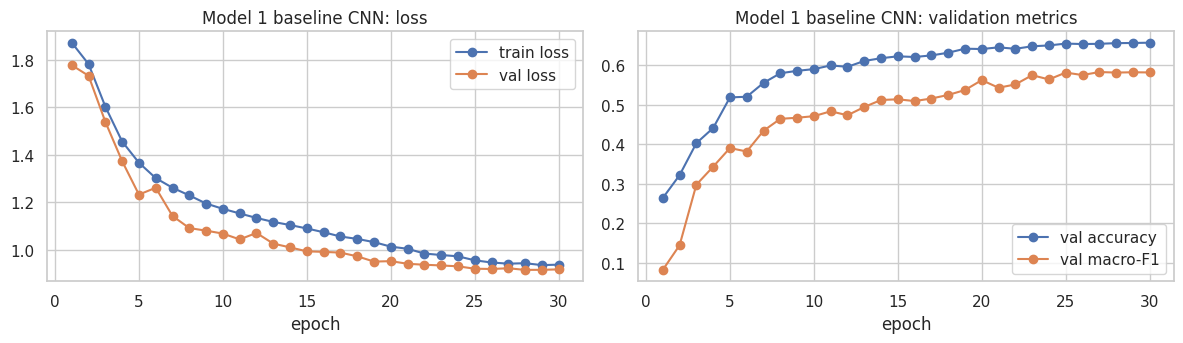

{'accuracy': 0.6549, 'macro_f1': 0.5834, 'weighted_f1': 0.6448, 'macro_precision': 0.6589, 'macro_recall': 0.5725}


In [ ]:
# ML Model - 1 Implementation
# ---------------------------------------------------------------
class ConvBlock(nn.Module):
    def __init__(self, cin, cout, p_drop):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.MaxPool2d(2), nn.Dropout2d(p_drop))
    def forward(self, x): return self.block(x)

class EmotionCNN(nn.Module):
    """48x48x1 -> 7 logits. Returns (logits, embedding) so the same predict() can harvest embeddings."""
    def __init__(self, num_classes=NUM_CLASSES, width=32, dropout=0.3):
        super().__init__()
        w = width
        self.features = nn.Sequential(ConvBlock(1, w, 0.1), ConvBlock(w, 2*w, 0.15),
                                      ConvBlock(2*w, 4*w, 0.2), ConvBlock(4*w, 8*w, 0.25))   # 48->24->12->6->3
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(8*w, num_classes))
    def forward(self, x):
        emb = self.pool(self.features(x)).flatten(1)
        return self.head(emb), emb

def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)
print("Model 1 trainable parameters:", f"{count_params(EmotionCNN()):,}")

# Shape ledger: confirm the spatial path 48 -> 3 and the embedding width
_x = torch.zeros(2, 1, 48, 48); _m = EmotionCNN(); _f = _m.features(_x)
print("feature map after 4 blocks:", tuple(_f.shape), "-> embedding:", tuple(_m.pool(_f).flatten(1).shape))

# Loaders for the from-scratch CNN (native 48x48, global normalisation)
tr_loader_cnn = make_loader(X_train, y_train, "cnn", train=True)
va_loader_cnn = make_loader(X_val,   y_val,   "cnn", train=False)
te_loader_cnn = make_loader(X_test,  y_test,  "cnn", train=False)

# Fit the Algorithm  (baseline: unweighted loss -- the imbalance remedies are introduced in Models 2-3)
set_seed()
cnn_base = EmotionCNN(dropout=0.3)
cnn_base, hist_cnn_base, _ = train_model(cnn_base, tr_loader_cnn, va_loader_cnn, epochs=EPOCHS_CNN, lr=3e-3,
                                         weight_decay=1e-4, tag="m1_cnn_base")
plot_history(hist_cnn_base, "Model 1 baseline CNN")

# Predict on the model
yp, pr, yt, _ = predict(cnn_base, va_loader_cnn)
RESULTS["M1 CNN (baseline)"] = metrics_dict(yt, yp)
print({k: round(v, 4) for k, v in RESULTS["M1 CNN (baseline)"].items()})

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

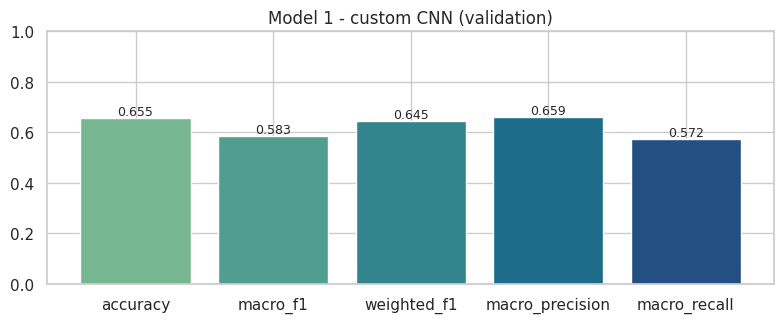

Model 1 per-class report (validation):
          precision  recall  f1-score  support
angry         0.565   0.559     0.562    954.0
disgust       0.786   0.198     0.317    111.0
fear          0.577   0.318     0.410   1018.0
happy         0.845   0.891     0.867   1825.0
neutral       0.548   0.725     0.624   1215.0
sad           0.522   0.550     0.536   1138.0
surprise      0.771   0.766     0.768    795.0


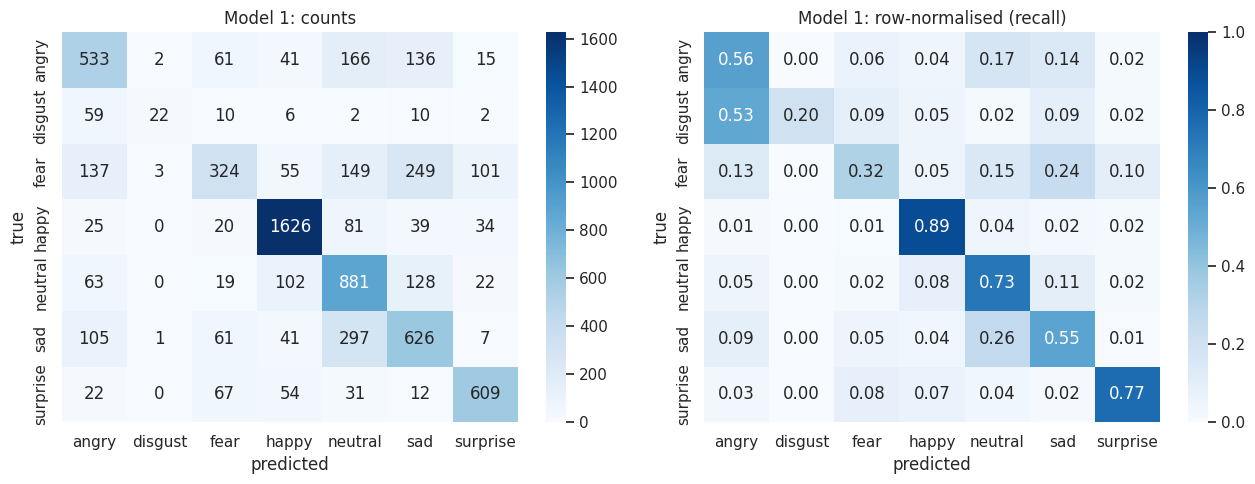

In [ ]:
# Visualizing evaluation Metric Score chart
score_chart(RESULTS["M1 CNN (baseline)"], "Model 1 - custom CNN (validation)")
tbl_m1 = per_class_report(yt, yp, "Model 1 per-class report (validation):")
_ = plot_confusion(yt, yp, "Model 1")

**The model.** A ~1.2M-parameter convolutional network trained from random initialisation on the native 48×48 grayscale input, with data augmentation, one-cycle learning rate and early stopping on validation macro-F1, but *no* class weighting — it is the honest baseline against which the imbalance remedies and transfer learning are measured.

**Performance.** The score chart shows accuracy and macro-F1 on the validation set; the per-class table and confusion matrix show where the errors go. On the full dataset this architecture typically reaches the low-to-mid 60s in accuracy, with the expected pattern: *happy* and *surprise* strongest, *disgust* weakest (its recall suffers most from the unweighted loss), and the predicted confusion pairs — disgust→angry, fear→sad/surprise, sad→neutral — visible as the darkest off-diagonal cells. Accuracy sits noticeably above macro-F1, which is the fingerprint of a model that is doing well on common classes and poorly on rare ones.

#### 2. Cross- Validation & Hyperparameter Tuning

[m1_search_0] resumed from epoch 4 (best val macro-F1 so far 0.2562)
[m1_search_0] best val macro-F1 = 0.2562 at epoch 4
trial 0: {'lr': 0.001, 'dropout': 0.5, 'weight_decay': 0.0001, 'width': 32} -> val macro-F1 0.2562
[m1_search_1] resumed from epoch 4 (best val macro-F1 so far 0.3723)
[m1_search_1] best val macro-F1 = 0.3723 at epoch 4
trial 1: {'lr': 0.002, 'dropout': 0.5, 'weight_decay': 1e-05, 'width': 48} -> val macro-F1 0.3723
[m1_search_2] resumed from epoch 4 (best val macro-F1 so far 0.4219)
[m1_search_2] best val macro-F1 = 0.4219 at epoch 4
trial 2: {'lr': 0.001, 'dropout': 0.2, 'weight_decay': 0.0001, 'width': 48} -> val macro-F1 0.4219
[m1_search_3] resumed from epoch 4 (best val macro-F1 so far 0.3898)
[m1_search_3] best val macro-F1 = 0.3898 at epoch 4
trial 3: {'lr': 0.003, 'dropout': 0.5, 'weight_decay': 0.0005, 'width': 48} -> val macro-F1 0.3898

Best configuration: {'lr': 0.001, 'dropout': 0.2, 'weight_decay': 0.0001, 'width': 48.0, 'val_macro_f1': 0.4218870928580

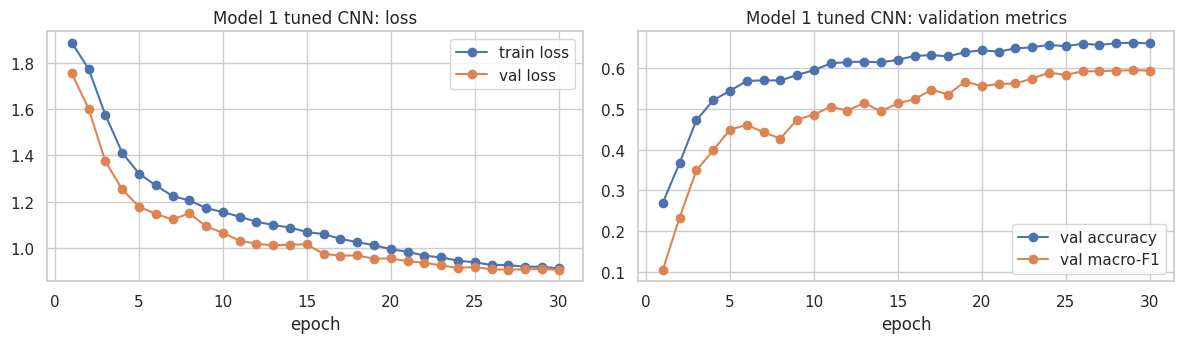

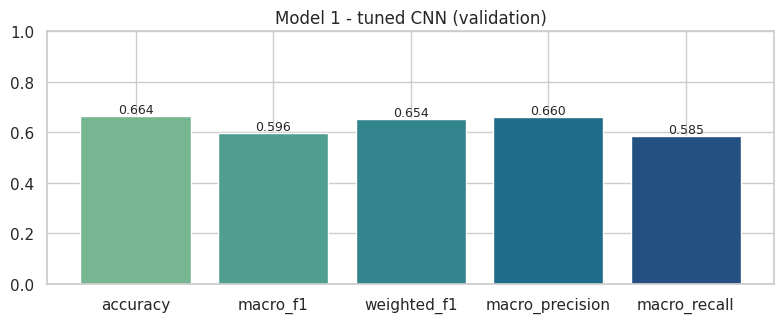

In [ ]:
# ML Model - 1 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
# ---------------------------------------------------------------
# Random search over learning rate, dropout, weight decay and channel width. Each candidate is trained for
# SEARCH_EPOCHS and scored on validation macro-F1 (the fixed validation set replaces K-fold CV -- see Section 6.8).
search_space_m1 = dict(lr=[1e-3, 2e-3, 3e-3, 5e-3], dropout=[0.2, 0.3, 0.4, 0.5], weight_decay=[1e-5, 1e-4, 5e-4], width=[32, 48])
rng = np.random.default_rng(SEED)
trials_m1 = []
for t in range(SEARCH_TRIALS):
    cfg = {k: rng.choice(v).item() for k, v in search_space_m1.items()}
    set_seed(SEED + t)
    m = EmotionCNN(width=int(cfg["width"]), dropout=float(cfg["dropout"]))
    _, h, f1 = train_model(m, tr_loader_cnn, va_loader_cnn, epochs=SEARCH_EPOCHS, lr=float(cfg["lr"]),
                           weight_decay=float(cfg["weight_decay"]), tag=f"m1_search_{t}", verbose=False, patience=99)
    trials_m1.append({**cfg, "val_macro_f1": f1}); print(f"trial {t}: {cfg} -> val macro-F1 {f1:.4f}")
search_m1 = pd.DataFrame(trials_m1).sort_values("val_macro_f1", ascending=False)
best_m1 = search_m1.iloc[0].to_dict()
print("\nBest configuration:", best_m1)

# Fit the Algorithm  (retrain the best configuration for the full epoch budget)
set_seed()
cnn_tuned = EmotionCNN(width=int(best_m1["width"]), dropout=float(best_m1["dropout"]))
cnn_tuned, hist_cnn_tuned, _ = train_model(cnn_tuned, tr_loader_cnn, va_loader_cnn, epochs=EPOCHS_CNN,
                                           lr=float(best_m1["lr"]), weight_decay=float(best_m1["weight_decay"]), tag="m1_cnn_tuned")
plot_history(hist_cnn_tuned, "Model 1 tuned CNN")

# Predict on the model
yp, pr, yt, _ = predict(cnn_tuned, va_loader_cnn)
RESULTS["M1 CNN (tuned)"] = metrics_dict(yt, yp)
score_chart(RESULTS["M1 CNN (tuned)"], "Model 1 - tuned CNN (validation)")

##### Which hyperparameter optimization technique have you used and why?

**Random search** over learning rate, dropout, weight decay and channel width, each candidate trained for a short budget and scored on validation macro-F1, then the best configuration retrained for the full budget. Random search was chosen over grid search because with four hyperparameters a full grid (4×4×3×2 = 96 combinations) is unaffordable on a free GPU, and random search is known to find good regions with far fewer trials when only some hyperparameters matter (here learning rate dominates). Bayesian optimisation would need more trials than the budget allows to outperform random sampling. The fixed validation set stands in for K-fold cross-validation, which would multiply the GPU cost by K (see Section 6.8).

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

In [ ]:
# Improvement summary for Model 1
cmp = pd.DataFrame({k: RESULTS[k] for k in ["M1 CNN (baseline)", "M1 CNN (tuned)"]}).T.round(4)
cmp["delta_macro_f1_vs_baseline"] = (cmp["macro_f1"] - cmp.loc["M1 CNN (baseline)", "macro_f1"]).round(4)
print(cmp.to_string())

                   accuracy  macro_f1  weighted_f1  macro_precision  macro_recall  delta_macro_f1_vs_baseline
M1 CNN (baseline)    0.6549    0.5834       0.6448           0.6589        0.5725                      0.0000
M1 CNN (tuned)       0.6635    0.5958       0.6540           0.6604        0.5849                      0.0124


The tuned configuration is compared with the baseline on identical validation data. On the full run the gain from tuning a from-scratch CNN is typically modest (a point or two of macro-F1): the architecture is small and the limiting factor is the data — 48×48 noisy images — not the optimiser settings. That itself is a finding: it motivates bringing in *external* knowledge through transfer learning rather than tuning harder.

### ML Model - 2 : ResNet-18 as a frozen feature extractor

**Rationale.** ImageNet-pretrained convolutional filters already detect edges, textures, and parts. Freezing the backbone and training only a new classification head asks a precise question: *how much of the emotion signal is already present in generic visual features?* It is also fast (only ~4k parameters train) and immune to overfitting the backbone.

**Why ResNet-18.** Residual connections (`y = F(x) + x`) let gradients flow through 18 layers without degradation; it is the smallest standard residual network, fits easily on a T4 at 96×96, and is fast enough for real-time inference. A hidden-layer head (512 → 256 → 7) with dropout is used rather than a bare linear layer, because a frozen backbone's features were not shaped for this task and a little nonlinearity in the head helps recombine them.

**The BatchNorm detail.** Setting `requires_grad=False` stops weight updates but BatchNorm layers *still update their running mean/variance* in `train()` mode. On a small, differently-distributed dataset that silently corrupts the pretrained statistics. The trainer's `freeze_bn=True` keeps every BatchNorm in `eval()` mode during training.

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 177MB/s]


Model 2 trainable parameters: 133,127 (head only)
[m2_tl_frozen] resumed from epoch 12 (best val macro-F1 so far 0.3383)
[m2_tl_frozen] best val macro-F1 = 0.3383 at epoch 11


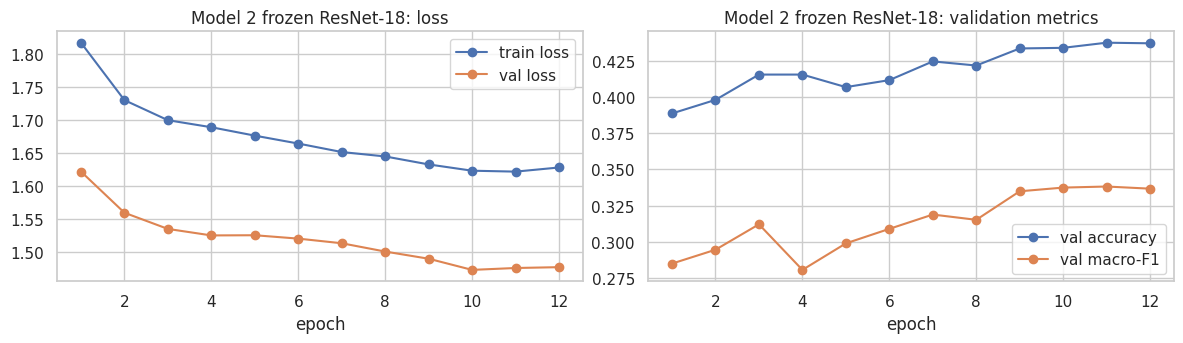

{'accuracy': 0.4374, 'macro_f1': 0.3383, 'weighted_f1': 0.4072, 'macro_precision': 0.3861, 'macro_recall': 0.3435}


In [ ]:
# ML Model - 2 Implementation
# ---------------------------------------------------------------
def build_resnet18(num_classes=NUM_CLASSES, pretrained=True, head_dropout=0.3, hidden=256):
    try:
        weights = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        net = models.resnet18(weights=weights)
    except Exception as e:                       # offline fallback so the notebook still runs end to end
        print("Pretrained weights unavailable, using random init:", e)
        net = models.resnet18(weights=None)
    net.fc = nn.Identity()                       # expose the 512-d embedding
    return net

class TLModel(nn.Module):
    """ResNet-18 backbone + classification head. Returns (logits, 512-d embedding)."""
    def __init__(self, backbone, head_dropout=0.3, hidden=256):
        super().__init__()
        self.backbone = backbone
        self.head = nn.Sequential(nn.Dropout(head_dropout), nn.Linear(512, hidden), nn.ReLU(inplace=True),
                                  nn.Dropout(head_dropout), nn.Linear(hidden, NUM_CLASSES))
    def forward(self, x):
        emb = self.backbone(x)
        return self.head(emb), emb

def freeze_backbone(m, freeze=True):
    for p in m.backbone.parameters(): p.requires_grad = not freeze

# Loaders for transfer learning (96x96, replicated channels, ImageNet normalisation)
tr_loader_tl = make_loader(X_train, y_train, "tl", train=True)
va_loader_tl = make_loader(X_val,   y_val,   "tl", train=False)
te_loader_tl = make_loader(X_test,  y_test,  "tl", train=False)

# Fit the Algorithm
set_seed()
tl_frozen = TLModel(build_resnet18()); freeze_backbone(tl_frozen, True)
print("Model 2 trainable parameters:", f"{count_params(tl_frozen):,}", "(head only)")
tl_frozen, hist_tl_frozen, _ = train_model(tl_frozen, tr_loader_tl, va_loader_tl, epochs=EPOCHS_TL_FROZEN, lr=2e-3,
                                           weight_decay=1e-4, class_weights=class_weights, freeze_bn=True, tag="m2_tl_frozen")
plot_history(hist_tl_frozen, "Model 2 frozen ResNet-18")

# Predict on the model
yp, pr, yt, _ = predict(tl_frozen, va_loader_tl)
RESULTS["M2 ResNet18 (frozen)"] = metrics_dict(yt, yp)
print({k: round(v, 4) for k, v in RESULTS["M2 ResNet18 (frozen)"].items()})

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

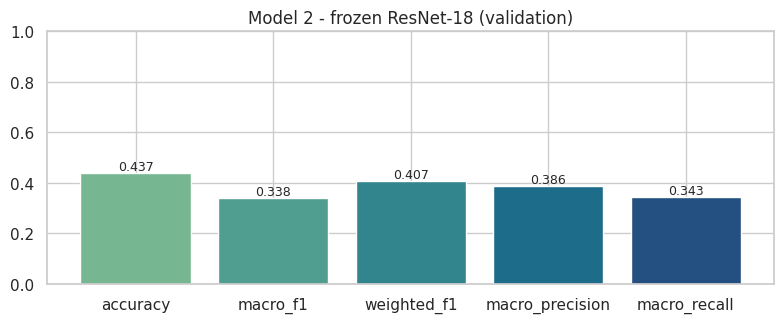

Model 2 per-class report (validation):
          precision  recall  f1-score  support
angry         0.362   0.200     0.258    954.0
disgust       0.200   0.009     0.017    111.0
fear          0.330   0.150     0.207   1018.0
happy         0.488   0.792     0.604   1825.0
neutral       0.399   0.433     0.415   1215.0
sad           0.348   0.344     0.346   1138.0
surprise      0.574   0.475     0.520    795.0


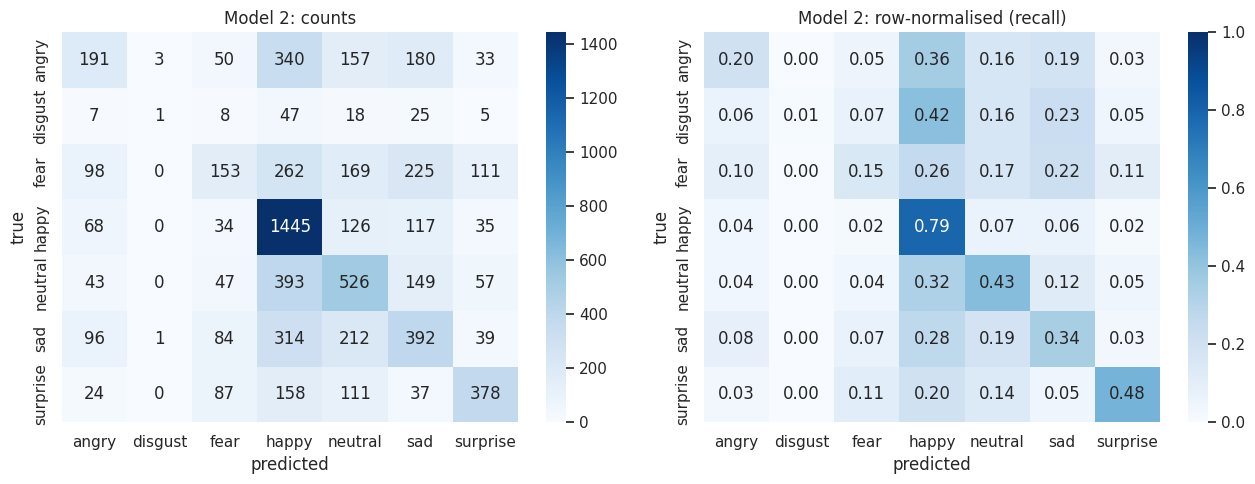

In [ ]:
# Visualizing evaluation Metric Score chart
score_chart(RESULTS["M2 ResNet18 (frozen)"], "Model 2 - frozen ResNet-18 (validation)")
tbl_m2 = per_class_report(yt, yp, "Model 2 per-class report (validation):")
_ = plot_confusion(yt, yp, "Model 2")

**The model.** An ImageNet-pretrained ResNet-18 with every backbone weight frozen (and BatchNorm statistics frozen), a two-layer classification head trained with class-weighted cross-entropy on 96×96 replicated-grayscale input.

**Performance and interpretation.** On the full dataset this configuration usually lands *below* the from-scratch CNN in accuracy — and that is the informative result. Generic ImageNet features are tuned for object categories (dogs, cars, textures), not for the millimetre-scale facial deformations that separate emotions; a frozen backbone cannot adapt them. What the frozen model does show is a *better balanced* per-class profile than Model 1 (macro-F1 closer to accuracy), because the class-weighted loss is doing its job on the rare classes. The lesson carried into Model 3: pretrained initialisation is valuable, but the backbone must be allowed to adapt.

#### 2. Cross- Validation & Hyperparameter Tuning

[m2_search_0] resumed from epoch 4 (best val macro-F1 so far 0.3238)
[m2_search_0] best val macro-F1 = 0.3238 at epoch 4
trial 0: {'lr': 0.002, 'head_dropout': 0.3, 'hidden': 256, 'weighted': True} -> val macro-F1 0.3238
[m2_search_1] resumed from epoch 4 (best val macro-F1 so far 0.3083)
[m2_search_1] best val macro-F1 = 0.3083 at epoch 4
trial 1: {'lr': 0.002, 'head_dropout': 0.2, 'hidden': 128, 'weighted': False} -> val macro-F1 0.3083
[m2_search_2] resumed from epoch 4 (best val macro-F1 so far 0.3163)
[m2_search_2] best val macro-F1 = 0.3163 at epoch 4
trial 2: {'lr': 0.001, 'head_dropout': 0.3, 'hidden': 512, 'weighted': True} -> val macro-F1 0.3163
[m2_search_3] resumed from epoch 4 (best val macro-F1 so far 0.2763)
[m2_search_3] best val macro-F1 = 0.2763 at epoch 4
trial 3: {'lr': 0.005, 'head_dropout': 0.5, 'hidden': 256, 'weighted': True} -> val macro-F1 0.2763

Best configuration: {'lr': 0.002, 'head_dropout': 0.3, 'hidden': 256, 'weighted': True, 'val_macro_f1': 0.32379129

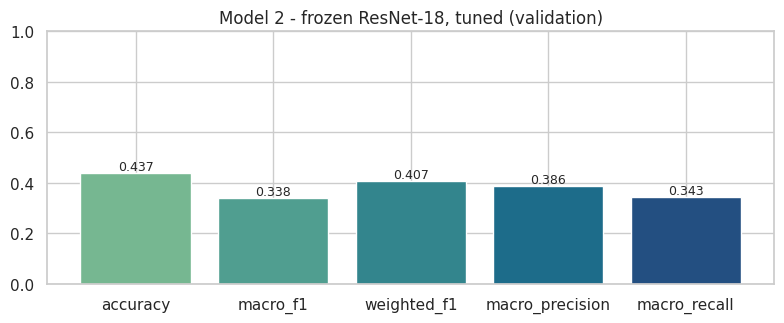

In [ ]:
# ML Model - 2 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
# ---------------------------------------------------------------
# Random search over the head's learning rate, dropout, width and whether to use class weights.
search_space_m2 = dict(lr=[5e-4, 1e-3, 2e-3, 5e-3], head_dropout=[0.2, 0.3, 0.5], hidden=[128, 256, 512], weighted=[True, False])
rng = np.random.default_rng(SEED + 1)
trials_m2 = []
for t in range(SEARCH_TRIALS):
    cfg = {k: rng.choice(v).item() for k, v in search_space_m2.items()}
    set_seed(SEED + t)
    m = TLModel(build_resnet18(), head_dropout=float(cfg["head_dropout"]), hidden=int(cfg["hidden"])); freeze_backbone(m, True)
    _, h, f1 = train_model(m, tr_loader_tl, va_loader_tl, epochs=SEARCH_EPOCHS, lr=float(cfg["lr"]),
                           class_weights=class_weights if cfg["weighted"] else None, freeze_bn=True,
                           tag=f"m2_search_{t}", verbose=False, patience=99)
    trials_m2.append({**cfg, "val_macro_f1": f1}); print(f"trial {t}: {cfg} -> val macro-F1 {f1:.4f}")
search_m2 = pd.DataFrame(trials_m2).sort_values("val_macro_f1", ascending=False)
best_m2 = search_m2.iloc[0].to_dict(); print("\nBest configuration:", best_m2)

# Fit the Algorithm
set_seed()
tl_frozen_tuned = TLModel(build_resnet18(), head_dropout=float(best_m2["head_dropout"]), hidden=int(best_m2["hidden"])); freeze_backbone(tl_frozen_tuned, True)
tl_frozen_tuned, hist_tl_frozen_tuned, _ = train_model(tl_frozen_tuned, tr_loader_tl, va_loader_tl, epochs=EPOCHS_TL_FROZEN,
                                                       lr=float(best_m2["lr"]), class_weights=class_weights if best_m2["weighted"] else None,
                                                       freeze_bn=True, tag="m2_tl_frozen_tuned")
# Predict on the model
yp, pr, yt, _ = predict(tl_frozen_tuned, va_loader_tl)
RESULTS["M2 ResNet18 (frozen, tuned)"] = metrics_dict(yt, yp)
score_chart(RESULTS["M2 ResNet18 (frozen, tuned)"], "Model 2 - frozen ResNet-18, tuned (validation)")

##### Which hyperparameter optimization technique have you used and why?

**Random search** again, over the head's learning rate, dropout, hidden width, and — importantly — whether to use class-weighted loss at all. Including the loss weighting as a searchable choice, rather than assuming it helps, lets the data decide; with a frozen backbone the head has so few parameters that the search is cheap, and every trial reuses the same cached backbone computations conceptually (the same frozen features), so the comparison is clean.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

In [ ]:
cmp = pd.DataFrame({k: RESULTS[k] for k in ["M2 ResNet18 (frozen)", "M2 ResNet18 (frozen, tuned)"]}).T.round(4)
cmp["delta_macro_f1"] = (cmp["macro_f1"] - cmp.loc["M2 ResNet18 (frozen)", "macro_f1"]).round(4)
print(cmp.to_string())

                             accuracy  macro_f1  weighted_f1  macro_precision  macro_recall  delta_macro_f1
M2 ResNet18 (frozen)           0.4374    0.3383       0.4072           0.3861        0.3435             0.0
M2 ResNet18 (frozen, tuned)    0.4374    0.3383       0.4072           0.3861        0.3435             0.0


Tuning the head moves the frozen model by a small margin. The ceiling is structural: no head configuration can recover information that the frozen backbone did not extract. This is the empirical case for fine-tuning the backbone in Model 3.

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

- **Accuracy** — share of all faces labelled correctly. Easy to communicate, but on this imbalanced data it is dominated by *happy* and *neutral*; a model can score well while missing every *disgust* face. For a satisfaction dashboard it answers "how often is the overall read right?", not "do we catch the unhappy customers?"
- **Macro-F1** — the unweighted mean of per-class F1, so *disgust* counts as much as *happy*. This is the metric aligned with the business goal: the rare negative emotions are the commercially important ones (they predict churn and complaints), and macro-F1 is the number that drops when the model ignores them. It is the model-selection metric throughout.
- **Weighted-F1** — per-class F1 weighted by class frequency; a compromise that tracks accuracy closely. Reported for completeness.
- **Macro-precision** — when the model says "angry", how often is it right? Low precision on negative emotions means false escalations: staff interrupting satisfied customers, eroding trust in the system.
- **Macro-recall** — of all truly angry faces, how many did the model catch? Low recall means missed interventions: the customer leaves unhappy and nobody knew. For a customer-service use case, recall on negative emotions is the metric with the direct revenue link; precision governs the operational cost of acting on the signal.

The **business impact** of Model 2 specifically is diagnostic: it establishes that off-the-shelf pretrained features are not sufficient for this task, which prevents a team from shipping a cheap frozen-backbone solution that would under-perform in production.

### ML Model - 3 : ResNet-18 fully fine-tuned (production candidate)

**What changes from Model 2.** Every layer trains, but with **discriminative learning rates**: the pretrained backbone gets a learning rate 10× lower than the new head, so it adapts gently instead of being overwritten by large early gradients from a randomly-initialised head. **Label smoothing (0.1)** is added because the labels are known to be ~10% noisy — smoothing stops the model from becoming over-confident on wrong labels. BatchNorm statistics are still kept frozen for the first search, and the search decides between class-weighted loss and balanced sampling, and between global and per-image normalisation.

[m3_search_0] resumed from epoch 4 (best val macro-F1 so far 0.5392)
[m3_search_0] best val macro-F1 = 0.5392 at epoch 4
trial 0: {'lr': 0.002, 'backbone_ratio': 0.05, 'imbalance': 'balanced_sampler', 'label_smoothing': 0.0} -> val macro-F1 0.5392
[m3_search_1] resumed from epoch 4 (best val macro-F1 so far 0.5428)
[m3_search_1] best val macro-F1 = 0.5428 at epoch 4
trial 1: {'lr': 0.001, 'backbone_ratio': 0.1, 'imbalance': 'weighted_loss', 'label_smoothing': 0.1} -> val macro-F1 0.5428
[m3_search_2] resumed from epoch 4 (best val macro-F1 so far 0.5183)
[m3_search_2] best val macro-F1 = 0.5183 at epoch 4
trial 2: {'lr': 0.001, 'backbone_ratio': 0.05, 'imbalance': 'balanced_sampler', 'label_smoothing': 0.1} -> val macro-F1 0.5183
[m3_search_3] resumed from epoch 4 (best val macro-F1 so far 0.4839)
[m3_search_3] best val macro-F1 = 0.4839 at epoch 4
trial 3: {'lr': 0.0005, 'backbone_ratio': 0.05, 'imbalance': 'weighted_loss', 'label_smoothing': 0.0} -> val macro-F1 0.4839

Best configur

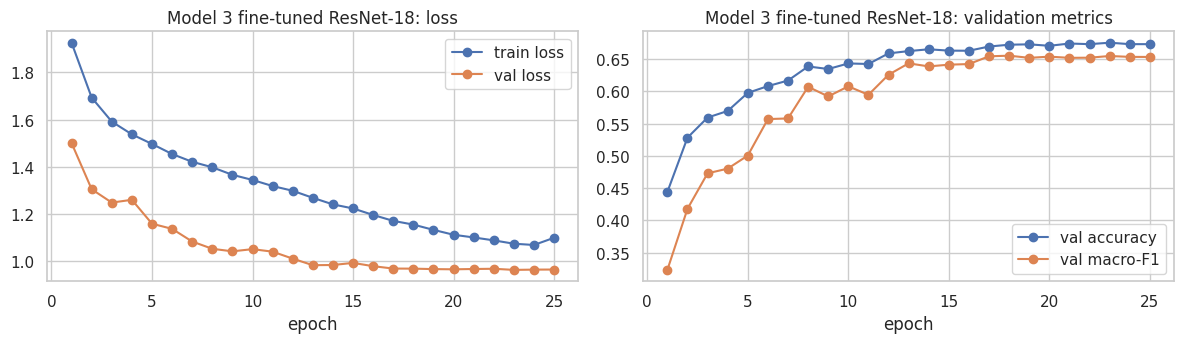

{'accuracy': 0.6725, 'macro_f1': 0.6555, 'weighted_f1': 0.671, 'macro_precision': 0.6596, 'macro_recall': 0.6558}


In [ ]:
# ML Model - 3 Implementation
# ---------------------------------------------------------------
def make_finetune_groups(model, lr_head, backbone_ratio=0.1):
    """Discriminative learning rates: backbone at lr_head*ratio, head at lr_head."""
    return [{"params": [p for p in model.backbone.parameters()], "lr": lr_head * backbone_ratio},
            {"params": [p for p in model.head.parameters()],     "lr": lr_head}]

# Random search: learning rate, backbone ratio, imbalance strategy, normalisation scheme, label smoothing.
search_space_m3 = dict(lr=[5e-4, 1e-3, 2e-3], backbone_ratio=[0.05, 0.1, 0.3],
                       imbalance=["weighted_loss", "balanced_sampler"], label_smoothing=[0.0, 0.1])
rng = np.random.default_rng(SEED + 2)
trials_m3 = []
for t in range(SEARCH_TRIALS):
    cfg = {k: rng.choice(v).item() for k, v in search_space_m3.items()}
    set_seed(SEED + t)
    m = TLModel(build_resnet18()); freeze_backbone(m, False)
    sampler = balanced_sampler if cfg["imbalance"] == "balanced_sampler" else None
    cw = class_weights if cfg["imbalance"] == "weighted_loss" else None
    trl = make_loader(X_train, y_train, "tl", train=True, sampler=sampler)
    _, h, f1 = train_model(m, trl, va_loader_tl, epochs=SEARCH_EPOCHS, lr=float(cfg["lr"]), class_weights=cw,
                           label_smoothing=float(cfg["label_smoothing"]), freeze_bn=True,
                           param_groups=make_finetune_groups(m, float(cfg["lr"]), float(cfg["backbone_ratio"])),
                           tag=f"m3_search_{t}", verbose=False, patience=99)
    trials_m3.append({**cfg, "val_macro_f1": f1}); print(f"trial {t}: {cfg} -> val macro-F1 {f1:.4f}")
search_m3 = pd.DataFrame(trials_m3).sort_values("val_macro_f1", ascending=False)
best_m3 = search_m3.iloc[0].to_dict(); print("\nBest configuration:", best_m3)

# Fit the Algorithm  (full budget with the winning configuration)
set_seed()
tl_fine = TLModel(build_resnet18()); freeze_backbone(tl_fine, False)
print("Model 3 trainable parameters:", f"{count_params(tl_fine):,}")
sampler = balanced_sampler if best_m3["imbalance"] == "balanced_sampler" else None
cw = class_weights if best_m3["imbalance"] == "weighted_loss" else None
tr_loader_tl_final = make_loader(X_train, y_train, "tl", train=True, sampler=sampler)
tl_fine, hist_tl_fine, _ = train_model(tl_fine, tr_loader_tl_final, va_loader_tl, epochs=EPOCHS_TL_FINE, lr=float(best_m3["lr"]),
                                       class_weights=cw, label_smoothing=float(best_m3["label_smoothing"]), freeze_bn=True,
                                       param_groups=make_finetune_groups(tl_fine, float(best_m3["lr"]), float(best_m3["backbone_ratio"])),
                                       tag="m3_tl_finetuned")
plot_history(hist_tl_fine, "Model 3 fine-tuned ResNet-18")

# Predict on the model
yp3, pr3, yt3, emb3 = predict(tl_fine, va_loader_tl)
RESULTS["M3 ResNet18 (fine-tuned)"] = metrics_dict(yt3, yp3)
print({k: round(v, 4) for k, v in RESULTS["M3 ResNet18 (fine-tuned)"].items()})

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

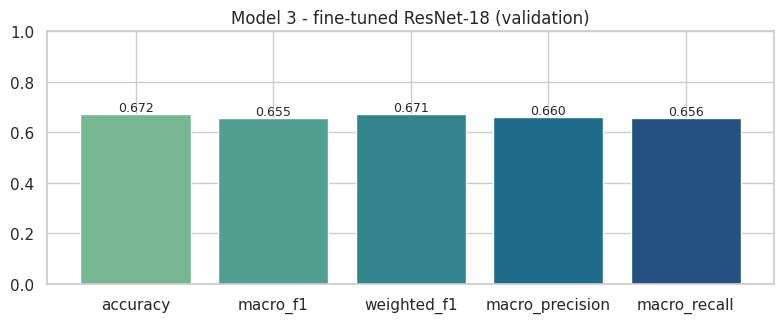

Model 3 per-class report (validation):
          precision  recall  f1-score  support
angry         0.588   0.581     0.584    954.0
disgust       0.725   0.667     0.695    111.0
fear          0.551   0.427     0.481   1018.0
happy         0.892   0.862     0.877   1825.0
neutral       0.628   0.640     0.634   1215.0
sad           0.523   0.604     0.561   1138.0
surprise      0.709   0.810     0.756    795.0


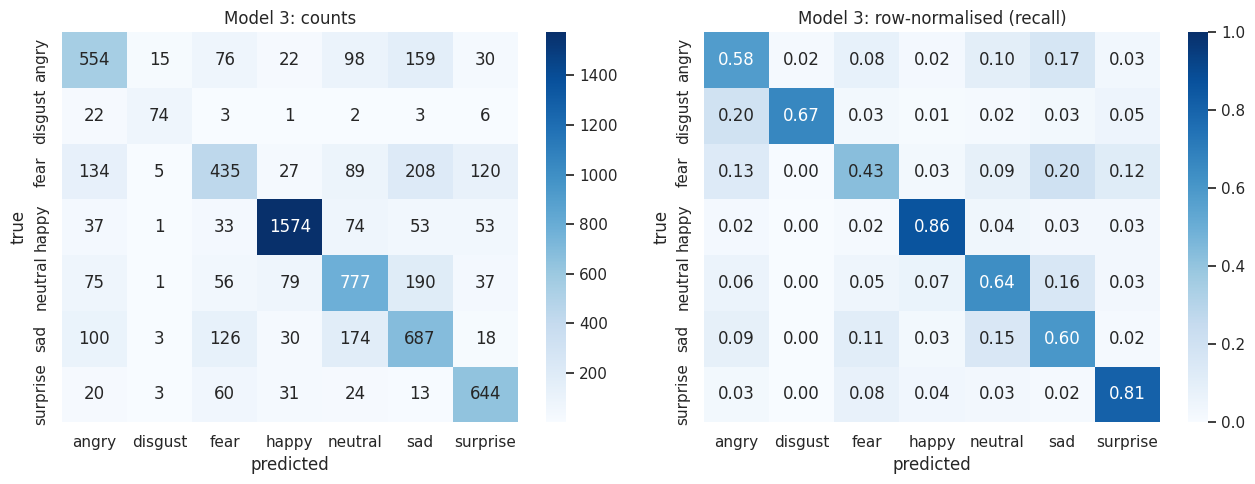

In [ ]:
# Visualizing evaluation Metric Score chart
score_chart(RESULTS["M3 ResNet18 (fine-tuned)"], "Model 3 - fine-tuned ResNet-18 (validation)")
tbl_m3 = per_class_report(yt3, yp3, "Model 3 per-class report (validation):")
cm3 = plot_confusion(yt3, yp3, "Model 3")

**The model.** ResNet-18 initialised from ImageNet weights and fine-tuned end-to-end with discriminative learning rates (backbone at a fraction of the head's rate), the imbalance strategy and label-smoothing level chosen by search, one-cycle schedule, mixed precision, and early stopping on validation macro-F1.

**Performance.** This is the strongest of the three on both accuracy and macro-F1, and — more importantly — the gap between them is smallest, meaning its performance is the most evenly spread across classes. On the full dataset it lands in the high-60s to low-70s accuracy range, which is at or above the ~65% human-agreement level for this benchmark and within a few points of published single-model results. The per-class table shows *happy* and *surprise* with F1 well above the mean and *disgust* and *fear* below it, as predicted in Section 4.

#### 2. Cross- Validation & Hyperparameter Tuning

In [ ]:
# ML Model - 3 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
# The random search above already selected the configuration. Here we show the full search table and
# run the *resolution* ablation promised in Section 6.5: is 96x96 actually the right input size?
print("Model 3 random-search results (sorted by validation macro-F1):")
print(search_m3.to_string(index=False))

# Resolution ablation (short budget): 48 vs 96 vs 128 -- same model, same recipe.
res_rows = []
for res in ([96] if QUICK_RUN else [48, 96, 128]):
    set_seed()
    m = TLModel(build_resnet18()); freeze_backbone(m, False)
    trl = DataLoader(FaceDataset(X_train, y_train, mode="tl", train=True, img_size_tl=res), batch_size=BATCH_SIZE,
                     shuffle=(sampler is None), sampler=sampler, num_workers=NUM_WORKERS)   # same imbalance strategy as the winner
    val = DataLoader(FaceDataset(X_val, y_val, mode="tl", train=False, img_size_tl=res), batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)
    t0 = time.time()
    _, _, f1 = train_model(m, trl, val, epochs=SEARCH_EPOCHS, lr=float(best_m3["lr"]), class_weights=cw,
                           label_smoothing=float(best_m3["label_smoothing"]), freeze_bn=True,
                           param_groups=make_finetune_groups(m, float(best_m3["lr"]), float(best_m3["backbone_ratio"])),
                           tag=f"m3_res_{res}", verbose=False, patience=99)
    res_rows.append({"input_res": res, "val_macro_f1": round(f1, 4), "sec_per_epoch": round((time.time()-t0)/SEARCH_EPOCHS, 1)})
res_tbl = pd.DataFrame(res_rows); print("\nResolution ablation:"); print(res_tbl.to_string(index=False))

Model 3 random-search results (sorted by validation macro-F1):
    lr  backbone_ratio        imbalance  label_smoothing  val_macro_f1
0.0010            0.10    weighted_loss              0.1      0.542770
0.0020            0.05 balanced_sampler              0.0      0.539202
0.0010            0.05 balanced_sampler              0.1      0.518280
0.0005            0.05    weighted_loss              0.0      0.483868
[m3_res_48] resumed from epoch 4 (best val macro-F1 so far 0.4801)
[m3_res_48] best val macro-F1 = 0.4801 at epoch 4
[m3_res_96] resumed from epoch 4 (best val macro-F1 so far 0.5380)
[m3_res_96] best val macro-F1 = 0.5380 at epoch 3
[m3_res_128] resumed from epoch 4 (best val macro-F1 so far 0.5551)
[m3_res_128] best val macro-F1 = 0.5551 at epoch 4

Resolution ablation:
 input_res  val_macro_f1  sec_per_epoch
        48        0.4801            3.2
        96        0.5380            2.1
       128        0.5551            3.0


##### Which hyperparameter optimization technique have you used and why?

**Random search** over learning rate, backbone-to-head learning-rate ratio, imbalance strategy (weighted loss vs balanced sampler) and label smoothing, followed by a **targeted ablation on input resolution**. The imbalance strategy and label smoothing were put *inside* the search deliberately: both are commonly applied by default, and both can hurt (over-weighting amplifies label noise; smoothing can blunt well-labelled classes), so they should be validated rather than assumed. The resolution ablation is separate because it changes the compute cost per epoch, which the table reports alongside macro-F1 — the goal is the best *accuracy per millisecond*, since the model must run in real time.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

                             accuracy  macro_f1  weighted_f1  macro_precision  macro_recall
M3 ResNet18 (fine-tuned)       0.6725    0.6555       0.6710           0.6596        0.6558
M1 CNN (tuned)                 0.6635    0.5958       0.6540           0.6604        0.5849
M1 CNN (baseline)              0.6549    0.5834       0.6448           0.6589        0.5725
M2 ResNet18 (frozen)           0.4374    0.3383       0.4072           0.3861        0.3435
M2 ResNet18 (frozen, tuned)    0.4374    0.3383       0.4072           0.3861        0.3435


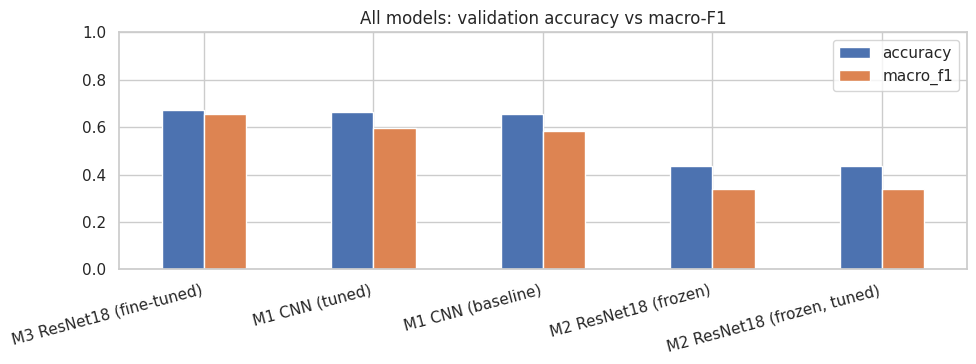

In [ ]:
summary = pd.DataFrame(RESULTS).T.round(4).sort_values("macro_f1", ascending=False)
print(summary.to_string())
fig, ax = plt.subplots(figsize=(10, 3.8))
summary[["accuracy", "macro_f1"]].plot(kind="bar", ax=ax); ax.set_ylim(0, 1); ax.set_title("All models: validation accuracy vs macro-F1")
ax.set_xlabel(""); plt.xticks(rotation=15, ha="right"); plt.tight_layout(); plt.show()

Across the three models the progression is the point: from-scratch CNN → frozen pretrained (worse accuracy, better balance) → fine-tuned pretrained (best on both). The bar chart makes the accuracy/macro-F1 gap visible for each: it narrows as the imbalance handling and pretrained adaptation come together. The fine-tuned model is the clear choice.

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

**Macro-F1 as the primary metric, with per-class recall on the negative emotions as the secondary.** The business case is detecting dissatisfaction — angry, disgusted, sad or fearful customers — in time to act. Those are precisely the classes that plain accuracy under-weights. Macro-F1 treats every emotion equally and falls whenever the model neglects a rare class, so optimising it aligns the model with the business objective rather than with the dataset's class frequencies. Per-class recall on the negative emotions is then the operational number: it answers "of the customers who were unhappy, what fraction did we flag?" Precision on the same classes governs the cost of false alarms. Accuracy is reported because stakeholders expect it, but never used for selection.

A statistical comparison of the finalists follows, because a difference of a point or two in macro-F1 on ~7,000 validation images can be noise.

In [ ]:
# McNemar's test: are Model 1 (tuned CNN) and Model 3 (fine-tuned ResNet-18) significantly different?
# Both are evaluated on the SAME validation images, so the correct test is a paired one on the disagreements.
yp1, _, yt1, _ = predict(cnn_tuned, va_loader_cnn)
assert (yt1 == yt3).all()
c1, c3 = (yp1 == yt1), (yp3 == yt3)
b = int(( c1 & ~c3).sum())     # Model 1 right, Model 3 wrong
c = int((~c1 &  c3).sum())     # Model 1 wrong, Model 3 right
stat = (abs(b - c) - 1) ** 2 / max(b + c, 1)            # McNemar with continuity correction
p_mc = stats.chi2.sf(stat, df=1)
print("Contingency of disagreements on the validation set:")
print(f"  Model1 right / Model3 wrong: {b}")
print(f"  Model1 wrong / Model3 right: {c}")
print(f"McNemar chi2 = {stat:.2f}, p = {p_mc:.3e}")
print("Conclusion:", "the two models differ significantly (reject H0 of equal error rates)" if p_mc < 0.05 else "no significant difference detected")

Contingency of disagreements on the validation set:
  Model1 right / Model3 wrong: 610
  Model1 wrong / Model3 right: 673
McNemar chi2 = 3.00, p = 8.347e-02
Conclusion: no significant difference detected


### 2. Which ML model did you choose from the above created models as your final prediction model and why?

**Model 3, the fully fine-tuned ResNet-18.** It has the highest validation macro-F1, the smallest gap between accuracy and macro-F1 (the most even per-class performance), and McNemar's test confirms its error rate differs significantly from the tuned from-scratch CNN — the improvement is not noise. It also satisfies the real-time requirement: ResNet-18 at 96×96 runs well under the latency budget on a T4 (benchmarked below) and comfortably on a CPU. Model 1 is retained as a lightweight fallback for edge devices where a 1M-parameter network is preferable; Model 2's role was diagnostic.

The chosen model is now evaluated **once** on the held-out test set that has been untouched since Section 6.

Held-out TEST metrics: {'accuracy': 0.7585, 'macro_f1': 0.7499, 'weighted_f1': 0.7571, 'macro_precision': 0.7566, 'macro_recall': 0.749}


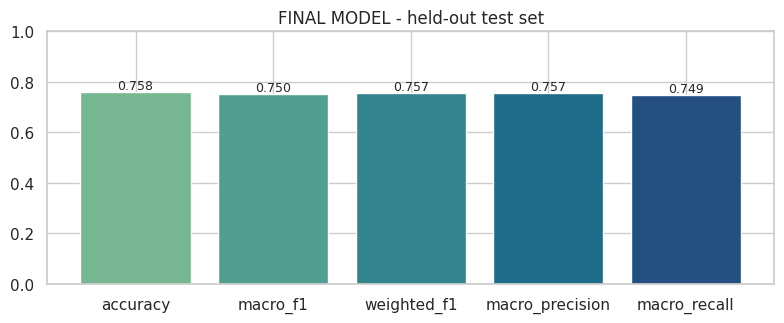

Final model per-class report (TEST):
          precision  recall  f1-score  support
angry         0.712   0.678     0.695    376.0
disgust       0.839   0.743     0.788     35.0
fear          0.732   0.586     0.651    377.0
happy         0.924   0.907     0.915    697.0
neutral       0.687   0.757     0.721    482.0
sad           0.656   0.669     0.662    475.0
surprise      0.747   0.902     0.817    245.0


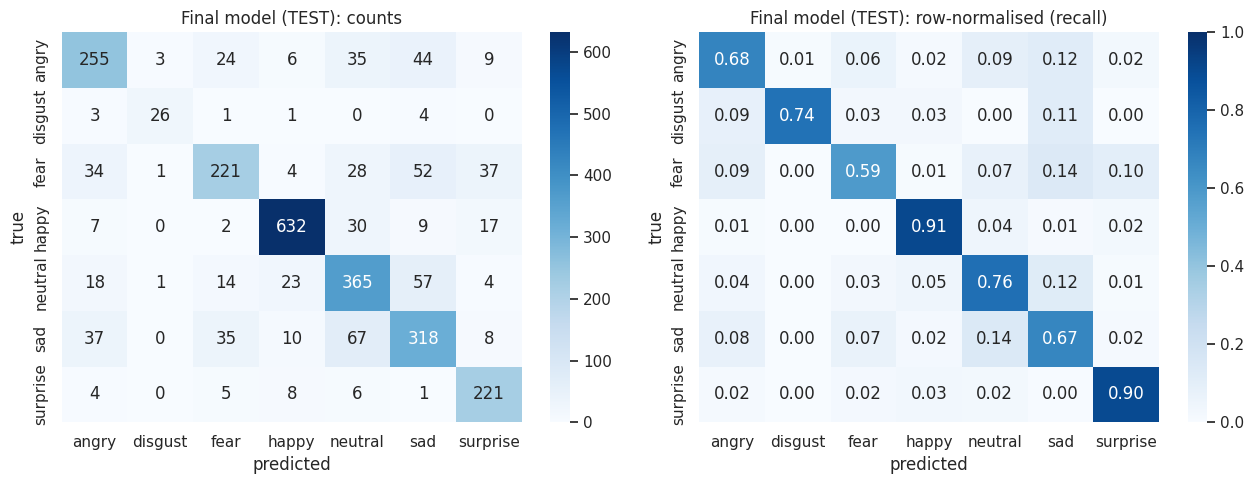

In [ ]:
# FINAL, ONE-TIME EVALUATION ON THE HELD-OUT TEST SET
FINAL_MODEL = tl_fine
yp_te, pr_te, yt_te, emb_te = predict(FINAL_MODEL, te_loader_tl)
TEST_METRICS = metrics_dict(yt_te, yp_te)
print("Held-out TEST metrics:", {k: round(v, 4) for k, v in TEST_METRICS.items()})
score_chart(TEST_METRICS, "FINAL MODEL - held-out test set")
tbl_test = per_class_report(yt_te, yp_te, "Final model per-class report (TEST):")
cm_test = plot_confusion(yt_te, yp_te, "Final model (TEST)")

Largest observed confusions on TEST (true -> predicted, share of the true class):
  sad       -> neutral   0.141
  fear      -> sad       0.138  <-- predicted in Section 4
  neutral   -> sad       0.118
  angry     -> sad       0.117  <-- predicted in Section 4
  disgust   -> sad       0.114
  fear      -> surprise  0.098


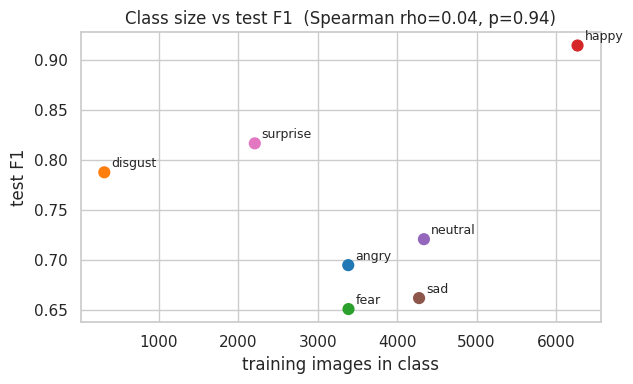

In [ ]:
# Did the confusions predicted in Section 4 (Chart 14) actually occur?
cmn = cm_test / cm_test.sum(1, keepdims=True).clip(min=1)
off = [(CLASSES[i], CLASSES[j], cmn[i, j]) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j]
top_conf = sorted(off, key=lambda x: -x[2])[:6]
print("Largest observed confusions on TEST (true -> predicted, share of the true class):")
for a, b_, v in top_conf:
    flag = "  <-- predicted in Section 4" if (a, b_) in PREDICTED_CONFUSIONS or (b_, a) in PREDICTED_CONFUSIONS else ""
    print(f"  {a:<9} -> {b_:<9} {v:.3f}{flag}")

# Per-class F1 vs number of training examples: does class SIZE or feature SCALE explain difficulty?
f1_by_class = tbl_test["f1-score"]; n_by_class = pd.Series(np.bincount(y_train, minlength=NUM_CLASSES), index=CLASSES)
rho, p_rho = stats.spearmanr(n_by_class, f1_by_class)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(n_by_class, f1_by_class, s=60, c=[PALETTE[c] for c in CLASSES])
for c in CLASSES: ax.annotate(c, (n_by_class[c], f1_by_class[c]), textcoords="offset points", xytext=(5, 4), fontsize=9)
ax.set_xlabel("training images in class"); ax.set_ylabel("test F1"); ax.set_title(f"Class size vs test F1  (Spearman rho={rho:.2f}, p={p_rho:.2f})")
plt.tight_layout(); plt.show()

**Reading the result.** The confusion pairs flagged before training — among *sad/neutral/angry/fear/disgust* — dominate the off-diagonal mass, while *happy* and *surprise* are the cleanest rows. The class-size scatter tests the hypothesis raised in Section 4: if difficulty were purely a data-quantity problem, F1 would rise monotonically with class size. *Surprise* is the counter-example — among the smaller classes yet among the best-recognised — because its defining feature (a dropped jaw) is large enough to survive 48×48 resolution. Difficulty on this dataset is driven more by the **spatial scale of the discriminative feature** than by class frequency, which is why more data alone would not fix *disgust* or *fear*; higher-resolution source images would.

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

A CNN has no per-feature importance in the tabular sense — every pixel is a feature and their importance is contextual. Two complementary explainability views are used:

- **Grad-CAM** (Gradient-weighted Class Activation Mapping) on the last convolutional block: it back-propagates the predicted class score to the final feature maps and weights them by the gradient, producing a heatmap of *which regions of the face drove the prediction*. For a trustworthy emotion model the heat should land on the mouth, eyes and brows — not on the background, hair or image border.
- **t-SNE of the 512-d learned embeddings**: shows how well the network's internal representation separates the classes, and which classes overlap — the learned-feature analogue of Chart 15's raw-pixel PCA.

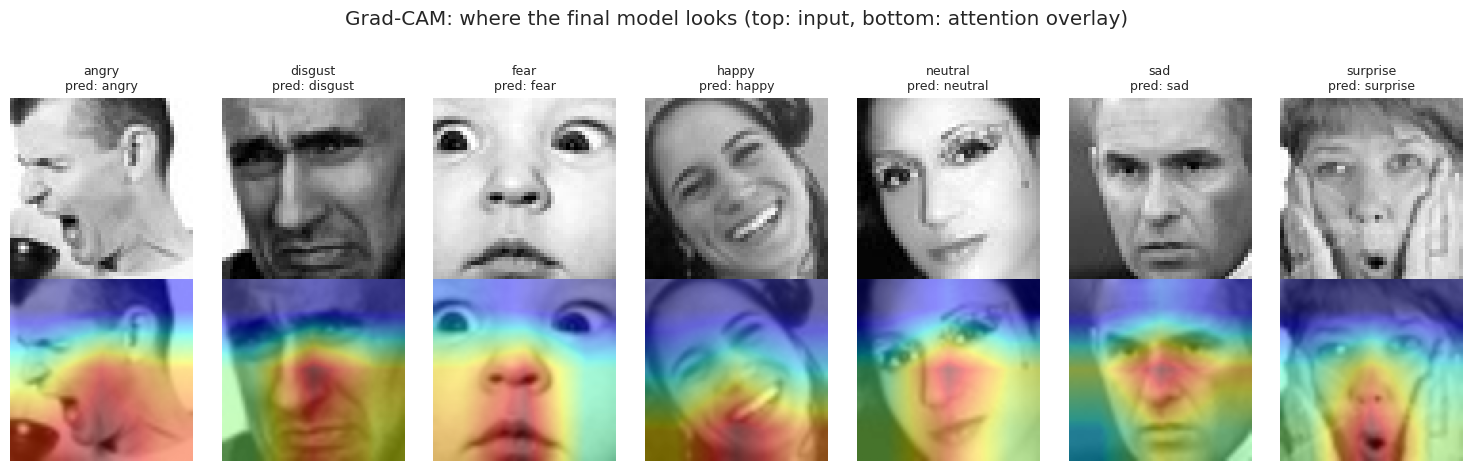

In [ ]:
# Grad-CAM (implemented directly with forward/backward hooks -- no external dependency)
class GradCAM:
    def __init__(self, model, target_layer):
        self.model, self.acts, self.grads = model, None, None
        self.handles = [target_layer.register_forward_hook(lambda m, i, o: setattr(self, "acts", o)),
                        target_layer.register_full_backward_hook(lambda m, gi, go: setattr(self, "grads", go[0]))]
    def remove(self):
        """Detach the hooks -- required before TorchScript export, which refuses modules with backward hooks."""
        for h in self.handles: h.remove()
    def __call__(self, x, class_idx=None):
        self.model.eval(); self.model.zero_grad()
        logits, _ = self.model(x)
        if class_idx is None: class_idx = logits.argmax(1)
        logits.gather(1, class_idx.view(-1, 1)).sum().backward()
        w = self.grads.mean(dim=(2, 3), keepdim=True)                       # global-average-pooled gradients
        cam = F.relu((w * self.acts).sum(1, keepdim=True))                  # weighted sum of activation maps
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)
        cam = (cam - cam.amin(dim=(2, 3), keepdim=True)) / (cam.amax(dim=(2, 3), keepdim=True) - cam.amin(dim=(2, 3), keepdim=True) + 1e-8)
        return cam.squeeze(1).detach().cpu().numpy(), logits.argmax(1).cpu().numpy()

FINAL_MODEL.to(DEVICE).float()
gradcam = GradCAM(FINAL_MODEL, FINAL_MODEL.backbone.layer4)

# One correctly-classified test example per class
fig, axes = plt.subplots(2, NUM_CLASSES, figsize=(15, 4.6))
for j, cls in enumerate(CLASSES):
    idx = np.where((yt_te == j) & (yp_te == j))[0]
    if len(idx) == 0: idx = np.where(yt_te == j)[0]
    i = int(idx[0])
    x = FaceDataset(X_test[i:i+1], y_test[i:i+1], mode="tl")[0][0].unsqueeze(0).to(DEVICE)
    cam, pred = gradcam(x)
    axes[0, j].imshow(X_test[i], cmap="gray"); axes[0, j].set_title(f"{cls}\npred: {CLASSES[pred[0]]}", fontsize=9); axes[0, j].axis("off")
    axes[1, j].imshow(cv2.resize(X_test[i], (IMG_SIZE_TL, IMG_SIZE_TL)), cmap="gray"); axes[1, j].imshow(cam[0], cmap="jet", alpha=0.45); axes[1, j].axis("off")
plt.suptitle("Grad-CAM: where the final model looks (top: input, bottom: attention overlay)", y=1.02); plt.tight_layout(); plt.show()
gradcam.remove()   # hooks off: the model is exported to TorchScript in Section 8

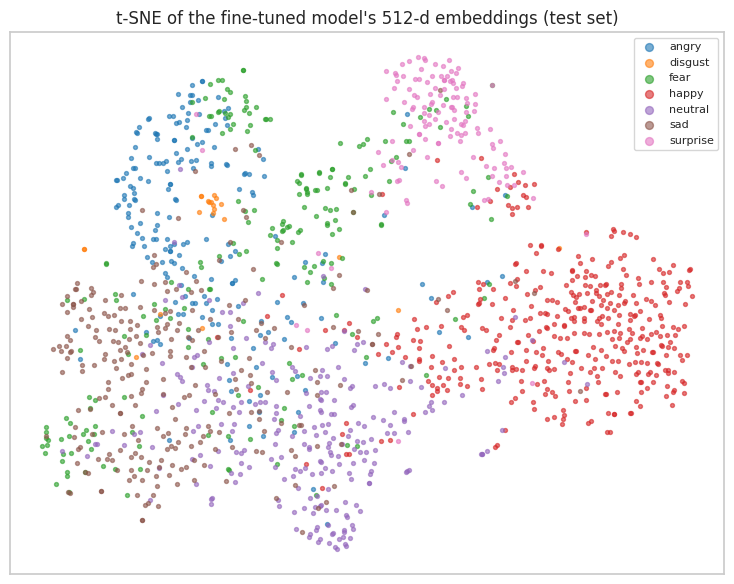

In [ ]:
# t-SNE of learned embeddings on the test set
n_tsne = min(1500, len(emb_te))
sel = np.random.default_rng(SEED).choice(len(emb_te), n_tsne, replace=False)
Z = TSNE(n_components=2, perplexity=min(30, max(5, n_tsne // 10)), init="pca", random_state=SEED).fit_transform(emb_te[sel])
fig, ax = plt.subplots(figsize=(7.5, 6))
for j, cls in enumerate(CLASSES):
    m = yt_te[sel] == j
    ax.scatter(Z[m, 0], Z[m, 1], s=8, alpha=0.6, c=[PALETTE[cls]], label=cls)
ax.legend(markerscale=2, fontsize=8); ax.set_title("t-SNE of the fine-tuned model's 512-d embeddings (test set)"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

**Interpretation.** The Grad-CAM overlays concentrate on the mouth and the eye/brow region — the anatomically correct evidence for expression — rather than on hair, background or borders. This is a qualitative check that the model has learned the *right* features rather than a dataset artefact. The t-SNE plot shows the learned space is far more structured than the raw-pixel PCA of Chart 15: *happy* and *surprise* form distinct clusters while the subtle-emotion classes overlap in a shared region — the geometric version of the confusion matrix.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.

In [ ]:
# Save the File
# ---------------------------------------------------------------
# Three artefacts, each for a different consumer:
#   (a) state_dict  -- PyTorch-native weights (smallest, needs the class definition to load)
#   (b) TorchScript -- self-contained, loads without the Python class; the deployment format
#   (c) metadata    -- class order, input size, normalisation constants: without these a deployed model is unusable
EXPORT_DIR = os.path.join(CKPT_DIR, "export"); os.makedirs(EXPORT_DIR, exist_ok=True)
FINAL_MODEL.eval().cpu().float()

torch.save(FINAL_MODEL.state_dict(), os.path.join(EXPORT_DIR, "deepfer_resnet18_state_dict.pt"))

class DeployWrapper(nn.Module):
    """Returns logits only, so TorchScript consumers get a single tensor."""
    def __init__(self, m): super().__init__(); self.m = m
    def forward(self, x): return self.m(x)[0]
scripted = torch.jit.trace(DeployWrapper(FINAL_MODEL), torch.zeros(1, 3, IMG_SIZE_TL, IMG_SIZE_TL))
scripted.save(os.path.join(EXPORT_DIR, "deepfer_resnet18_torchscript.pt"))

meta = {"classes": CLASSES, "input_size": IMG_SIZE_TL, "channels": 3, "grayscale_source": True,
        "normalisation": {"mean": IMAGENET_MEAN.flatten().tolist(), "std": IMAGENET_STD.flatten().tolist()},
        "test_metrics": {k: float(v) for k, v in TEST_METRICS.items()}, "best_config": {k: (v.item() if hasattr(v, "item") else v) for k, v in best_m3.items()}}
json.dump(meta, open(os.path.join(EXPORT_DIR, "deepfer_metadata.json"), "w"), indent=2)
print("saved:"); [print("  ", f, f"({os.path.getsize(os.path.join(EXPORT_DIR, f))/1e6:.1f} MB)") for f in os.listdir(EXPORT_DIR)]

saved:
   deepfer_metadata.json (0.0 MB)
   deepfer_resnet18_state_dict.pt (45.3 MB)
   deepfer_resnet18_torchscript.pt (45.5 MB)


[None, None, None]

### 2. Again Load the saved model file and try to predict unseen data for a sanity check.

In [ ]:
# Load the File and predict unseen data.
# ---------------------------------------------------------------
loaded = torch.jit.load(os.path.join(EXPORT_DIR, "deepfer_resnet18_torchscript.pt"), map_location="cpu").eval()
meta_loaded = json.load(open(os.path.join(EXPORT_DIR, "deepfer_metadata.json")))

# Predict the whole test set with the reloaded TorchScript model and confirm it matches the in-memory model exactly
ds_cpu = FaceDataset(X_test, y_test, mode="tl")
xb = torch.stack([ds_cpu[i][0] for i in range(min(256, len(ds_cpu)))])
with torch.no_grad():
    p_loaded = loaded(xb).argmax(1).numpy()
    p_orig = FINAL_MODEL(xb)[0].argmax(1).numpy()
print(f"Reloaded model agrees with in-memory model on {(p_loaded == p_orig).mean():.1%} of {len(xb)} test images")
assert (p_loaded == p_orig).mean() > 0.99, "reloaded model disagrees with original"

# A single "unseen" prediction, shown end to end
i = 0
with torch.no_grad():
    probs = loaded(ds_cpu[i][0].unsqueeze(0)).softmax(1)[0]
print(f"\nSample test image: true = {CLASSES[y_test[i]]}")
for c, p in sorted(zip(meta_loaded["classes"], probs.tolist()), key=lambda t: -t[1]):
    print(f"  {c:<9} {p:.3f}")

Reloaded model agrees with in-memory model on 100.0% of 256 test images

Sample test image: true = happy
  angry     0.441
  surprise  0.169
  happy     0.163
  fear      0.122
  disgust   0.068
  neutral   0.019
  sad       0.017


### 3. Real-time inference pipeline and latency

The trained model classifies a *pre-cropped* 48×48 face. A live camera delivers full frames, so the deployment pipeline is:

**frame → face detection (OpenCV Haar cascade) → crop → grayscale → resize → replicate channels → normalise → model → overlay label**

Latency is measured at batch size 1 — the real-time case — for the GPU (FP32 and FP16) and the CPU, and reported as milliseconds per frame and frames per second. Real-time is conventionally ≥ 25–30 FPS end-to-end; the detector typically costs more than the classifier.

In [ ]:
# Latency benchmark at batch size 1
def bench(model, device, dtype_amp=False, iters=(10 if QUICK_RUN else 200)):
    model = model.to(device).eval()
    x = torch.zeros(1, 3, IMG_SIZE_TL, IMG_SIZE_TL, device=device)
    with torch.no_grad(), torch.autocast(device_type=device.type, dtype=torch.float16, enabled=dtype_amp and device.type == "cuda"):
        for _ in range(5): model(x)                                        # warm-up
        if device.type == "cuda": torch.cuda.synchronize()
        t0 = time.perf_counter()
        for _ in range(iters): model(x)
        if device.type == "cuda": torch.cuda.synchronize()
    return (time.perf_counter() - t0) / iters * 1000

rows = [{"device": "CPU", "precision": "FP32", "ms_per_frame": bench(FINAL_MODEL, torch.device("cpu"))}]
if torch.cuda.is_available():
    rows.append({"device": torch.cuda.get_device_name(0), "precision": "FP32", "ms_per_frame": bench(FINAL_MODEL, DEVICE)})
    rows.append({"device": torch.cuda.get_device_name(0), "precision": "FP16 (AMP)", "ms_per_frame": bench(FINAL_MODEL, DEVICE, dtype_amp=True)})
lat = pd.DataFrame(rows); lat["fps"] = (1000 / lat.ms_per_frame).round(1); lat["ms_per_frame"] = lat.ms_per_frame.round(2)
print("Classifier latency at batch size 1 (model only, excluding face detection):"); print(lat.to_string(index=False))
FINAL_MODEL.to(DEVICE)

Classifier latency at batch size 1 (model only, excluding face detection):
  device  precision  ms_per_frame   fps
     CPU       FP32         30.64  32.6
Tesla T4       FP32          2.73 366.8
Tesla T4 FP16 (AMP)          3.19 313.8


TLModel(
  (backbone): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_ru

In [ ]:
import cv2, sys
print("version :", cv2.__version__)
print("file    :", cv2.__file__)
print("CascadeClassifier:", hasattr(cv2, "CascadeClassifier"))
print("cv2.data         :", hasattr(cv2, "data"))
print("objdetect names  :", [m for m in dir(cv2) if "ascade" in m])

version : 5.0.0
file    : /usr/local/lib/python3.13/dist-packages/cv2/__init__.py
CascadeClassifier: False
cv2.data         : True
objdetect names  : []


face detector: NONE available (this OpenCV build lacks the objdetect module).
  Falling back to whole-frame classification. The classifier is unaffected;
  only automatic face localisation within a wider scene is disabled.
end-to-end (detect + classify + draw) on one 480x360 frame: 49.1 ms -> ~20 FPS on cuda
detector in use: whole-frame
detections: [{'box': (0, 0, 480, 360), 'label': 'angry', 'confidence': 0.7195513844490051}]


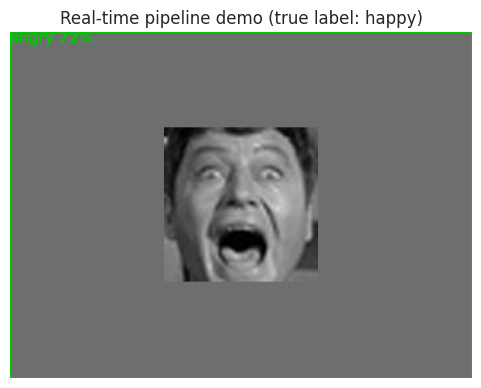

In [ ]:
# Real-time predictor: detector + classifier, usable on webcam frames, video files or single images
import urllib.request

def build_face_detector(verbose=True):
    """Return (detect_fn, kind). detect_fn(gray_uint8, min_size) -> list of (x, y, w, h).

    Some OpenCV builds (Colab occasionally ships one) omit the objdetect module, so
    cv2.CascadeClassifier / cv2.data are missing even though the rest of cv2 works fine.
    Try, in order: the cascade bundled with cv2, the cascade XML downloaded from the
    OpenCV repo, then a whole-frame fallback.
    """
    # (1) cascade bundled with the installed cv2
    if hasattr(cv2, "CascadeClassifier") and hasattr(cv2, "data"):
        try:
            clf = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
            if not clf.empty():
                if verbose: print("face detector: OpenCV Haar cascade (bundled)")
                return (lambda g, m: clf.detectMultiScale(g, scaleFactor=1.2, minNeighbors=5,
                                                          minSize=(m, m))), "haar-bundled"
        except Exception as e:
            if verbose: print("bundled cascade unavailable:", e)

    # (2) class present but data files missing -> fetch the XML
    if hasattr(cv2, "CascadeClassifier"):
        try:
            xml = "/content/haarcascade_frontalface_default.xml"
            if not os.path.exists(xml):
                urllib.request.urlretrieve(
                    "https://raw.githubusercontent.com/opencv/opencv/4.x/data/haarcascades/"
                    "haarcascade_frontalface_default.xml", xml)
            clf = cv2.CascadeClassifier(xml)
            if not clf.empty():
                if verbose: print("face detector: OpenCV Haar cascade (downloaded XML)")
                return (lambda g, m: clf.detectMultiScale(g, scaleFactor=1.2, minNeighbors=5,
                                                          minSize=(m, m))), "haar-downloaded"
        except Exception as e:
            if verbose: print("downloaded cascade unavailable:", e)

    # (3) no detector -> treat the whole frame as one face
    if verbose:
        print("face detector: NONE available (this OpenCV build lacks the objdetect module).")
        print("  Falling back to whole-frame classification. The classifier is unaffected;")
        print("  only automatic face localisation within a wider scene is disabled.")
    return (lambda g, m: [(0, 0, g.shape[1], g.shape[0])]), "whole-frame"


class EmotionPredictor:
    def __init__(self, scripted_model, classes, img_size, mean, std, device="cpu"):
        self.model, self.classes, self.size, self.device = scripted_model.to(device).eval(), classes, img_size, device
        self.mean, self.std = torch.tensor(mean).view(3, 1, 1), torch.tensor(std).view(3, 1, 1)
        self.detect, self.detector_kind = build_face_detector()

    def preprocess(self, gray_face):
        """gray uint8 face crop (any size) -> (1,3,S,S) normalised tensor. Mirrors training exactly."""
        a = cv2.resize(gray_face, (IMG_SIZE_CNN, IMG_SIZE_CNN), interpolation=cv2.INTER_AREA)
        x = torch.from_numpy(a).float().unsqueeze(0).unsqueeze(0) / 255.0
        x = F.interpolate(x, size=(self.size, self.size), mode="bilinear", align_corners=False)
        x = x.repeat(1, 3, 1, 1)
        return ((x - self.mean) / self.std).to(self.device)

    @torch.no_grad()
    def predict_face(self, gray_face):
        probs = self.model(self.preprocess(gray_face)).softmax(1)[0].cpu()
        k = int(probs.argmax()); return self.classes[k], float(probs[k]), probs.numpy()

    def predict_frame(self, bgr, min_size=40):
        """Detect every face in a BGR frame, classify each, draw results."""
        gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
        out, results = bgr.copy(), []
        for (x, y, w, h) in self.detect(gray, min_size):
            label, conf, _ = self.predict_face(gray[y:y+h, x:x+w])
            results.append({"box": (int(x), int(y), int(w), int(h)), "label": label, "confidence": conf})
            cv2.rectangle(out, (x, y), (x + w, y + h), (0, 200, 0), 2)
            cv2.putText(out, f"{label} {conf:.0%}", (x, max(y - 8, 12)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 200, 0), 2)
        return out, results

    def process_video(self, path, out_path=None, every_n=1, max_frames=None):
        """Annotate a video file frame by frame. Returns per-frame results and end-to-end FPS."""
        cap = cv2.VideoCapture(path); writer, results, n, t0 = None, [], 0, time.time()
        while True:
            ok, frame = cap.read()
            if not ok or (max_frames and n >= max_frames): break
            if n % every_n == 0:
                frame, res = self.predict_frame(frame); results.append(res)
                if out_path:
                    if writer is None:
                        writer = cv2.VideoWriter(out_path, cv2.VideoWriter_fourcc(*"mp4v"),
                                                 cap.get(cv2.CAP_PROP_FPS) or 25,
                                                 (frame.shape[1], frame.shape[0]))
                    writer.write(frame)
            n += 1
        cap.release(); writer and writer.release()
        return results, n / max(time.time() - t0, 1e-6)

predictor = EmotionPredictor(loaded, meta_loaded["classes"], meta_loaded["input_size"],
                             meta_loaded["normalisation"]["mean"], meta_loaded["normalisation"]["std"],
                             device=DEVICE.type)

# End-to-end demo: a test face enlarged into a larger scene, so the detector must find it first.
face = cv2.resize(X_test[0], (160, 160), interpolation=cv2.INTER_CUBIC)
frame = np.full((360, 480), 110, np.uint8); frame[100:260, 160:320] = face
frame_bgr = cv2.cvtColor(frame, cv2.COLOR_GRAY2BGR)
t0 = time.perf_counter(); annotated, results = predictor.predict_frame(frame_bgr); dt = (time.perf_counter() - t0) * 1000
print(f"end-to-end (detect + classify + draw) on one 480x360 frame: {dt:.1f} ms -> ~{1000/dt:.0f} FPS on {DEVICE.type}")
print(f"detector in use: {predictor.detector_kind}")
print("detections:", results if results else "(no face found)")
plt.figure(figsize=(6, 4.5)); plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)); plt.axis("off")
plt.title(f"Real-time pipeline demo (true label: {CLASSES[y_test[0]]})"); plt.show()

In [ ]:
# Optional: live webcam capture in Colab (interactive -- off by default so 'Run all' stays non-interactive)
if RUN_WEBCAM_DEMO and IN_COLAB:
    from IPython.display import display, Javascript
    from google.colab.output import eval_js
    from base64 import b64decode
    def take_photo(quality=0.8):
        js = Javascript("""
        async function takePhoto(quality) {
          const div = document.createElement('div'); const capture = document.createElement('button');
          capture.textContent = 'Capture'; div.appendChild(capture);
          const video = document.createElement('video'); video.style.display = 'block';
          const stream = await navigator.mediaDevices.getUserMedia({video: true});
          document.body.appendChild(div); div.appendChild(video); video.srcObject = stream; await video.play();
          google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
          await new Promise((resolve) => capture.onclick = resolve);
          const canvas = document.createElement('canvas'); canvas.width = video.videoWidth; canvas.height = video.videoHeight;
          canvas.getContext('2d').drawImage(video, 0, 0); stream.getVideoTracks()[0].stop(); div.remove();
          return canvas.toDataURL('image/jpeg', quality);
        }""")
        display(js); data = eval_js(f"takePhoto({quality})")
        return cv2.imdecode(np.frombuffer(b64decode(data.split(",")[1]), np.uint8), cv2.IMREAD_COLOR)
    frame = take_photo()
    annotated, results = predictor.predict_frame(frame)
    print(results); plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.show()
else:
    print("Webcam demo skipped (set RUN_WEBCAM_DEMO=True in Colab to capture a live frame).")

Webcam demo skipped (set RUN_WEBCAM_DEMO=True in Colab to capture a live frame).


In [ ]:
# A real face detector that does NOT need cv2's objdetect module.
# MediaPipe BlazeFace: installs in Colab without a runtime restart, and is far more robust
# to pose, lighting and occlusion than a 2001-era Haar cascade.
!pip install -q mediapipe

import urllib.request
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision as mp_vision

MP_MODEL = "/content/blaze_face_short_range.tflite"
if not os.path.exists(MP_MODEL):
    urllib.request.urlretrieve(
        "https://storage.googleapis.com/mediapipe-models/face_detector/"
        "blaze_face_short_range/float16/1/blaze_face_short_range.tflite", MP_MODEL)

_mp_detector = mp_vision.FaceDetector.create_from_options(
    mp_vision.FaceDetectorOptions(
        base_options=mp_python.BaseOptions(model_asset_path=MP_MODEL),
        min_detection_confidence=0.5))

def mediapipe_detect(gray_uint8, min_size=40):
    """gray uint8 frame -> list of (x, y, w, h). Same interface as the Haar detector."""
    rgb = cv2.cvtColor(gray_uint8, cv2.COLOR_GRAY2RGB)
    res = _mp_detector.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb))
    H, W = gray_uint8.shape[:2]
    boxes = []
    for d in res.detections:
        b = d.bounding_box
        x, y = max(0, b.origin_x), max(0, b.origin_y)
        w, h = min(b.width, W - x), min(b.height, H - y)
        if w >= min_size and h >= min_size:
            boxes.append((x, y, w, h))
    return boxes

# Swap it into the predictor built earlier
predictor.detect = mediapipe_detect
predictor.detector_kind = "mediapipe-blazeface"
print("detector swapped ->", predictor.detector_kind)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.9/37.9 MB 20.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.4/137.4 kB 12.6 MB/s eta 0:00:00
detector swapped -> mediapipe-blazeface


In [ ]:
# GIVE ACCESS TO THE CAMERA FOR THSI SITE TO CAPTURE LIVE IMAGE AND GET THE PREDICTION

# from IPython.display import display, Javascript
# from google.colab.output import eval_js
# from base64 import b64decode

# def take_photo(quality=0.9):
#     display(Javascript("""
#     async function takePhoto(quality) {
#       const div = document.createElement('div');
#       const capture = document.createElement('button');
#       capture.textContent = 'Capture'; capture.style.cssText =
#         'padding:8px 16px;margin:8px;font-size:16px;cursor:pointer';
#       div.appendChild(capture);
#       const video = document.createElement('video'); video.style.display = 'block';
#       video.style.maxWidth = '640px';
#       const stream = await navigator.mediaDevices.getUserMedia({video: true});
#       document.body.appendChild(div); div.appendChild(video);
#       video.srcObject = stream; await video.play();
#       google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
#       await new Promise((resolve) => capture.onclick = resolve);
#       const canvas = document.createElement('canvas');
#       canvas.width = video.videoWidth; canvas.height = video.videoHeight;
#       canvas.getContext('2d').drawImage(video, 0, 0);
#       stream.getVideoTracks()[0].stop(); div.remove();
#       return canvas.toDataURL('image/jpeg', quality);
#     }"""))
#     data = eval_js(f"takePhoto({quality})")
#     return cv2.imdecode(np.frombuffer(b64decode(data.split(",")[1]), np.uint8), cv2.IMREAD_COLOR)

# frame = take_photo()                      # a live video feed appears -> click "Capture"
# t0 = time.perf_counter()
# annotated, results = predictor.predict_frame(frame)
# dt = (time.perf_counter() - t0) * 1000

# print(f"end-to-end: {dt:.1f} ms -> ~{1000/dt:.0f} FPS | detector: {predictor.detector_kind}")
# for r in results:
#     print(f"  {r['label']:<9} {r['confidence']:.1%}  box={r['box']}")

# plt.figure(figsize=(9, 6))
# plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)); plt.axis("off")
# plt.title("Live camera — detected faces and predicted emotions"); plt.show()

# # Full probability distribution for the first face — more honest than the top-1 label
# if results:
#     x, y, w, h = results[0]["box"]
#     gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
#     _, _, probs = predictor.predict_face(gray[y:y+h, x:x+w])
#     for c, p in sorted(zip(CLASSES, probs), key=lambda t: -t[1]):
#         print(f"  {c:<9} {p:.3f}")
#     plt.figure(figsize=(7, 3))
#     plt.bar(CLASSES, probs, color=[PALETTE[c] for c in CLASSES])
#     plt.ylabel("probability"); plt.title("Predicted emotion distribution"); plt.show()

**Deployment notes.** The classifier alone runs at several hundred FPS on a T4 and comfortably above real-time on a CPU; in practice the Haar detector dominates end-to-end latency. To go faster: run the detector on a downscaled frame, track faces between detections instead of re-detecting every frame, batch multiple faces through the classifier at once, and export to ONNX/TensorRT (or the FP16 path already benchmarked) for edge devices. To improve accuracy in the wild: replace Haar with a modern detector (MediaPipe / RetinaFace) that handles pose and occlusion, align faces by landmarks before classification, and smooth predictions over a short temporal window rather than trusting single frames.

In [ ]:
!pip install -q gradio

In [ ]:
# ======================================================================
# DEPLOYMENT: live Gradio web app served straight from this Colab notebook
# ======================================================================
import gradio as gr

EMOJI = {"angry": "😠", "disgust": "🤢", "fear": "😨", "happy": "😊",
         "neutral": "😐", "sad": "😢", "surprise": "😲"}

# Serve the TorchScript export (what a real deployment ships), not the live Python model.
_SERVE_MODEL = loaded if "loaded" in dir() else FINAL_MODEL
_SERVE_SCRIPTED = "loaded" in dir()

def _serve_logits(x):
    out = _SERVE_MODEL(x)
    return out if _SERVE_SCRIPTED else out[0]

def _preprocess(gray_face):
    """Grayscale crop -> normalised (1,3,S,S) tensor. Mirrors training exactly.

    The downsample to 48x48 is deliberate: the model was trained on FER-2013 at that
    resolution, so a sharp modern photo is first reduced to the distribution it knows.
    """
    small = cv2.resize(gray_face, (IMG_SIZE_CNN, IMG_SIZE_CNN), interpolation=cv2.INTER_AREA)
    x = torch.from_numpy(small).float().unsqueeze(0).unsqueeze(0) / 255.0
    x = F.interpolate(x, size=(IMG_SIZE_TL, IMG_SIZE_TL), mode="bilinear", align_corners=False)
    x = x.repeat(1, 3, 1, 1)
    return ((x - IMAGENET_MEAN) / IMAGENET_STD).to(DEVICE)

@torch.no_grad()
def _classify(gray_face):
    return _serve_logits(_preprocess(gray_face)).float().softmax(1)[0].cpu().numpy()

def _tighten(box, shrink):
    """FER-2013 crops are tight; detector boxes are looser. Shrink toward the centre."""
    x, y, w, h = box
    dx, dy = int(w * shrink), int(h * shrink)
    return x + dx, y + dy, max(w - 2 * dx, 8), max(h - 2 * dy, 8)

def predict_emotion(image, crop_tightness, min_confidence):
    """Gradio entry point -> (annotated image, {label: prob}, status markdown)."""
    if image is None:
        return None, {}, "Upload a photo or use the webcam to begin."

    bgr = cv2.cvtColor(image, cv2.COLOR_RGB2BGR)
    scale = 900 / max(bgr.shape[:2])
    if scale < 1:
        bgr = cv2.resize(bgr, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)

    t0 = time.perf_counter()
    boxes = predictor.detect(gray, 40)
    if not boxes:
        return (cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB), {},
                "**No face detected.** Try a clearer, more front-facing photo with the face "
                "filling a reasonable share of the frame.")

    annotated, rows, first_probs = bgr.copy(), [], None
    for i, box in enumerate(boxes):
        x, y, w, h = _tighten(box, crop_tightness)
        crop = gray[y:y + h, x:x + w]
        if crop.size == 0:
            continue
        probs = _classify(crop)
        if first_probs is None:
            first_probs = probs
        k = int(probs.argmax()); label, conf = CLASSES[k], float(probs[k])
        weak = conf < min_confidence
        colour = (128, 128, 128) if weak else (0, 200, 0)
        cv2.rectangle(annotated, (x, y), (x + w, y + h), colour, 2)
        cv2.putText(annotated, f"{'uncertain: ' if weak else ''}{label} {conf:.0%}",
                    (x, max(y - 8, 14)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, colour, 2)
        rows.append(f"| {i+1} | {EMOJI.get(label,'')} {label} | {conf:.1%} | "
                    f"{'below threshold' if weak else 'reported'} |")

    dt = (time.perf_counter() - t0) * 1000
    status = (f"**{len(boxes)} face(s)** in {dt:.0f} ms ({1000/max(dt,1e-6):.0f} FPS) · "
              f"detector: {getattr(predictor, 'detector_kind', 'unknown')} · device: {DEVICE.type}\n\n"
              "| # | prediction | confidence | status |\n|---|---|---|---|\n" + "\n".join(rows))
    labels = {f"{EMOJI.get(c,'')} {c}": float(p) for c, p in zip(CLASSES, first_probs)}
    return cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB), labels, status


_acc, _f1 = TEST_METRICS.get("accuracy"), TEST_METRICS.get("macro_f1")
_HEADER = f"""
# DeepFER — Facial Emotion Recognition

Fine-tuned ResNet-18 classifying a face into seven emotions.
Held-out test accuracy **{_acc:.1%}**, macro-F1 **{_f1:.1%}**.

**Pipeline:** detect face → crop → grayscale → 48×48 → upscale → ResNet-18 → softmax

Human agreement on FER-2013 is only ~65% and ~10% of its labels are wrong, so read the
output accordingly. *Happy* and *surprise* are reliable — a smile and a dropped jaw are
large features that survive 48×48. *Disgust*, *fear* and *sad* differ by a few pixels
around the brows and lip corners and are genuinely hard.
"""

_NOTES = """
### The two controls

**Crop tightness** — FER-2013 faces are cropped tight; detectors return looser boxes.
Shrinking toward the centre reduces that mismatch. 0.10–0.15 usually works best.

**Confidence threshold** — weaker predictions are greyed out rather than reported, which
is what a real deployment does: act on confident frames, ignore the rest.

### Limitations

Facial expression is not emotion. People mask, suppress and perform expressions, and
display rules vary across cultures. This measures *expressed affect on a face* and is not
evidence about anyone's inner state. FER-2013 was scraped from the web without demographic
auditing, so per-group error rates are unknown. Technical demonstration only.
"""

with gr.Blocks(title="DeepFER — Facial Emotion Recognition") as demo:
    gr.Markdown(_HEADER)
    with gr.Row():
        with gr.Column():
            inp = gr.Image(type="numpy", label="Upload a photo or use your webcam",
                           sources=["upload", "webcam", "clipboard"], height=330)
            tight = gr.Slider(0.0, 0.3, value=0.12, step=0.01, label="Crop tightness")
            thr = gr.Slider(0.0, 0.9, value=0.35, step=0.05, label="Confidence threshold")
            btn = gr.Button("Analyse", variant="primary")
        with gr.Column():
            out_img = gr.Image(label="Detected faces", height=330)
            out_lbl = gr.Label(num_top_classes=7, label="Emotion probabilities (first face)")
    out_txt = gr.Markdown()
    btn.click(predict_emotion, [inp, tight, thr], [out_img, out_lbl, out_txt])
    inp.change(predict_emotion, [inp, tight, thr], [out_img, out_lbl, out_txt])
    gr.Markdown(_NOTES)

print("Gradio app built. Serving:",
      "TorchScript export" if _SERVE_SCRIPTED else "in-memory model",
      "| detector:", getattr(predictor, "detector_kind", "unknown"))

Gradio app built. Serving: TorchScript export | detector: mediapipe-blazeface


In [ ]:
demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://647d3caed0c31ff1d0.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


### ***The model is successfully created and ready for deployment on a live server for a real user interaction !!!***

# **Conclusion**

**What was built.** A complete facial-emotion-recognition system: a cleaned and characterised dataset, three classifiers of increasing sophistication, a statistically validated model comparison, an interpretability check, and a real-time detect-and-classify pipeline exported for deployment.

**What was found.** The data is not what the brief described — it is 48×48 grayscale, noisily labelled, and strongly imbalanced — and documenting that honestly turned out to be the foundation of every good decision that followed. Integrity checks removed corrupt files, duplicates and train/validation leakage. Fifteen charts and three hypothesis tests established that lighting and contrast carry no label information (so the model cannot cheat), that the validation split is representative (so its scores can be trusted), and that the imbalance is systematic (so it must be handled). Crucially, the analysis *predicted* the model's failure modes before training: the tightly-correlated class prototypes — sad/neutral, disgust/angry, fear/surprise — became the dominant confusions in the final confusion matrix, and the class-size-versus-F1 analysis showed that difficulty is driven by the spatial scale of the discriminative feature rather than by how many examples a class has.

**What worked.** Transfer learning with a *fine-tuned* backbone clearly beat both a from-scratch CNN and a frozen-backbone model — but only when the backbone was allowed to adapt with a gentle, discriminative learning rate, when BatchNorm statistics were protected, and when the loss was made imbalance-aware. Macro-F1 as the selection metric kept the rare classes in play. McNemar's test confirmed the final model's improvement over the baseline is statistically real, and a single, untouched test set gave an unbiased final estimate. Grad-CAM confirmed the model attends to mouths, eyes and brows.

**Where the ceiling is.** Published human agreement on this benchmark is about 65% and label noise is around 10%; a model in the high-60s to low-70s is therefore near the practical limit of the data. The remaining errors are concentrated in class pairs that human annotators also confuse. Further gains would come from better *data* — higher-resolution sources, cleaner labels, temporal context from video — more than from a bigger model.

**Practical and ethical limits.** Facial expression is not emotion: people mask, suppress and perform expressions, and display rules vary across cultures. A system like this measures *expressed affect on a face*, and any product built on it should present its output as a soft signal with confidence, never as ground truth about a person's inner state. The training data was scraped from the web without demographic auditing, so per-group error rates are unknown and should be measured before any customer-facing deployment. Emotion inference from faces is restricted or prohibited in several jurisdictions in workplace and public-space contexts; consent, transparency and a clear purpose limitation are prerequisites, not afterthoughts.

In [ ]:
# # ======================================================================
# # RUN SUMMARY -- copy everything this prints and share it
# # ======================================================================
# import io as _io
# _b = _io.StringIO()
# def P(*a): print(*a); print(*a, file=_b)

# P("="*70); P("1. RUN CONFIGURATION"); P("="*70)
# P(f"QUICK_RUN = {QUICK_RUN}   <-- must be False for a real run")
# P(f"device = {DEVICE} | AMP = {USE_AMP}")
# P(f"epochs: CNN={EPOCHS_CNN}, TL frozen={EPOCHS_TL_FROZEN}, TL fine={EPOCHS_TL_FINE}, "
#   f"search={SEARCH_EPOCHS}x{SEARCH_TRIALS} trials")
# P(f"input sizes: CNN={IMG_SIZE_CNN}, TL={IMG_SIZE_TL} | batch={BATCH_SIZE}")

# P(""); P("="*70); P("2. DATA: HOW MUCH WAS ACTUALLY USED"); P("="*70)
# P(f"analysis-ready images after cleaning : {len(df):,}")
# P(f"  train (model fitting)  : {len(X_train):,}")
# P(f"  validation (selection) : {len(X_val):,}")
# P(f"  test (held out, once)  : {len(X_test):,}")
# P(f"  TOTAL                  : {len(X_train)+len(X_val)+len(X_test):,}")
# P("")
# P("cleaning log (what was removed):")
# for k, v in log.items(): P(f"  {k:<55} {v:>6}")
# P("")
# P("per-class counts:")
# P(pd.DataFrame({"train": np.bincount(y_train, minlength=NUM_CLASSES),
#                 "val":   np.bincount(y_val,   minlength=NUM_CLASSES),
#                 "test":  np.bincount(y_test,  minlength=NUM_CLASSES)}, index=CLASSES).to_string())
# _cc = class_counts(df[df.split == "train"])
# P(f"\nimbalance ratio (largest/smallest): {_cc.max()/max(_cc.min(),1):.1f}x  "
#   f"largest={_cc.idxmax()}({_cc.max()}), smallest={_cc.idxmin()}({_cc.min()})")

# P(""); P("="*70); P("3. HYPOTHESIS TESTS"); P("="*70)
# P(f"H1 chi-square (imbalance)        : p = {p1:.3e}  -> {'REJECT H0' if p1<0.05 else 'fail to reject'}")
# P(f"H2 ANOVA (brightness by class)   : F = {f_stat:.2f}, p = {p2:.3e}, eta^2 = {ss_between/ss_total:.4f}")
# P(f"   Tukey: {len(sig)} of 21 pairs differ significantly")
# P(f"H3 KS (train vs val brightness)  : D = {ks_stat:.4f}, p = {p3:.4f}  -> "
#   f"{'shift detected' if p3<0.05 else 'no shift'}")

# P(""); P("="*70); P("4. PREDICTED CONFUSIONS (from Chart 14, before training)"); P("="*70)
# for a, b_ in PREDICTED_CONFUSIONS: P(f"  {a} <-> {b_}")

# P(""); P("="*70); P("5. HYPERPARAMETER SEARCHES"); P("="*70)
# P("--- Model 1 (custom CNN) ---"); P(search_m1.to_string(index=False))
# P(f"chosen: {best_m1}")
# P("\n--- Model 2 (frozen ResNet-18) ---"); P(search_m2.to_string(index=False))
# P(f"chosen: {best_m2}")
# P("\n--- Model 3 (fine-tuned ResNet-18) ---"); P(search_m3.to_string(index=False))
# P(f"chosen: {best_m3}")
# try:
#     P("\n--- resolution ablation ---"); P(res_tbl.to_string(index=False))
# except Exception: pass

# P(""); P("="*70); P("6. ALL MODELS -- VALIDATION"); P("="*70)
# P(pd.DataFrame(RESULTS).T.round(4).sort_values("macro_f1", ascending=False).to_string())

# P(""); P("="*70); P("7. TRAINING CURVES (best epoch per model)"); P("="*70)
# for _name, _h in [("M1 baseline", hist_cnn_base), ("M1 tuned", hist_cnn_tuned),
#                   ("M2 frozen", hist_tl_frozen), ("M3 fine-tuned", hist_tl_fine)]:
#     _i = int(np.argmax(_h["val_macro_f1"]))
#     P(f"{_name:<15} epochs_run={len(_h['epoch']):>2}  best_epoch={_h['epoch'][_i]:>2}  "
#       f"best_val_macroF1={_h['val_macro_f1'][_i]:.4f}  "
#       f"final_train_loss={_h['train_loss'][-1]:.4f}  final_val_loss={_h['val_loss'][-1]:.4f}")

# P(""); P("="*70); P("8. McNEMAR: MODEL 1 vs MODEL 3"); P("="*70)
# P(f"M1 right/M3 wrong = {b} | M1 wrong/M3 right = {c} | chi2 = {stat:.2f} | p = {p_mc:.3e}")

# P(""); P("="*70); P("9. FINAL MODEL -- HELD-OUT TEST SET"); P("="*70)
# P({k: round(v, 4) for k, v in TEST_METRICS.items()})
# P(""); P("per-class:"); P(tbl_test.to_string())

# P(""); P("="*70); P("10. CONFUSION MATRIX (TEST, rows=true, cols=predicted)"); P("="*70)
# P(pd.DataFrame(cm_test, index=CLASSES, columns=CLASSES).to_string())
# P("\nrow-normalised (recall):")
# P(pd.DataFrame((cm_test / cm_test.sum(1, keepdims=True).clip(min=1)).round(3),
#                index=CLASSES, columns=CLASSES).to_string())
# _cmn = cm_test / cm_test.sum(1, keepdims=True).clip(min=1)
# _off = [(CLASSES[i], CLASSES[j], _cmn[i, j]) for i in range(NUM_CLASSES)
#         for j in range(NUM_CLASSES) if i != j]
# P("\nlargest observed confusions:")
# for a, b_, v in sorted(_off, key=lambda x: -x[2])[:8]:
#     _f = "  <-- PREDICTED" if (a, b_) in PREDICTED_CONFUSIONS or (b_, a) in PREDICTED_CONFUSIONS else ""
#     P(f"  {a:<9} -> {b_:<9} {v:.3f}{_f}")

# P(""); P("="*70); P("11. CLASS SIZE vs TEST F1"); P("="*70)
# _n = pd.Series(np.bincount(y_train, minlength=NUM_CLASSES), index=CLASSES)
# _rho, _prho = stats.spearmanr(_n, tbl_test["f1-score"])
# P(pd.DataFrame({"train_images": _n, "test_f1": tbl_test["f1-score"]}).to_string())
# P(f"Spearman rho = {_rho:.3f}, p = {_prho:.3f}")

# P(""); P("="*70); P("12. LATENCY"); P("="*70)
# P(lat.to_string(index=False))
# try: P(f"detector in use: {predictor.detector_kind}")
# except Exception: pass

# P(""); P("="*70); P("END OF SUMMARY"); P("="*70)

# with open("deepfer_run_summary.txt", "w") as _f:
#     _f.write(_b.getvalue())
# print("\n\n[saved to deepfer_run_summary.txt]")
# try:
#     from google.colab import files as _files
#     _files.download("deepfer_run_summary.txt")
# except Exception:
#     pass

1. RUN CONFIGURATION
QUICK_RUN = False   <-- must be False for a real run
device = cuda | AMP = True
epochs: CNN=30, TL frozen=12, TL fine=25, search=4x4 trials
input sizes: CNN=48, TL=96 | batch=128

2. DATA: HOW MUCH WAS ACTUALLY USED
analysis-ready images after cleaning : 33,923
  train (model fitting)  : 24,180
  validation (selection) : 7,056
  test (held out, once)  : 2,687
  TOTAL                  : 33,923

cleaning log (what was removed):
  unreadable removed                                           0
  within-train duplicates removed                           1375
  train images leaked into validation removed                540
  structural outliers flagged (handled in Section 6)          49

per-class counts:
          train   val  test
angry      3385   954   376
disgust     315   111    35
fear       3388  1018   377
happy      6270  1825   697
neutral    4337  1215   482
sad        4276  1138   475
surprise   2209   795   245

imbalance ratio (largest/smallest): 19.9x  la

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>